# MVP — Pipeline de dados em nuvem: cortes de geração eólica e solar no Sistema Interligado Nacional

**Universidade de Brasília — Departamento de Engenharia de Produção**
Disciplina: PSP8 · Prof. André Luiz Marques Serrano
Aluno: **João Pedro Lima de Carvalho** · Matrícula 231013402 · Trabalho individual

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jplc08/mvp-cortes-renovaveis-ons/blob/main/mvp_cortes_renovaveis_ons.ipynb)

> **Pipeline:** ONS Dados Abertos (arquivos Parquet mensais) → **Google Drive** como Data Lake (camadas *bronze*, *silver* e *gold*) → **Google BigQuery** como Data Warehouse (modelo dimensional) → análise com SQL + Python no **Google Colab**.

**Roteiro do notebook**

1. Objetivo — problema, perguntas de negócio e hipóteses
2. Arquitetura e plataforma
3. Configuração do ambiente (com validação do projeto do Google Cloud **antes** de qualquer processamento)
4. Busca e coleta dos dados (camada *bronze*)
5. Análise — parte (a): qualidade dos dados brutos
6. Transformação (camada *silver*) e regras de negócio
7. Modelagem (camada *gold*) — modelo dimensional e Catálogo de Dados
8. Carga no Data Warehouse, verificação da persistência e evidências visuais
9. Análise — parte (b): solução do problema (P1 a P5)
10. Discussão geral e avaliação das hipóteses
11. Viabilidade financeira — custo de operação
12. Autoavaliação
13. Exportação das evidências e referências

## 1. Objetivo

### 1.1 Contexto

A expansão das usinas eólicas e solares no Brasil, concentrada no Nordeste, passou a esbarrar em limites do sistema elétrico. Quando a rede não consegue escoar a energia, ou quando há mais oferta do que consumo, o Operador Nacional do Sistema Elétrico (ONS) manda as usinas reduzirem a geração. É o **corte de geração**, chamado no setor de *constrained-off* ou *curtailment*.

O próprio ONS registra que esses cortes cresceram depois da perturbação de 15/08/2023 e se concentram entre 9h e 16h, quando a geração solar atinge o pico e a carga líquida é mínima ([RT ONS DGL 0189/2025](https://www.ons.org.br/AcervoDigitalDocumentosEPublicacoes/RT%20DGL-ONS%200189-2025%20-%20GT%20Curtailment%20rev1.pdf)). Uma estimativa de mercado calculou que 17,6% da energia que eólicas e solares poderiam ter gerado entre janeiro e agosto de 2025 foi cortada, com prejuízo de cerca de R$ 3,2 bilhões ([Canal Solar, 23/09/2025, estudo da Volt Robotics](https://canalsolar.com.br/cortes-geracao-prejuizo-estimado-32-bi-2025/)).

### 1.2 Problema

Para reduzir a energia renovável desperdiçada, existem três alavancas, com custos e prazos muito diferentes:

* **Transmissão:** obras de rede, que atacam cortes elétricos e de confiabilidade em pontos específicos.
* **Armazenamento:** baterias, que absorvem cortes de curta duração.
* **Gestão da oferta e da demanda:** sinais de preço, deslocamento de carga e regras para a geração distribuída, que atacam cortes por excesso de energia no sistema como um todo.

Escolher entre elas exige saber **quanto** se corta, **onde**, **por quê**, **quando** e **por quanto tempo**. Este MVP constrói um pipeline de dados em nuvem sobre os dados abertos do ONS para responder a essas perguntas com evidência.

### 1.3 Perguntas de negócio

| # | Pergunta | Decisão que a resposta apoia |
|---|---|---|
| **P1** | Quanta energia eólica e solar deixou de ser gerada por cortes em 2025, quanto isso representa do potencial de cada fonte e como evoluiu mês a mês? | Dimensionar o problema e priorizar a fonte mais afetada. |
| **P2** | Em quais estados e em quais usinas os cortes se concentram? | Direcionar obras de transmissão e decisões de investimento para os pontos críticos. |
| **P3** | Por que se corta: qual a participação de cada motivo (energético, confiabilidade, indisponibilidade elétrica externa, parecer de acesso) e da origem (local ou sistêmica), e isso mudou ao longo do ano? | Escolher entre transmissão (motivos elétricos e locais) e gestão de oferta e demanda (motivo energético e sistêmico). |
| **P4** | Em que horários e dias os cortes acontecem para cada fonte? | Avaliar deslocamento de carga e sinais de preço por horário. |
| **P5** | Quanto duram os eventos de corte, e que parcela da energia cortada acontece em eventos de até 4 horas? | Avaliar o potencial de baterias de 4 horas. |

### 1.4 Hipóteses e critérios de confirmação

Os critérios abaixo foram **definidos antes da análise** e são avaliados automaticamente na Seção 10. As hipóteses se baseiam no diagnóstico do ONS e na estimativa de mercado citados no contexto.

| Hipótese | Pergunta | Enunciado | Critério de confirmação |
|---|---|---|---|
| **H1** | P1 | O corte é relevante. | Energia cortada **≥ 10%** do potencial de geração em pelo menos uma das fontes, no ano. |
| **H2** | P2 | O corte é concentrado em poucas usinas. | **No máximo 20%** das usinas respondem por **80%** da energia cortada. |
| **H3** | P3 | A maior parte do corte tem motivo energético (excesso de oferta), e não elétrico. | Motivo **ENE ≥ 50%** da energia cortada. |
| **H4** | P4 | O corte se concentra no meio do dia. | **≥ 70%** da energia cortada entre **09h00 e 15h59**. |
| **H5** | P5 | Baterias de 4 horas absorveriam a maior parte do corte. | **≥ 50%** da energia cortada em eventos de **até 4 horas**. |

### 1.5 Escopo

* **Dentro do escopo:** usinas eólicas e solares fotovoltaicas das modalidades Tipo I, Tipo II-B e Tipo II-C (operadas centralmente pelo ONS), de janeiro a dezembro de 2025, em base semi-horária.
* **Fora do escopo:** geração distribuída (telhados e minigeração), que não sofre corte do ONS; preços e perdas financeiras; previsão de cortes futuros.

### 1.6 As três dimensões do MVP

| Dimensão | Pergunta central | Evidência neste trabalho |
|---|---|---|
| Viabilidade técnica | A solução pode ser construída com a tecnologia disponível? | Pipeline ponta a ponta no Colab, com dados persistidos no Drive e no BigQuery e evidências visuais geradas a partir das próprias plataformas (Seções 4 a 8). |
| Viabilidade financeira | A solução é economicamente sustentável? | Custo de armazenamento e de consulta medido (Seção 11). |
| Desejabilidade | A solução é o que os usuários querem? | P1 a P5 respondidas com dados e discutidas criticamente (Seções 9 e 10). |

## 2. Arquitetura e plataforma

```
 FONTE                         DATA LAKE (Google Drive)                       DATA WAREHOUSE (BigQuery)
 ──────────────────────        ──────────────────────────────────────         ───────────────────────────────
 ONS Dados Abertos             bronze/  Parquet originais + metadados
 (S3 público, sem login) ────▶ silver/  restrições tipadas e padronizadas
 24 arquivos mensais    coleta gold/    modelo dimensional (Parquet) ───────▶ dataset ons_cortes_dw
 + 2 dicionários                                                     carga    2 fatos + 4 dimensões
                                                                              meta_* (catálogo, linhagem,
                                                                                      qualidade, coleta)
                                        Google Colab (Python + pandas) ◀────  consultas SQL → gráficos
```

| Camada | Onde fica | Formato | Conteúdo |
|---|---|---|---|
| Bronze | Drive · `bronze/ons/<fonte>/ano=2025/` | Parquet original | Os arquivos mensais exatamente como publicados, com URL, tamanho, `Last-Modified`, `ETag` e SHA-256 registrados |
| Silver | Drive · `silver/` | Parquet | Restrições tipadas, deduplicadas, com unidades convertidas e energia cortada rateada por motivo |
| Gold | Drive · `gold/` **e** BigQuery · `ons_cortes_dw` | Parquet + tabelas | `fato_restricao`, `fato_evento_corte`, `dim_usina`, `dim_data`, `dim_horario`, `dim_restricao` e tabelas `meta_*` |

**Decisões de plataforma**

* **Google Colab** executa o pipeline em Python e se integra nativamente ao Drive e ao BigQuery.
* **Google Drive** é o *Data Lake*: armazenamento em nuvem persistente, organizado em camadas (arquitetura *medallion*).
* **BigQuery Sandbox** é o *Data Warehouse*: gratuito e sem cartão de crédito. Não aceita DML (INSERT/UPDATE/DELETE) e apaga as tabelas após 60 dias. Por isso a carga usa *load jobs* com `WRITE_TRUNCATE` (idempotente: reexecutar substitui sem duplicar), e a camada *gold* também fica em Parquet no Drive para recarga.
* **Coleta idempotente:** antes de baixar, o notebook compara o `ETag` do arquivo publicado com o da última coleta. Arquivos iguais são reaproveitados do Drive; arquivos revisados pelo ONS são baixados de novo, e a revisão fica registrada.

**Como reproduzir**

1. Crie (ou reaproveite) um projeto no Google Cloud e abra o console do BigQuery uma vez para ativar o *sandbox*.
2. Copie o **ID do projeto**: ele aparece no seletor de projetos e tem letras, hífens e, em geral, números no final (por exemplo, `meu-projeto-123456`). **Não** use o número do projeto (só dígitos) nem o nome. A Seção 3 confere isso antes de processar qualquer coisa.
3. Abra este notebook no Colab (botão no topo), preencha `PROJECT_ID` e execute **Ambiente de execução → Executar tudo**. Autorize o Drive e a conta Google quando solicitado.

## 3. Configuração do ambiente

Parâmetros do pipeline. Só `PROJECT_ID` precisa ser alterado.

In [4]:
#@title Parâmetros do pipeline
PROJECT_ID = "mvp-olist-entregas"  #@param {type:"string"}
DATASET_BQ = "ons_cortes_dw"  #@param {type:"string"}
LOCAL_BQ = "US"  #@param ["US", "southamerica-east1"]
PASTA_DRIVE = "/content/drive/MyDrive/mvp_cortes_renovaveis"  #@param {type:"string"}
ANO = 2025  #@param {type:"integer"}
MESES = list(range(1, 13))

BASE_ONS = "https://ons-aws-prod-opendata.s3.amazonaws.com/dataset"
FONTES = {
    "eolica": BASE_ONS + "/restricao_coff_eolica_tm/RESTRICAO_COFF_EOLICA_{ano}_{mes:02d}.parquet",
    "solar": BASE_ONS + "/restricao_coff_fotovoltaica_tm/RESTRICAO_COFF_FOTOVOLTAICA_{ano}_{mes:02d}.parquet",
}
DICIONARIOS = {
    "eolica": BASE_ONS + "/restricao_coff_eolica_tm/DicionarioDados_RestricaoContrainedoff_UsiEolicas.pdf",
    "solar": BASE_ONS + "/restricao_coff_fotovoltaica_tm/DicionarioDados_RestricaoContrainedoff_UsiFotovoltaica.pdf",
}
PAGINAS_FONTE = {
    "eolica": "https://dados.ons.org.br/dataset/restricao_coff_eolica_usi",
    "solar": "https://dados.ons.org.br/dataset/restricao_coff_fotovoltaica_usi",
}
LICENCA_DADOS = "Creative Commons Atribuição (CC BY), conforme o portal ONS Dados Abertos"

# Janela do meio-dia usada em P4 e H4 (diagnóstico do ONS: cortes concentrados entre 9h e 16h)
HORA_INICIO_MEIO_DIA, HORA_FIM_MEIO_DIA = 9, 16
# Duração máxima de evento considerada "absorvível" por uma bateria de 4 horas (P5 e H5)
DURACAO_BATERIA_H = 4

# Preço de referência do BigQuery sob demanda (consultas), usado na Seção 11
PRECO_USD_POR_TIB = 6.25

In [5]:
import os, re, io, gc, json, time, shutil, hashlib, zipfile, warnings
import datetime as dt

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 120)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.3


In [6]:
# Autenticação e VALIDAÇÃO DO PROJETO antes de qualquer processamento pesado.
# Um ID de projeto errado só apareceria na carga, depois de minutos de processamento; por isso a validação vem primeiro.
from google.colab import drive, auth
drive.mount("/content/drive")
auth.authenticate_user()
from google.cloud import bigquery

def validar_projeto(id_projeto):
    if not id_projeto or id_projeto == "seu-projeto-gcp":
        raise ValueError("Preencha PROJECT_ID na célula de parâmetros com o ID do seu projeto do Google Cloud.")
    if id_projeto.isdigit():
        raise ValueError(f"'{id_projeto}' é o NÚMERO do projeto (só dígitos). Use o ID do projeto, "
                         "que tem letras e hífens (por exemplo, 'meu-projeto-123456').")
    cliente_validacao = bigquery.Client(project=id_projeto)
    try:
        disponiveis = sorted(p.project_id for p in cliente_validacao.list_projects())
    except Exception as erro:   # sem permissão para listar: a consulta mínima abaixo ainda valida o projeto
        print(f"Aviso: não foi possível listar os projetos da conta ({type(erro).__name__}).")
        disponiveis = [id_projeto]
    if id_projeto not in disponiveis:
        raise ValueError(
            f"O projeto '{id_projeto}' não foi encontrado nesta conta Google.\n"
            f"Projetos disponíveis para esta conta: {disponiveis or 'nenhum'}.\n"
            "Copie o ID exatamente como aparece na lista. Se a lista estiver vazia, confira se você autorizou "
            "a mesma conta em que criou o projeto e se abriu o console do BigQuery uma vez.")
    cliente_validacao.query("SELECT 1").result()   # consulta mínima (0 bytes): confirma que o BigQuery responde no projeto
    return cliente_validacao

client = validar_projeto(PROJECT_ID)
DW = f"`{PROJECT_ID}.{DATASET_BQ}`"
print(f"Projeto validado: {PROJECT_ID} · dataset de destino: {DATASET_BQ} ({LOCAL_BQ})")

DIR = {nome: os.path.join(PASTA_DRIVE, sub) for nome, sub in {
    "bronze": "bronze/ons",
    "silver": "silver",
    "gold": "gold",
    "metadados": "metadados",
    "catalogo": "catalogo",
    "sql": "sql",
    "graficos": "evidencias/graficos",
    "tabelas": "evidencias/tabelas",
    "imagens": "evidencias/imagens",
}.items()}
for caminho in DIR.values():
    os.makedirs(caminho, exist_ok=True)

AGORA = dt.datetime.now(dt.timezone(dt.timedelta(hours=-3)))  # horário de Brasília
DATA_COLETA = AGORA.strftime("%Y-%m-%d")
print("Execução em", AGORA.strftime("%d/%m/%Y %H:%M"), "(UTC-3)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto validado: mvp-olist-entregas · dataset de destino: ons_cortes_dw (US)
Execução em 21/10/2026 09:45 (UTC-3)


In [7]:
#@title Funções auxiliares (estilo, formatação e imagens de evidência)
# Cores fixas por entidade: eólica = azul, solar = laranja (em todos os gráficos).
AZUL, LARANJA = "#2a78d6", "#eb6834"
COR_FONTE = {"eolica": AZUL, "solar": LARANJA}
NOME_FONTE = {"eolica": "Eólica", "solar": "Solar"}
# Motivos de restrição (slots seguintes da paleta categórica validada) + cinza para sem informação
COR_MOTIVO = {"ENE": "#1baf7a", "CNF": "#eda100", "REL": "#e87ba4", "PAR": "#4a3aa7", "NI": "#c3c2b7"}
NOME_MOTIVO = {"ENE": "Energético (ENE)", "CNF": "Confiabilidade (CNF)", "REL": "Indisp. elétrica externa (REL)",
               "PAR": "Parecer de acesso (PAR)", "NI": "Não informado"}
CINZA, CINZA_CLARO, GRADE = "#898781", "#c3c2b7", "#e1e0d9"
TINTA, TINTA_2 = "#0b0b0b", "#52514e"
AZUIS = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": CINZA_CLARO, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRADE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "font.size": 10.5, "legend.frameon": False,
})

def salvar_figura(fig, nome, pasta=None):
    caminho = os.path.join(pasta or DIR["graficos"], f"{nome}.png")
    fig.savefig(caminho, bbox_inches="tight", facecolor="white")
    print("Figura salva em", caminho)

def salvar_tabela(df, nome):
    df.to_csv(os.path.join(DIR["tabelas"], f"{nome}.csv"), index=False)

def num(x, casas=0):
    """Formata número no padrão brasileiro (1.234,5)."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "—"
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, casas=1):
    return num(x, casas) + "%"

def mostrar(texto):
    display(Markdown(texto))

def tabela_markdown(df):
    celula = lambda v: str(v).replace("|", "\\|").replace("\n", " ")
    linhas = ["| " + " | ".join(map(celula, df.columns)) + " |", "|" + "|".join(["---"] * df.shape[1]) + "|"]
    linhas += ["| " + " | ".join(map(celula, r)) + " |" for r in df.itertuples(index=False)]
    return "\n".join(linhas)

def imagem_evidencia(df, titulo, subtitulo, nome, largura_max=70):
    """Desenha uma tabela como imagem PNG, a partir de dados lidos diretamente do Drive ou do BigQuery."""
    exibir = df.copy()
    for coluna in exibir.columns:
        exibir[coluna] = exibir[coluna].map(lambda v: (str(v)[:largura_max - 1] + "…") if len(str(v)) > largura_max else str(v))
    linha_pol, cabecalho_pol = 0.28, 0.85            # alturas em polegadas
    altura = cabecalho_pol + linha_pol * (len(exibir) + 1) + 0.1
    fig = plt.figure(figsize=(13, altura))
    topo = 1 - cabecalho_pol / altura
    eixo = fig.add_axes([0.0, 0.0, 1.0, topo])
    eixo.axis("off")
    tabela = eixo.table(cellText=exibir.values, colLabels=list(exibir.columns), loc="upper left",
                        cellLoc="left", colLoc="left")
    tabela.auto_set_font_size(False)
    tabela.set_fontsize(8.5)
    tabela.auto_set_column_width(list(range(exibir.shape[1])))
    for (linha, _), celula in tabela.get_celld().items():
        celula.PAD = 0.03                              # margem interna proporcional à largura da coluna
        celula.set_height(linha_pol / (altura * topo))
        celula.set_edgecolor(GRADE)
        if linha == 0:
            celula.set_facecolor("#eef3fb")
            celula.set_text_props(weight="bold", color=TINTA)
    fig.text(0.003, 1 - 0.12 / altura, titulo, ha="left", va="top", fontsize=13, fontweight="bold", color=TINTA)
    fig.text(0.003, 1 - 0.5 / altura, subtitulo, ha="left", va="top", fontsize=9.5, color=TINTA_2)
    salvar_figura(fig, nome, pasta=DIR["imagens"])
    plt.show()

RESUMO = {}   # textos gerados automaticamente a partir dos resultados (exportados na Seção 13)
RES = {}      # números-chave de cada pergunta, usados na avaliação das hipóteses
print("Funções auxiliares carregadas.")

Funções auxiliares carregadas.


## 4. Busca e coleta dos dados (camada *bronze*)

### 4.1 Escolha da base

A base foi escolhida **depois** de definido o problema, a partir do que as perguntas exigem:

| Necessidade das perguntas | Atributo na base do ONS |
|---|---|
| Energia cortada e potencial de geração (P1) | `val_geracao` (geração verificada), `val_geracaoreferencia`, `val_geracaonaorealizadaapurada` (energia não gerada apurada) |
| Localização dos cortes (P2) | `id_estado`, `id_subsistema`, `id_ons` e `nom_usina`, `id_pontoconexao` |
| Motivo e origem do corte (P3) | `cod_razaorestricao` (REL, CNF, ENE, PAR), `cod_origemrestricao` (LOC, SIS), minutos restritos por motivo |
| Horário e duração (P4, P5) | `din_instante`, em base semi-horária |

**Fonte:** ONS Dados Abertos, conjuntos *Restrição de Operação por Constrained-off* de [usinas eólicas](https://dados.ons.org.br/dataset/restricao_coff_eolica_usi) e de [usinas fotovoltaicas](https://dados.ons.org.br/dataset/restricao_coff_fotovoltaica_usi). Os arquivos são mensais, publicados em CSV, XLSX e Parquet num repositório público (Amazon S3). O pipeline usa o **Parquet**, que é cerca de dez vezes menor que o CSV e preserva os tipos. Os dois conjuntos têm as mesmas 24 colunas, documentadas nos dicionários de dados do ONS, que também são baixados.

### 4.2 Licença, ética e proteção de dados

* **Licença:** Creative Commons Atribuição (CC BY), conforme o portal ONS Dados Abertos. Ela permite uso e redistribuição com **atribuição ao ONS**, feita no README e nos metadados. Mesmo sendo redistribuível, o dado bruto **não é versionado no GitHub**: o ONS revisa os arquivos depois da publicação, e o repositório publica o script de coleta, que sempre busca a versão oficial.
* **Dados pessoais (LGPD):** não há. Os registros identificam **usinas** e **agentes operadores** (pessoas jurídicas) e trazem medidas físicas de geração.
* **Coleta:** download direto dos arquivos públicos, sem *web scraping* e sem login.
* **Reprodutibilidade:** para cada arquivo ficam registrados a URL, o tamanho, o `Last-Modified` e o `ETag` informados pelo servidor e o hash SHA-256. Como o ONS pode revisar um mês já publicado, reexecutar a coleta detecta a revisão pelo `ETag` e baixa a nova versão.

In [8]:
ESQUEMA = {
    "id_subsistema": "categoria", "nom_subsistema": "texto", "id_estado": "uf", "nom_estado": "texto",
    "nom_usina": "texto", "id_ons": "texto", "ceg": "texto", "din_instante": "timestamp",
    "val_geracao": "decimal", "val_geracaolimitada": "decimal", "val_disponibilidade": "decimal",
    "val_geracaoreferencia": "decimal", "val_geracaoreferenciafinal": "decimal",
    "cod_razaorestricao": "categoria", "cod_origemrestricao": "categoria", "dsc_restricao": "texto",
    "id_pontoconexao": "texto", "nom_pontoconexao": "texto", "nom_agenteoperador": "texto",
    "val_geracaonaorealizadaapurada": "decimal", "num_minutos_rel": "inteiro", "num_minutos_cnf": "inteiro",
    "num_minutos_ene": "inteiro", "num_minutos_restricao": "inteiro",
}
ARQ_METADADOS = os.path.join(DIR["metadados"], "_metadados_coleta.json")

def sha256_arquivo(caminho):
    h = hashlib.sha256()
    with open(caminho, "rb") as arq:
        for bloco in iter(lambda: arq.read(1 << 20), b""):
            h.update(bloco)
    return h.hexdigest()

def baixar(url, destino, tentativas=3):
    for tentativa in range(1, tentativas + 1):
        try:
            resposta = requests.get(url, timeout=180)
            resposta.raise_for_status()
            with open(destino, "wb") as arq:
                arq.write(resposta.content)
            return
        except requests.RequestException as erro:
            if tentativa == tentativas:
                raise
            print(f"  tentativa {tentativa} falhou ({erro}); nova tentativa em {5 * tentativa} s")
            time.sleep(5 * tentativa)

# Coleta anterior (se houver): permite reaproveitar arquivos iguais e detectar revisões do ONS
coleta_anterior = {}
if os.path.exists(ARQ_METADADOS):
    with open(ARQ_METADADOS, encoding="utf-8") as arq:
        coleta_anterior = {r["url"]: r for r in json.load(arq).get("arquivos", [])}

inicio = time.time()
registros, partes = [], []
for fonte, modelo_url in FONTES.items():
    pasta = os.path.join(DIR["bronze"], fonte, f"ano={ANO}")
    os.makedirs(pasta, exist_ok=True)
    for mes in MESES:
        url = modelo_url.format(ano=ANO, mes=mes)
        arquivo = url.rsplit("/", 1)[-1]
        destino = os.path.join(pasta, arquivo)
        cabecalho = requests.head(url, timeout=60)
        if cabecalho.status_code in (403, 404):   # o S3 responde 403 para arquivo inexistente quando não permite listagem
            registros.append({"fonte": fonte, "mes": mes, "arquivo": arquivo, "url": url, "status": "não publicado"})
            continue
        cabecalho.raise_for_status()
        etag = cabecalho.headers.get("ETag", "").strip('"')
        modificado = cabecalho.headers.get("Last-Modified", "")
        etag_anterior = coleta_anterior.get(url, {}).get("etag")
        if etag and etag == etag_anterior and os.path.exists(destino):
            status = "reaproveitado do Drive (ETag igual)"
        else:
            baixar(url, destino)
            status = "revisado pelo ONS e baixado de novo" if etag_anterior and etag_anterior != etag else "baixado"
        tabela = pd.read_parquet(destino)
        tipos = {c: str(t) for c, t in tabela.dtypes.items()}
        instante = tabela["din_instante"] if "din_instante" in tabela else None
        if instante is not None and pd.api.types.is_datetime64_any_dtype(instante) and instante.dt.tz is not None:
            tabela["din_instante"] = instante.dt.tz_convert("America/Sao_Paulo").dt.tz_localize(None)
        tabela["fonte"], tabela["arquivo_origem"] = fonte, arquivo
        partes.append(tabela)
        registros.append({
            "fonte": fonte, "mes": mes, "arquivo": arquivo, "url": url, "status": status,
            "linhas": len(tabela), "colunas": tabela.shape[1] - 2,
            "tamanho_mb": round(os.path.getsize(destino) / 2**20, 2), "sha256": sha256_arquivo(destino),
            "etag": etag, "last_modified": modificado,
            "colunas_ausentes": ", ".join(sorted(set(ESQUEMA) - set(tipos))) or "",
            "colunas_extras": ", ".join(sorted(set(tipos) - set(ESQUEMA))) or "",
            "tipos": json.dumps(tipos, ensure_ascii=False),
        })
        print(f"{fonte:<7} {mes:02d}/{ANO}  {len(tabela):>9,} linhas  {status}")

# Dicionários de dados (documentação oficial das colunas)
os.makedirs(os.path.join(DIR["bronze"], "dicionarios"), exist_ok=True)
for fonte, url in DICIONARIOS.items():
    destino = os.path.join(DIR["bronze"], "dicionarios", url.rsplit("/", 1)[-1])
    if not os.path.exists(destino):
        try:
            baixar(url, destino)
        except requests.RequestException as erro:   # a documentação não é essencial ao pipeline
            print(f"Aviso: dicionário de dados não baixado ({url}): {erro}")

fontes_coletadas = {p["fonte"].iat[0] for p in partes}
if set(FONTES) - fontes_coletadas:
    raise RuntimeError(f"Nenhum arquivo encontrado para {sorted(set(FONTES) - fontes_coletadas)} em {ANO}. "
                       "Confira o ano e os modelos de URL em FONTES (célula de parâmetros) e a página do ONS.")
bronze = pd.concat(partes, ignore_index=True)
del partes
gc.collect()

meta_coleta = pd.DataFrame(registros)
metadados = {
    "fonte": "ONS Dados Abertos — Restrição de Operação por Constrained-off (usinas eólicas e fotovoltaicas)",
    "paginas": PAGINAS_FONTE, "dicionarios": DICIONARIOS, "licenca": LICENCA_DADOS,
    "metodo_coleta": "download HTTP dos arquivos Parquet públicos (sem login), com verificação de ETag",
    "data_hora_coleta": AGORA.isoformat(timespec="seconds"), "pasta_bronze": DIR["bronze"],
    "ano": ANO, "meses": MESES,
    "volume_total_mb": round(float(meta_coleta["tamanho_mb"].fillna(0).sum()), 2),
    "linhas_total": int(meta_coleta["linhas"].fillna(0).sum()),
    "arquivos": meta_coleta.drop(columns=["tipos"]).to_dict(orient="records"),
}
with open(ARQ_METADADOS, "w", encoding="utf-8") as arq:
    json.dump(metadados, arq, ensure_ascii=False, indent=2, default=str)
meta_coleta["data_coleta"] = DATA_COLETA

publicados = meta_coleta[meta_coleta["status"] != "não publicado"]
mostrar(f"""**Coleta concluída em {time.time() - inicio:.0f} s.** {len(publicados)} de {len(meta_coleta)} arquivos mensais
disponíveis · **{num(metadados['linhas_total'])} linhas** · **{num(metadados['volume_total_mb'], 1)} MB** em Parquet ·
coleta em {AGORA.strftime('%d/%m/%Y %H:%M')} · gravado em `{DIR['bronze']}`.""")
display(meta_coleta[["fonte", "mes", "arquivo", "status", "linhas", "tamanho_mb", "last_modified"]])

eolica  01/2025    232,128 linhas  baixado
eolica  02/2025    209,664 linhas  baixado
eolica  03/2025    231,840 linhas  baixado
eolica  04/2025    223,200 linhas  baixado
eolica  05/2025    230,640 linhas  baixado
eolica  06/2025    223,536 linhas  baixado
eolica  07/2025    230,592 linhas  baixado
eolica  08/2025    229,152 linhas  baixado
eolica  09/2025    222,096 linhas  baixado
eolica  10/2025    229,152 linhas  baixado
eolica  11/2025    221,760 linhas  baixado
eolica  12/2025    229,152 linhas  baixado
solar   01/2025     96,000 linhas  baixado
solar   02/2025     87,360 linhas  baixado
solar   03/2025     96,720 linhas  baixado
solar   04/2025     93,600 linhas  baixado
solar   05/2025     96,720 linhas  baixado
solar   06/2025     93,600 linhas  baixado
solar   07/2025     96,720 linhas  baixado
solar   08/2025     96,720 linhas  baixado
solar   09/2025     96,864 linhas  baixado
solar   10/2025    102,288 linhas  baixado
solar   11/2025     99,360 linhas  baixado
solar   12/

**Coleta concluída em 42 s.** 24 de 24 arquivos mensais
disponíveis · **3.874.032 linhas** · **58,4 MB** em Parquet ·
coleta em 21/10/2026 09:45 · gravado em `/content/drive/MyDrive/mvp_cortes_renovaveis/bronze/ons`.

,fonte,mes,arquivo,status,linhas,tamanho_mb,last_modified
0,eolica,1,RESTRICAO_COFF_EOLICA_2025_01.parquet,baixado,232128,3.10,"Fri, 11 Sep 2026 17:46:43 GMT"
1,eolica,2,RESTRICAO_COFF_EOLICA_2025_02.parquet,baixado,209664,3.55,"Fri, 11 Sep 2026 17:48:25 GMT"
2,eolica,3,RESTRICAO_COFF_EOLICA_2025_03.parquet,baixado,231840,3.34,"Fri, 11 Sep 2026 17:50:02 GMT"
3,eolica,4,RESTRICAO_COFF_EOLICA_2025_04.parquet,baixado,223200,3.08,"Fri, 11 Sep 2026 17:51:45 GMT"
4,eolica,5,RESTRICAO_COFF_EOLICA_2025_05.parquet,baixado,230640,3.92,"Fri, 11 Sep 2026 17:53:26 GMT"
5,eolica,6,RESTRICAO_COFF_EOLICA_2025_06.parquet,baixado,223536,3.79,"Fri, 11 Sep 2026 17:55:12 GMT"
6,eolica,7,RESTRICAO_COFF_EOLICA_2025_07.parquet,baixado,230592,4.08,"Fri, 11 Sep 2026 17:56:54 GMT"
7,eolica,8,RESTRICAO_COFF_EOLICA_2025_08.parquet,baixado,229152,4.30,"Fri, 11 Sep 2026 17:58:39 GMT"
8,eolica,9,RESTRICAO_COFF_EOLICA_2025_09.parquet,baixado,222096,4.25,"Thu, 10 Sep 2026 22:12:01 GMT"
9,eolica,10,RESTRICAO_COFF_EOLICA_2025_10.parquet,baixado,229152,4.43,"Thu, 10 Sep 2026 22:13:47 GMT"


## 5. Análise — parte (a): qualidade dos dados brutos

A análise de qualidade vem **antes** da transformação, porque é ela que define as regras de tratamento da Seção 6. Ela tem quatro partes:

1. **Perfil por atributo:** as 24 colunas de cada fonte, com tipo esperado, nulos, distintos, conformidade, mínimo/máximo e valores mais frequentes.
2. **Esquema por arquivo:** se algum mês veio com colunas faltando, sobrando ou com tipo diferente (deriva de esquema).
3. **Verificações por dimensão de qualidade:** unicidade, completude, consistência, conformidade e acurácia, cada uma com o tratamento adotado.
4. **Cobertura temporal:** quantos dos intervalos de meia hora esperados existem, por fonte e mês.

In [9]:
UFS = ["AC", "AL", "AM", "AP", "BA", "CE", "DF", "ES", "GO", "MA", "MG", "MS", "MT", "PA",
       "PB", "PE", "PI", "PR", "RJ", "RN", "RO", "RR", "RS", "SC", "SE", "SP", "TO"]
DOMINIOS = {
    "cod_razaorestricao": {"REL", "CNF", "ENE", "PAR"},
    "cod_origemrestricao": {"LOC", "SIS"},
    "id_subsistema": {"N", "NE", "SE", "S"},
    "id_estado": set(UFS),
}

def tipar_coluna(serie, tipo):
    if tipo == "timestamp":
        if pd.api.types.is_datetime64_any_dtype(serie):
            return serie if serie.dt.tz is None else serie.dt.tz_convert("America/Sao_Paulo").dt.tz_localize(None)
        convertido = pd.to_datetime(serie, errors="coerce")
        faltando = convertido.isna() & serie.notna()
        if faltando.any():   # arquivos com formatos de data diferentes (deriva de esquema)
            convertido[faltando] = pd.to_datetime(serie[faltando].astype(str), errors="coerce", format="mixed")
        if not pd.api.types.is_datetime64_any_dtype(convertido):   # textos com fusos diferentes
            convertido = pd.to_datetime(serie, errors="coerce", utc=True)
        if convertido.dt.tz is not None:                           # texto com fuso → horário de Brasília sem fuso
            convertido = convertido.dt.tz_convert("America/Sao_Paulo").dt.tz_localize(None)
        return convertido
    if tipo in ("decimal", "inteiro") and not pd.api.types.is_numeric_dtype(serie):
        serie = serie.astype("string").str.strip().str.replace(",", ".", regex=False)   # vírgula decimal, se houver
    if tipo == "decimal":
        return pd.to_numeric(serie, errors="coerce").astype("float64")
    if tipo == "inteiro":
        valores = pd.to_numeric(serie, errors="coerce").astype("float64")
        return valores.where(valores % 1 == 0).round().astype("Int64")
    texto = serie.astype("string").str.strip()
    return texto.mask(texto == "")

# Perfil por atributo e por fonte. A tipagem é feita coluna a coluna, no próprio DataFrame (economiza memória).
linhas_perfil, nao_convertidos = [], {}
for coluna, tipo in ESQUEMA.items():
    if coluna not in bronze:
        bronze[coluna] = pd.NA
    bruto = bronze[coluna]
    tipado = tipar_coluna(bruto, tipo)
    nao_convertidos[coluna] = int((bruto.notna() & tipado.isna()).sum())
    for fonte in FONTES:
        mascara = bronze["fonte"] == fonte
        b, t = bruto[mascara], tipado[mascara]
        presentes = int(b.notna().sum())
        conformes = t.notna()
        if coluna in DOMINIOS:
            conformes = conformes & t.isin(DOMINIOS[coluna]).fillna(False).astype(bool)
        linha = {"fonte": fonte, "atributo": coluna, "tipo_esperado": tipo, "linhas": len(b),
                 "nulos": int(b.isna().sum()), "pct_nulos": round(100 * b.isna().mean(), 2) if len(b) else np.nan,
                 "distintos": int(t.nunique()),
                 "pct_conformes": round(100 * int((conformes & b.notna()).sum()) / presentes, 2) if presentes else np.nan,
                 "minimo": "", "maximo": "", "valores_mais_frequentes": ""}
        if tipo in ("timestamp", "decimal", "inteiro") and t.notna().any():
            fmt = str if tipo == "timestamp" else (lambda v: num(float(v), 2))
            linha["minimo"], linha["maximo"] = fmt(t.min()), fmt(t.max())
        if tipo in ("categoria", "uf") or (tipo == "inteiro" and t.nunique() <= 31):
            top = t.value_counts().head(5)
            linha["valores_mais_frequentes"] = "; ".join(f"{k} ({num(v)})" for k, v in top.items())
        linhas_perfil.append(linha)
    bronze[coluna] = tipado
perfil = pd.DataFrame(linhas_perfil)
perfil.to_csv(os.path.join(DIR["metadados"], "perfil_qualidade_bronze.csv"), index=False)
salvar_tabela(perfil, "q1_perfil_por_atributo")

# Deriva de esquema entre arquivos (colunas ausentes/extras e tipos diferentes no Parquet de origem)
tipos_por_arquivo = pd.DataFrame([{"arquivo": r["arquivo"], **json.loads(r["tipos"])}
                                  for r in registros if "tipos" in r]).set_index("arquivo")
deriva = pd.DataFrame([{"atributo": c, "tipos_encontrados": ", ".join(sorted(tipos_por_arquivo[c].dropna().unique())),
                        "arquivos_sem_a_coluna": int(tipos_por_arquivo[c].isna().sum())}
                       for c in ESQUEMA if c in tipos_por_arquivo])
deriva = deriva[(deriva["tipos_encontrados"].str.contains(",")) | (deriva["arquivos_sem_a_coluna"] > 0)]
salvar_tabela(deriva, "q2_deriva_de_esquema")

mostrar(f"**Perfil de {perfil['atributo'].nunique()} atributos × {perfil['fonte'].nunique()} fontes.** "
        f"Atributos com nulos: {int((perfil['nulos'] > 0).sum())} · com conformidade abaixo de 100%: "
        f"{int((perfil['pct_conformes'] < 100).sum())} · colunas com deriva de esquema entre arquivos: {len(deriva)}.")
display(perfil)
if len(deriva):
    mostrar("**Deriva de esquema** (o mesmo atributo com tipos diferentes ou ausente em algum mês):")
    display(deriva)

**Perfil de 24 atributos × 2 fontes.** Atributos com nulos: 20 · com conformidade abaixo de 100%: 0 · colunas com deriva de esquema entre arquivos: 0.

,fonte,atributo,tipo_esperado,linhas,nulos,pct_nulos,distintos,pct_conformes,minimo,maximo,valores_mais_frequentes
0,eolica,id_subsistema,categoria,2712912,0,0.00,4,100.0,,,NE (2.458.464); S (227.760); N (17.520); SE (9.168)
1,solar,id_subsistema,categoria,1161120,0,0.00,2,100.0,,,NE (772.656); SE (388.464)
2,eolica,nom_subsistema,texto,2712912,0,0.00,4,100.0,,,
3,solar,nom_subsistema,texto,1161120,0,0.00,2,100.0,,,
4,eolica,id_estado,uf,2712912,0,0.00,10,100.0,,,RN (959.472); BA (792.432); CE (332.880); RS (192.720); PI (175.200)
5,solar,id_estado,uf,1161120,0,0.00,8,100.0,,,MG (283.344); BA (209.328); CE (150.912); RN (139.440); PI (127.728)
6,eolica,nom_estado,texto,2712912,0,0.00,10,100.0,,,
7,solar,nom_estado,texto,1161120,0,0.00,8,100.0,,,
8,eolica,nom_usina,texto,2712912,0,0.00,159,100.0,,,
9,solar,nom_usina,texto,1161120,0,0.00,73,100.0,,,


In [10]:
# Verificações por dimensão de qualidade (sobre os dados tipados)
checagens = []
def verificar(dimensao, verificacao, ocorrencias, base, tratamento):
    ocorrencias, base = int(ocorrencias), int(base)
    checagens.append({"dimensao": dimensao, "verificacao": verificacao, "ocorrencias": ocorrencias, "base": base,
                      "pct": round(100 * ocorrencias / base, 3) if base else np.nan, "tratamento": tratamento})

n_total = len(bronze)
minutos_total = bronze["num_minutos_restricao"].fillna(0)
tem_codigo = bronze["cod_razaorestricao"].notna()
restrito = (minutos_total > 0) | tem_codigo
gnr = bronze["val_geracaonaorealizadaapurada"]
# Referência = geração de referência final (após ajustes do ONS) ou, na falta dela, a geração de referência
referencia, geracao = bronze["val_geracaoreferenciafinal"].fillna(bronze["val_geracaoreferencia"]), bronze["val_geracao"]
gnr_esperada = (referencia - geracao).clip(lower=0)
soma_motivos = bronze[["num_minutos_rel", "num_minutos_cnf", "num_minutos_ene"]].fillna(0).sum(axis=1)

# Unicidade
verificar("Unicidade", "registro duplicado (fonte, id_ons, din_instante)",
          bronze.duplicated(["fonte", "id_ons", "din_instante"]).sum(), n_total, "R04 — manter a versão do arquivo mais recente")

# Completude
for coluna in ["id_ons", "din_instante", "val_geracao", "id_estado", "id_subsistema", "nom_agenteoperador"]:
    verificar("Completude", f"campo obrigatório nulo: {coluna}", bronze[coluna].isna().sum(), n_total,
              "Registro mantido; campo nulo vira 'não informado' ou fica fora das somas")
verificar("Completude", "nome da usina nulo (campo opcional no dicionário)", bronze["nom_usina"].isna().sum(), n_total,
          "R10 — usar o id_ons como nome")
verificar("Completude", "intervalo restrito sem motivo (cod_razaorestricao nulo)", (restrito & ~tem_codigo).sum(),
          restrito.sum(), "R09 — energia atribuída ao motivo 'NI' (não informado)")
verificar("Completude", "intervalo restrito sem energia não gerada apurada (GNRa nula)", (restrito & gnr.isna()).sum(),
          restrito.sum(), "R07 — recalcular max(0, referência − geração) quando houver referência")
verificar("Completude", "intervalo restrito sem geração de referência", (restrito & referencia.isna()).sum(),
          restrito.sum(), "R07 — sem referência e sem GNRa, a energia cortada fica 0 (subestimação conservadora)")
verificar("Completude", "descrição da restrição ausente em intervalo restrito", (restrito & bronze["dsc_restricao"].isna()).sum(),
          restrito.sum(), "Esperado: o dicionário informa que a descrição só existe a partir de set/2025")

# Consistência
com_tudo = restrito & gnr.notna() & referencia.notna() & geracao.notna()
verificar("Consistência", "GNRa diferente de max(0, referência − geração) (tolerância 0,05 MW)",
          ((gnr - gnr_esperada).abs() > 0.05)[com_tudo].sum(), com_tudo.sum(), "Mantida a GNRa publicada pelo ONS (valor oficial)")
verificar("Consistência", "minutos por motivo (REL+CNF+ENE) maiores que os minutos restritos",
          (soma_motivos > minutos_total).sum(), n_total, "R09 — rateio usa a proporção entre motivos")
verificar("Consistência", "motivo informado com zero minutos restritos", (tem_codigo & (minutos_total == 0)).sum(),
          tem_codigo.sum(), "R06 — o intervalo conta como restrito")
verificar("Consistência", "geração acima da disponibilidade (tolerância 1 MW)",
          (geracao > bronze["val_disponibilidade"] + 1).sum(), bronze["val_disponibilidade"].notna().sum(),
          "R08 — mantida e sinalizada (flag_geracao_acima_disponibilidade)")
verificar("Consistência", "GNRa positiva fora de intervalo restrito", (~restrito & (gnr.fillna(0) > 0)).sum(),
          (~restrito).sum(), "R06 — o intervalo passa a contar como restrito")
alteracoes = bronze.groupby(["fonte", "id_ons"])[["id_estado", "id_subsistema", "nom_agenteoperador", "id_pontoconexao"]].nunique()
verificar("Consistência", "usina com estado, subsistema, agente ou ponto de conexão alterado no ano",
          (alteracoes > 1).any(axis=1).sum(), len(alteracoes), "R10 — dimensão guarda o atributo mais recente + flag")

if "solar" in FONTES and (bronze["fonte"] == "solar").any():
    solar = bronze.loc[bronze["fonte"] == "solar", ["din_instante", "val_geracao"]]
    pico_solar = int(solar.groupby(solar["din_instante"].dt.hour)["val_geracao"].mean().idxmax())
    verificar("Consistência", f"hora do pico médio da geração solar fora de 10h–14h (observado: {pico_solar}h; indicaria fuso errado)",
              int(not 10 <= pico_solar <= 14), 1, "Verificado; se ocorrer, revisar a conversão de fuso (R01)")
    del solar

# Conformidade
for coluna, dominio in DOMINIOS.items():
    presentes = bronze[coluna].notna()
    verificar("Conformidade", f"{coluna} fora do domínio {sorted(dominio) if len(dominio) < 6 else '(27 UFs)'}",
              (presentes & ~bronze[coluna].isin(dominio).fillna(False).astype(bool)).sum(), presentes.sum(),
              "R02 (caixa e espaços) e R09 (código inválido → 'NI')" if coluna == "cod_razaorestricao" else
              "R02 (caixa e espaços); valor inválido → 'NI'" if coluna == "cod_origemrestricao" else "Mantido e sinalizado")
desalinhado = bronze["din_instante"].notna() & ((bronze["din_instante"].dt.minute % 30 != 0) | (bronze["din_instante"].dt.second != 0))
verificar("Conformidade", "instante fora do passo de 30 minutos", desalinhado.sum(), n_total, "R03 — arredondar para o início da meia hora")
for coluna in ["num_minutos_rel", "num_minutos_cnf", "num_minutos_ene", "num_minutos_restricao"]:
    verificar("Conformidade", f"{coluna} fora de 0 a 30", (~bronze[coluna].dropna().between(0, 30)).sum(),
              bronze[coluna].notna().sum(), "R05 — valor fora da faixa vira nulo")
fora_do_ano = bronze["din_instante"].dt.year != ANO
verificar("Conformidade", f"registro fora do ano {ANO}", fora_do_ano.sum(), n_total, "R13 — fora do recorte")
verificar("Conformidade", "colunas ausentes ou com tipo diferente entre arquivos (deriva de esquema)", len(deriva), len(ESQUEMA),
          "R01 — tipagem explícita unifica os tipos")

# Acurácia
for coluna in ["val_geracao", "val_geracaolimitada", "val_disponibilidade", "val_geracaoreferencia", "val_geracaonaorealizadaapurada"]:
    verificar("Acurácia", f"valor negativo em {coluna}", (bronze[coluna] < 0).sum(), bronze[coluna].notna().sum(),
              "R05 — vira nulo (na geração, o negativo é consumo interno da usina, não geração)" if coluna == "val_geracao"
              else "R05 — valor negativo vira nulo")
verificar("Acurácia", "GNRa maior que a geração de referência", (gnr > referencia + 0.05).sum(), (gnr.notna() & referencia.notna()).sum(),
          "Mantida e sinalizada na contagem (valor oficial do ONS)")

verificacoes = pd.DataFrame(checagens)
verificacoes.to_csv(os.path.join(DIR["metadados"], "verificacoes_qualidade_bronze.csv"), index=False)
salvar_tabela(verificacoes, "q3_verificacoes_por_dimensao")
mostrar(f"**{len(verificacoes)} verificações executadas — {int((verificacoes['ocorrencias'] > 0).sum())} encontraram ocorrências.** "
        "As que não encontraram ficam registradas como evidência de que o problema foi procurado.")
display(verificacoes)

**36 verificações executadas — 9 encontraram ocorrências.** As que não encontraram ficam registradas como evidência de que o problema foi procurado.

,dimensao,verificacao,ocorrencias,base,pct,tratamento
0,Unicidade,"registro duplicado (fonte, id_ons, din_instante)",0,3874032,0.000,R04 — manter a versão do arquivo mais recente
1,Completude,campo obrigatório nulo: id_ons,0,3874032,0.000,Registro mantido; campo nulo vira 'não informado' ou fica fora das somas
2,Completude,campo obrigatório nulo: din_instante,0,3874032,0.000,Registro mantido; campo nulo vira 'não informado' ou fica fora das somas
3,Completude,campo obrigatório nulo: val_geracao,0,3874032,0.000,Registro mantido; campo nulo vira 'não informado' ou fica fora das somas
4,Completude,campo obrigatório nulo: id_estado,0,3874032,0.000,Registro mantido; campo nulo vira 'não informado' ou fica fora das somas
5,Completude,campo obrigatório nulo: id_subsistema,0,3874032,0.000,Registro mantido; campo nulo vira 'não informado' ou fica fora das somas
6,Completude,campo obrigatório nulo: nom_agenteoperador,0,3874032,0.000,Registro mantido; campo nulo vira 'não informado' ou fica fora das somas
7,Completude,nome da usina nulo (campo opcional no dicionário),0,3874032,0.000,R10 — usar o id_ons como nome
8,Completude,intervalo restrito sem motivo (cod_razaorestricao nulo),36,1432229,0.003,R09 — energia atribuída ao motivo 'NI' (não informado)
9,Completude,intervalo restrito sem energia não gerada apurada (GNRa nula),0,1432229,0.000,"R07 — recalcular max(0, referência − geração) quando houver referência"


Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/graficos/q4_cobertura_mensal.png


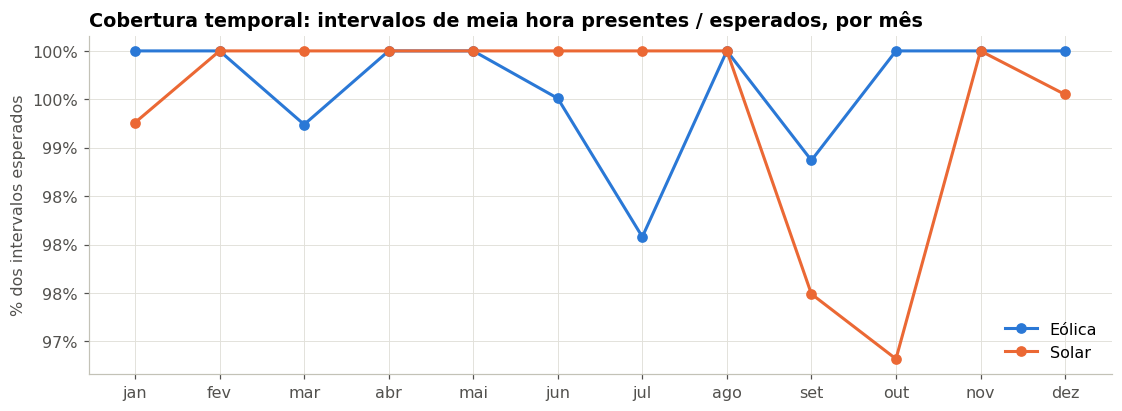

**Cobertura média: 99,6%** dos intervalos esperados (usinas × meias horas de cada mês). Usinas-mês com cobertura abaixo de 95%: 26. Cobertura parcial costuma indicar usinas que entraram ou saíram do conjunto no meio do mês; como o percentual cortado (P1) usa como denominador apenas os intervalos registrados, ele não é distorcido por essas lacunas.

,fonte,mes,usinas,registros,esperados,usinas_mes_abaixo_95,cobertura_pct
0,eolica,1,156,232128,232128,0,100.00
1,eolica,2,156,209664,209664,0,100.00
2,eolica,3,157,231840,233616,3,99.24
3,eolica,4,155,223200,223200,0,100.00
4,eolica,5,155,230640,230640,0,100.00
5,eolica,6,156,223536,224640,1,99.51
6,eolica,7,158,230592,235104,6,98.08
7,eolica,8,154,229152,229152,0,100.00
8,eolica,9,156,222096,224640,4,98.87
9,eolica,10,154,229152,229152,0,100.00


In [11]:
# Cobertura temporal: intervalos de meia hora presentes / esperados, por fonte, usina e mês
validos = (bronze.loc[bronze["din_instante"].notna() & (bronze["din_instante"].dt.year == ANO), ["fonte", "id_ons", "din_instante"]]
                 .assign(din_instante=lambda d: d["din_instante"].dt.floor("30min"))
                 .drop_duplicates())   # cada meia hora conta uma vez, mesmo repetida entre arquivos
contagem = (validos.assign(mes=validos["din_instante"].dt.month)
                   .groupby(["fonte", "id_ons", "mes"]).size().rename("registros").reset_index())
contagem["esperados"] = contagem["mes"].map(lambda m: pd.Period(f"{ANO}-{m:02d}").days_in_month * 48)
contagem["cobertura_pct"] = 100 * contagem["registros"] / contagem["esperados"]
cobertura = (contagem.groupby(["fonte", "mes"])
                     .agg(usinas=("id_ons", "nunique"), registros=("registros", "sum"), esperados=("esperados", "sum"),
                          usinas_mes_abaixo_95=("cobertura_pct", lambda s: int((s < 95).sum())))
                     .reset_index())
cobertura["cobertura_pct"] = (100 * cobertura["registros"] / cobertura["esperados"]).round(2)
salvar_tabela(cobertura, "q4_cobertura_mensal")
del validos, contagem

fig, eixo = plt.subplots(figsize=(12, 4))
for fonte, grupo in cobertura.groupby("fonte"):
    eixo.plot(grupo["mes"], grupo["cobertura_pct"], marker="o", lw=2, color=COR_FONTE[fonte], label=NOME_FONTE[fonte])
eixo.set_title("Cobertura temporal: intervalos de meia hora presentes / esperados, por mês")
eixo.set_ylabel("% dos intervalos esperados")
eixo.set_xticks(range(1, 13), ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
eixo.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: pct(v, 0)))
eixo.legend(loc="lower right")
salvar_figura(fig, "q4_cobertura_mensal")
plt.show()

cob_media = 100 * cobertura["registros"].sum() / cobertura["esperados"].sum()
mostrar(f"**Cobertura média: {pct(cob_media)}** dos intervalos esperados (usinas × meias horas de cada mês). "
        f"Usinas-mês com cobertura abaixo de 95%: {int(cobertura['usinas_mes_abaixo_95'].sum())}. "
        "Cobertura parcial costuma indicar usinas que entraram ou saíram do conjunto no meio do mês; como o percentual cortado "
        "(P1) usa como denominador apenas os intervalos registrados, ele não é distorcido por essas lacunas.")
display(cobertura)

### 5.1 Síntese da qualidade e tratamentos adotados

| Dimensão | O que foi examinado | Tratamento (regra da Seção 6) |
|---|---|---|
| **Unicidade** | Chave (fonte, usina, instante) | R04 — deduplicação |
| **Completude** | Campos obrigatórios; intervalos restritos sem motivo, sem energia não gerada ou sem referência; descrição da restrição (só existe a partir de set/2025) | R07, R09, R10 |
| **Consistência** | Energia não gerada publicada × recalculada; minutos por motivo × minutos restritos; geração × disponibilidade; atributos da usina que mudam no ano | R06, R08, R09, R10 |
| **Conformidade** | Domínios (motivos, origens, subsistemas, UFs); passo de 30 minutos; minutos entre 0 e 30; ano do recorte; deriva de esquema entre arquivos | R01, R03, R05, R13 |
| **Acurácia** | Valores negativos; energia não gerada maior que a referência | R05; valores oficiais mantidos e sinalizados |
| **Atualidade** | Meses publicados e data de modificação de cada arquivo (o ONS revisa meses já publicados) | Coleta idempotente por `ETag` (Seção 4) |

Os números de cada ocorrência estão nas tabelas acima e são exportados para `evidencias/tabelas/`.

## 6. Transformação (camada *silver*) e regras de negócio

As regras abaixo transformam a *bronze* em tabelas limpas (*silver*) e, na Seção 7, no modelo dimensional (*gold*). Cada regra aplicada registra **quantas linhas afetou** num log de transformações. O log é gravado no Drive e carregado no BigQuery (`meta_log_transformacoes`), e compõe a **linhagem** dos dados.

| Regra | Camada | O que faz | Por quê |
|---|---|---|---|
| **R01** | silver | Tipagem explícita das 24 colunas (instantes, números decimais, inteiros e textos). Valores não conversíveis viram nulo e são contados. | Unifica os tipos entre arquivos mensais (deriva de esquema, Seção 5). |
| **R02** | silver | Padronização de texto: códigos (motivo, origem, subsistema, UF) em maiúsculas e sem espaços; nomes com espaços simples. | "ene " e "ENE" são o mesmo motivo. |
| **R03** | silver | Instante alinhado ao início da meia hora. | A base é semi-horária; um instante fora do passo quebraria a junção com a `dim_horario` e a detecção de eventos. |
| **R04** | silver | Deduplicação pela chave (fonte, usina, instante), mantendo o registro do arquivo modificado mais recentemente. | O mesmo intervalo pode aparecer em dois arquivos; a versão mais nova reflete a revisão do ONS. |
| **R05** | silver | Potência negativa e minutos fora de 0 a 30 viram nulo. | Geração negativa é consumo interno da usina (por exemplo, a solar à noite), não geração; nas demais colunas, um negativo é erro. Não existem mais de 30 minutos numa meia hora. |
| **R06** | silver | **Intervalo restrito** = minutos restritos > 0, **ou** motivo informado, **ou** energia não gerada apurada > 0. | Uma única evidência de restrição basta; as três colunas às vezes discordam (Seção 5). |
| **R07** | silver | **Energia cortada (MWmed)** = energia não gerada apurada pelo ONS (GNRa). Se ela faltar num intervalo restrito: max(0, referência − geração). Sem as duas: 0. Fora de restrição: 0. | A GNRa é o valor oficial; o recálculo segue a definição do próprio ONS e só cobre lacunas. Zerar o que não dá para calcular **subestima** o corte (escolha conservadora). |
| **R08** | silver | Conversão de potência média em energia: **MWh = MWmed × 0,5 h**. Energia potencial = gerada + cortada. Geração acima da disponibilidade é sinalizada. | Somar MWmed de meias horas não tem significado físico; somar MWh tem. |
| **R09** | silver | **Rateio da energia cortada por motivo**, pela proporção dos minutos REL, CNF e ENE do intervalo. Minutos restritos além da soma desses três vão para PAR (que não tem coluna de minutos), se ele for o motivo informado, ou para "NI" (não informado). Sem minutos por motivo, toda a energia vai ao motivo informado; sem motivo válido, a "NI". | Uma meia hora pode ter mais de um motivo; o rateio mantém a soma por motivo igual ao total cortado. |
| **R10** | silver | Cadastro de usinas: para cada usina, o atributo informado mais recentemente (estado, subsistema, agente, ponto de conexão). Nome nulo → `id_ons`. Usinas com atributo alterado no ano recebem um indicador. | Dimensão do tipo 1 (sobrescreve) com rastreabilidade das mudanças. |
| **R11** | gold | **Grão da `fato_restricao` = usina × meia hora.** Chaves substitutas: `sk_usina` (sequencial), `sk_data` (AAAAMMDD), `sk_horario` (HHMM) e `sk_restricao` (motivo × origem). | Grão mais fino da fonte: permite somar por qualquer recorte sem perder informação. |
| **R12** | gold | **Evento de corte** = sequência contínua de meias horas restritas da mesma usina. Duração = nº de intervalos × 0,5 h. Motivo e origem predominantes = os de maior energia cortada no evento (sem energia, os do primeiro intervalo). | P5 pergunta por duração, que não existe no grão semi-horário. |
| **R13** | silver | Recorte: só registros de 2025 com usina e instante válidos. | Escopo do MVP (Seção 1.5). |
| **R14** | gold | Calendário: **dia útil** = nem fim de semana nem feriado nacional (fixos e móveis, calculados a partir da Páscoa). Janela do meio-dia = 09h00 a 15h59. | P4 compara dias úteis com fins de semana e feriados, quando a carga é menor. |

In [12]:
LOG = []

def registrar(regra, camada, tabela, descricao, afetadas, total):
    LOG.append({"regra": regra, "camada": camada, "tabela": tabela, "descricao": descricao,
                "linhas_afetadas": int(afetadas), "linhas_total": int(total),
                "executado_em": AGORA.strftime("%Y-%m-%d %H:%M:%S")})

def alterados(antes, depois):
    return int((antes.astype("string") != depois.astype("string")).fillna(False).astype(bool).sum())

from email.utils import parsedate_to_datetime
def instante_http(texto):
    try:
        return parsedate_to_datetime(texto).timestamp()
    except Exception:
        return 0.0

n_bronze = len(bronze)
registrar("R01", "silver", "restricoes", "Tipagem explícita das 24 colunas (contagem = valores não conversíveis → nulo)",
          sum(nao_convertidos.values()), n_bronze)

# R02 — padronização de texto (aplicada aos valores distintos e mapeada de volta: economiza memória e tempo)
def padronizar(serie, funcao):
    unicos = pd.Series(serie.dropna().unique(), dtype="string")
    return serie.map(dict(zip(unicos, funcao(unicos)))).astype("string")

for coluna in ["cod_razaorestricao", "cod_origemrestricao", "id_subsistema", "id_estado"]:
    novo = padronizar(bronze[coluna], lambda s: s.str.upper().str.replace(r"\s+", "", regex=True))
    registrar("R02", "silver", "restricoes", f"Código em maiúsculas e sem espaços: {coluna}", alterados(bronze[coluna], novo), n_bronze)
    bronze[coluna] = novo
for coluna in ["id_ons", "ceg", "id_pontoconexao", "nom_usina", "nom_estado", "nom_subsistema", "nom_pontoconexao", "nom_agenteoperador"]:
    novo = padronizar(bronze[coluna], lambda s: s.str.replace(r"\s+", " ", regex=True).str.strip())
    registrar("R02", "silver", "restricoes", f"Espaços extras removidos: {coluna}", alterados(bronze[coluna], novo), n_bronze)
    bronze[coluna] = novo

# R03 — alinhamento ao início da meia hora
alinhado = bronze["din_instante"].dt.floor("30min")
registrar("R03", "silver", "restricoes", "Instante alinhado ao início da meia hora",
          ((alinhado != bronze["din_instante"]) & bronze["din_instante"].notna()).sum(), n_bronze)
bronze["din_instante"] = alinhado
del alinhado

# R13 — recorte do escopo
valido = bronze["din_instante"].notna() & (bronze["din_instante"].dt.year == ANO) & bronze["id_ons"].notna()
registrar("R13", "silver", "restricoes", f"Descarte de registros fora de {ANO}, sem instante ou sem usina", (~valido).sum(), n_bronze)
bronze.drop(index=bronze.index[~valido.to_numpy()], inplace=True)

# R04 — deduplicação: vence o arquivo modificado mais recentemente
arquivos = [r for r in registros if r.get("linhas")]
ordem = {r["arquivo"]: i for i, r in enumerate(sorted(arquivos, key=lambda r: (instante_http(r["last_modified"]), r["arquivo"])))}
CHAVE = ["fonte", "id_ons", "din_instante"]
bronze["_ordem_arquivo"] = bronze["arquivo_origem"].map(ordem)
antigo = bronze["_ordem_arquivo"] < bronze.groupby(CHAVE)["_ordem_arquivo"].transform("max")
registrar("R04", "silver", "restricoes", "Duplicatas entre arquivos: mantida a versão do arquivo modificado mais recentemente",
          antigo.sum(), len(bronze))
bronze.drop(index=bronze.index[antigo.to_numpy()], inplace=True)
# Duplicatas no mesmo arquivo (inclui instantes que caíram na mesma meia hora após R03): fica o registro com mais minutos restritos
bronze["_min_ordem"] = bronze["num_minutos_restricao"].fillna(-1).astype("float64")
bronze["_gnr_ordem"] = bronze["val_geracaonaorealizadaapurada"].fillna(-1)
bronze.sort_values(CHAVE + ["_min_ordem", "_gnr_ordem"], ascending=[True, True, True, False, False], inplace=True)
duplicado = bronze.duplicated(CHAVE, keep="first")
registrar("R04", "silver", "restricoes", "Duplicatas no mesmo arquivo: mantido o registro com mais minutos restritos e maior GNRa",
          duplicado.sum(), len(bronze))
if duplicado.mean() > 0.001:
    print(f"ATENÇÃO: {num(int(duplicado.sum()))} registros repetidos no mesmo arquivo ({pct(100 * duplicado.mean(), 2)}). "
          "Se o ONS passar a publicar uma linha por restrição, esta regra deve somar as linhas em vez de descartá-las.")
bronze.drop(index=bronze.index[duplicado.to_numpy()], inplace=True)
bronze.drop(columns=["_min_ordem", "_gnr_ordem"], inplace=True)
bronze.reset_index(drop=True, inplace=True)
n = len(bronze)

# R05 — valores fisicamente impossíveis → nulo
for coluna in ["val_geracao", "val_geracaolimitada", "val_disponibilidade", "val_geracaoreferencia",
               "val_geracaoreferenciafinal", "val_geracaonaorealizadaapurada"]:
    negativo = bronze[coluna] < 0
    registrar("R05", "silver", "restricoes", f"Potência negativa → nulo: {coluna}", negativo.sum(), n)
    bronze.loc[negativo, coluna] = np.nan
for coluna in ["num_minutos_rel", "num_minutos_cnf", "num_minutos_ene", "num_minutos_restricao"]:
    fora = ((bronze[coluna] < 0) | (bronze[coluna] > 30)).fillna(False).astype(bool)
    registrar("R05", "silver", "restricoes", f"Minutos fora de 0 a 30 → nulo: {coluna}", fora.sum(), n)
    bronze.loc[fora, coluna] = pd.NA

In [13]:
# R06 — intervalo restrito
min_motivos = bronze[["num_minutos_rel", "num_minutos_cnf", "num_minutos_ene"]].fillna(0).astype("float64").to_numpy()
soma_min_motivos = min_motivos.sum(axis=1)
min_total = bronze["num_minutos_restricao"].fillna(0).astype("float64").to_numpy()
codigo_publicado = bronze["cod_razaorestricao"]
gnr_publicada = bronze["val_geracaonaorealizadaapurada"]
restrito = ((min_total > 0) | (soma_min_motivos > 0) | codigo_publicado.notna().to_numpy()
            | (gnr_publicada.fillna(0).to_numpy() > 0))
registrar("R06", "silver", "restricoes", "Intervalos classificados como restritos", restrito.sum(), n)
so_por_energia = restrito & (min_total == 0) & (soma_min_motivos == 0) & codigo_publicado.isna().to_numpy()
registrar("R06", "silver", "restricoes", "…dos quais restritos apenas pela energia não gerada (sem minutos nem motivo)", so_por_energia.sum(), n)

# R07 — energia cortada em MWmed
referencia = bronze["val_geracaoreferenciafinal"].fillna(bronze["val_geracaoreferencia"])
recalculada = (referencia - bronze["val_geracao"]).clip(lower=0)
corte_mw = np.where(restrito, gnr_publicada.fillna(recalculada).fillna(0).to_numpy(), 0.0)
flag_recalculada = restrito & gnr_publicada.isna().to_numpy() & recalculada.notna().to_numpy()
registrar("R07", "silver", "restricoes", "GNRa ausente em intervalo restrito → recalculada como max(0, referência − geração)",
          flag_recalculada.sum(), int(restrito.sum()))
registrar("R07", "silver", "restricoes", "Intervalo restrito sem GNRa e sem referência → energia cortada = 0 (conservador)",
          (restrito & gnr_publicada.isna().to_numpy() & recalculada.isna().to_numpy()).sum(), int(restrito.sum()))

# R08 — MWmed → MWh e indicador de geração acima da disponibilidade
energia_cortada = 0.5 * corte_mw
energia_gerada = 0.5 * bronze["val_geracao"].to_numpy()
acima_disp = (bronze["val_geracao"] > bronze["val_disponibilidade"] + 1).to_numpy(dtype=bool, na_value=False)
registrar("R08", "silver", "restricoes", "Conversão MWmed → MWh (× 0,5 h) da geração e da energia cortada", n, n)
registrar("R08", "silver", "restricoes", "Geração acima da disponibilidade (> 1 MW) sinalizada", acima_disp.sum(), n)

# R09 — rateio por motivo
MOTIVOS = ["REL", "CNF", "ENE", "PAR", "NI"]
codigo_valido = codigo_publicado.where(codigo_publicado.isin(["REL", "CNF", "ENE", "PAR"]))
tem_minutos = soma_min_motivos > 0
# Minutos restritos sem motivo com coluna própria: vão para PAR quando PAR é o motivo informado; senão, para "NI"
residuo = np.where(tem_minutos, np.clip(min_total - soma_min_motivos, 0, None), 0.0)
divisor = np.where(tem_minutos, soma_min_motivos + residuo, 1.0)
e_par = (codigo_valido == "PAR").to_numpy(dtype=bool, na_value=False)
fracao = {}
for j, motivo in enumerate(["REL", "CNF", "ENE"]):
    fracao[motivo] = np.where(tem_minutos, min_motivos[:, j] / divisor, (codigo_valido == motivo).to_numpy(dtype=bool, na_value=False))
fracao["PAR"] = np.where(tem_minutos, np.where(e_par, residuo / divisor, 0.0), e_par)
fracao["NI"] = np.where(tem_minutos, np.where(e_par, 0.0, residuo / divisor), codigo_valido.isna().to_numpy())
registrar("R09", "silver", "restricoes", "Energia cortada rateada pelos minutos REL/CNF/ENE", (restrito & tem_minutos).sum(), int(restrito.sum()))
registrar("R09", "silver", "restricoes", "…com minutos restritos além de REL+CNF+ENE (parcela a PAR, se informado, ou a 'NI')",
          (restrito & (residuo > 0)).sum(), int(restrito.sum()))
registrar("R09", "silver", "restricoes", "Sem minutos por motivo: energia atribuída ao motivo informado",
          (restrito & ~tem_minutos & codigo_valido.notna().to_numpy()).sum(), int(restrito.sum()))
registrar("R09", "silver", "restricoes", "Sem minutos e sem motivo válido: energia atribuída a 'NI'",
          (restrito & ~tem_minutos & codigo_valido.isna().to_numpy()).sum(), int(restrito.sum()))

# Motivo e origem "principais" do intervalo (chave da dim_restricao): o publicado; sem ele, o de mais minutos
motivo_por_minutos = np.array(["REL", "CNF", "ENE"])[min_motivos.argmax(axis=1)]
motivo_principal = np.where(~restrito, "SEM",
                            np.where(codigo_valido.notna().to_numpy(), codigo_valido.fillna("").to_numpy(),
                                     np.where(tem_minutos, motivo_por_minutos, "NI")))
origem = bronze["cod_origemrestricao"].where(bronze["cod_origemrestricao"].isin(["LOC", "SIS"]))
origem_principal = np.where(~restrito, "SEM", origem.fillna("NI").to_numpy())

restricoes = pd.DataFrame({
    "fonte": bronze["fonte"].array,
    "id_ons": bronze["id_ons"].array,
    "din_instante": bronze["din_instante"].to_numpy(),
    "geracao_mwmed": bronze["val_geracao"].to_numpy(),
    "geracao_limitada_mwmed": bronze["val_geracaolimitada"].to_numpy(),
    "disponibilidade_mwmed": bronze["val_disponibilidade"].to_numpy(),
    "geracao_referencia_mwmed": referencia.to_numpy(),
    "geracao_nao_realizada_apurada_mwmed": gnr_publicada.to_numpy(),
    "minutos_restricao": bronze["num_minutos_restricao"].array,
    "minutos_rel": bronze["num_minutos_rel"].array,
    "minutos_cnf": bronze["num_minutos_cnf"].array,
    "minutos_ene": bronze["num_minutos_ene"].array,
    "cod_razao": motivo_principal,
    "cod_origem": origem_principal,
    "corte_mwmed": corte_mw,
    "energia_gerada_mwh": energia_gerada,
    "energia_cortada_mwh": energia_cortada,
    "energia_potencial_mwh": np.nan_to_num(energia_gerada, nan=0.0) + energia_cortada,
    **{f"energia_cortada_{m.lower()}_mwh": energia_cortada * fracao[m] for m in MOTIVOS},
    "flag_restrito": restrito,
    "flag_energia_recalculada": flag_recalculada,
    "flag_geracao_acima_disponibilidade": acima_disp,
})
diferenca_rateio = np.abs(restricoes[[f"energia_cortada_{m.lower()}_mwh" for m in MOTIVOS]].sum(axis=1) - restricoes["energia_cortada_mwh"]).max()
assert diferenca_rateio < 1e-6, f"Rateio por motivo não fecha com o total (diferença máxima {diferenca_rateio})"

In [14]:
# R10 — cadastro de usinas (atributo mais recente; a bronze já está ordenada por fonte, usina e instante)
CADASTRO = ["nom_usina", "ceg", "id_estado", "nom_estado", "id_subsistema", "nom_subsistema",
            "id_pontoconexao", "nom_pontoconexao", "nom_agenteoperador"]
grupo = bronze.groupby(["fonte", "id_ons"], sort=True)
usinas = grupo[CADASTRO].last()
usinas["potencia_disponivel_max_mw"] = grupo["val_disponibilidade"].max()
usinas["primeiro_registro"] = grupo["din_instante"].min()
usinas["ultimo_registro"] = grupo["din_instante"].max()
mudou = grupo[["id_estado", "id_subsistema", "nom_agenteoperador", "id_pontoconexao"]].nunique() > 1
usinas["flag_atributo_alterado"] = mudou.any(axis=1)
usinas["atributos_alterados"] = mudou.apply(lambda r: ", ".join(c for c in mudou.columns if r[c]), axis=1)
usinas["atributos_alterados"] = usinas["atributos_alterados"].mask(usinas["atributos_alterados"] == "")
usinas = usinas.reset_index()
sem_nome = usinas["nom_usina"].isna()
usinas["nom_usina"] = usinas["nom_usina"].fillna(usinas["id_ons"])
registrar("R10", "silver", "usinas", "Cadastro com o atributo mais recente de cada usina", len(usinas), len(usinas))
registrar("R10", "silver", "usinas", "Nome da usina nulo → id_ons", sem_nome.sum(), len(usinas))
registrar("R10", "silver", "usinas", "Usinas com estado, subsistema, agente ou ponto de conexão alterado no ano",
          usinas["flag_atributo_alterado"].sum(), len(usinas))

# A bronze tipada não é mais necessária: libera memória
del bronze, grupo, min_motivos, referencia, recalculada, corte_mw, energia_cortada, energia_gerada, fracao
gc.collect()

# Persistência da silver no Drive (um arquivo por fonte)
resumo_silver = []
for fonte in FONTES:
    parte = restricoes[restricoes["fonte"] == fonte]
    caminho = os.path.join(DIR["silver"], f"restricoes_{fonte}.parquet")
    parte.to_parquet(caminho, index=False)
    resumo_silver.append({"tabela": f"restricoes_{fonte}", "linhas": len(parte), "colunas": parte.shape[1],
                          "intervalos_restritos": int(parte["flag_restrito"].sum()),
                          "energia_cortada_gwh": round(parte["energia_cortada_mwh"].sum() / 1000, 1), "arquivo": caminho})
usinas.to_parquet(os.path.join(DIR["silver"], "usinas.parquet"), index=False)
resumo_silver.append({"tabela": "usinas", "linhas": len(usinas), "colunas": usinas.shape[1],
                      "arquivo": os.path.join(DIR["silver"], "usinas.parquet")})
mostrar(f"**Camada silver gravada no Drive.** {num(len(restricoes))} intervalos usina × meia hora, dos quais "
        f"{num(int(restricoes['flag_restrito'].sum()))} restritos ({pct(100 * restricoes['flag_restrito'].mean())}), "
        f"e {num(len(usinas))} usinas. O rateio por motivo fecha com o total cortado (diferença máxima {diferenca_rateio:.1e} MWh).")
display(pd.DataFrame(resumo_silver))

**Camada silver gravada no Drive.** 3.874.032 intervalos usina × meia hora, dos quais 1.432.229 restritos (37,0%), e 235 usinas. O rateio por motivo fecha com o total cortado (diferença máxima 5.7e-14 MWh).

,tabela,linhas,colunas,intervalos_restritos,energia_cortada_gwh,arquivo
0,restricoes_eolica,2712912,26,1121670.0,26216.9,/content/drive/MyDrive/mvp_cortes_renovaveis/silver/restricoes_eolica.parquet
1,restricoes_solar,1161120,26,310559.0,11000.4,/content/drive/MyDrive/mvp_cortes_renovaveis/silver/restricoes_solar.parquet
2,usinas,235,16,NaN,NaN,/content/drive/MyDrive/mvp_cortes_renovaveis/silver/usinas.parquet


## 7. Modelagem (camada *gold*) — modelo dimensional e Catálogo de Dados

### 7.1 Modelo escolhido

O Data Warehouse segue o **modelo dimensional de Kimball** na forma de uma **constelação de fatos**: duas tabelas fato compartilham quatro dimensões conformadas. Cada fato isolada é um esquema estrela. As dimensões são pequenas e foram mantidas desnormalizadas; um *snowflake* (por exemplo, separar estado e subsistema da usina) só acrescentaria junções sem ganho analítico.

**Por que duas fatos.** As perguntas P1 a P4 somam energia por usina, local, motivo e horário, e pedem o grão mais fino da fonte. A P5 pergunta **quanto duram** os cortes, e a duração não existe numa meia hora isolada: ela é uma propriedade de uma sequência de meias horas. Calcular eventos em toda consulta exigiria funções de janela pesadas e fáceis de errar; materializar o evento numa segunda fato torna a regra (R12) única, documentada e auditável.

| Tabela | Tipo | Grão / conteúdo |
|---|---|---|
| `fato_restricao` | Fato transacional | **Uma linha por usina × meia hora.** Medidas **aditivas**: `energia_gerada_mwh`, `energia_cortada_mwh`, `energia_potencial_mwh` e as cinco parcelas por motivo (`energia_cortada_*_mwh`). **Não aditivas** (médias de potência, não somar): as colunas `*_mwmed`. Indicadores `flag_*`. |
| `fato_evento_corte` | Fato agregada (eventos) | **Uma linha por evento contínuo de corte de uma usina.** Duração, energia cortada, potência máxima cortada e motivo predominante. |
| `dim_usina` | Dimensão | Uma usina (ou conjunto de usinas) por linha: fonte, UF, subsistema, ponto de conexão, agente e indicador de alteração cadastral. |
| `dim_data` | Dimensão | Um dia por linha, com dia útil, sábado, domingo ou feriado. |
| `dim_horario` | Dimensão | Uma meia hora do dia por linha (48 linhas), com período do dia e janela do meio-dia. |
| `dim_restricao` | Dimensão | Uma combinação motivo × origem por linha, com a natureza do motivo e a alavanca de política associada. |

**Unidade de medida.** O ONS publica potências médias de cada meia hora (MWmed). A *gold* guarda esses valores como vieram e acrescenta a energia em MWh (MWmed × 0,5 h, regra R08). Só a energia é somada nas análises.

Além do modelo, o dataset do BigQuery recebe as tabelas de metadados `meta_catalogo_dados`, `meta_log_transformacoes`, `meta_coleta`, `meta_perfil_qualidade` e `meta_verificacoes_qualidade`.

In [15]:
NOMES_MESES = ["janeiro", "fevereiro", "março", "abril", "maio", "junho", "julho", "agosto",
               "setembro", "outubro", "novembro", "dezembro"]
NOMES_DIAS = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira", "sábado", "domingo"]
TIPOS_DIA = ["dia útil", "sábado", "domingo ou feriado"]
PERIODOS_DIA = ["madrugada", "manhã", "tarde", "noite"]
RAZOES = {  # código: (nome, natureza, alavanca de política)
    "REL": ("Indisponibilidade externa", "elétrica", "Transmissão: disponibilidade e reforço da rede"),
    "CNF": ("Confiabilidade elétrica", "elétrica", "Transmissão: reforço da rede e controle de tensão"),
    "ENE": ("Energética (excesso de oferta)", "energética", "Gestão de oferta e demanda; armazenamento"),
    "PAR": ("Parecer de acesso", "acesso", "Reforço do acesso previsto no parecer"),
    "NI": ("Não informado", "não informado", "Melhorar o registro do motivo"),
    "SEM": ("Sem restrição", "sem restrição", "Não se aplica"),
}
ORIGENS = {"LOC": "Local", "SIS": "Sistêmica", "NI": "Não informada", "SEM": "Sem restrição"}
COD_RAZOES, COD_ORIGENS = list(RAZOES), list(ORIGENS)
SK_HORARIOS = [h * 100 + m for h in range(24) for m in (0, 30)]
limites = sorted({0, 1, 2, 4, 8, 12, DURACAO_BATERIA_H})
FAIXAS_DURACAO = ["até 1 h"] + [f"{a} a {b} h" for a, b in zip(limites[1:-1], limites[2:])] + [f"mais de {limites[-1]} h"]
FAIXAS_LIMITES = limites + [np.inf]

def chave_texto(*colunas):
    resultado = colunas[0].astype(str)
    for c in colunas[1:]:
        resultado = resultado + "|" + c.astype(str)
    return resultado

# ---------- dim_usina (R11) ----------
dim_usina = usinas.rename(columns={"id_estado": "uf"}).sort_values(["fonte", "id_ons"]).reset_index(drop=True)
dim_usina.insert(0, "sk_usina", np.arange(1, len(dim_usina) + 1))
dim_usina["nome_fonte"] = dim_usina["fonte"].map({"eolica": "Eólica", "solar": "Solar fotovoltaica"})
registrar("R11", "gold", "dim_usina", "Chave substituta sequencial por (fonte, id_ons)", len(dim_usina), len(dim_usina))

# ---------- dim_data (R14) ----------
def pascoa(ano):   # algoritmo de Meeus/Jones/Butcher (calendário gregoriano)
    a, (b, c) = ano % 19, divmod(ano, 100)
    d, e = divmod(b, 4)
    g = (b - (b + 8) // 25 + 1) // 3
    h = (19 * a + b - d - g + 15) % 30
    i, k = divmod(c, 4)
    l = (32 + 2 * e + 2 * i - h - k) % 7
    m = (a + 11 * h + 22 * l) // 451
    return dt.date(ano, (h + l - 7 * m + 114) // 31, (h + l - 7 * m + 114) % 31 + 1)

def feriados_nacionais(ano):
    p = pascoa(ano)
    fixos = {(1, 1): "Confraternização Universal", (4, 21): "Tiradentes", (5, 1): "Dia do Trabalho",
             (9, 7): "Independência do Brasil", (10, 12): "Nossa Senhora Aparecida", (11, 2): "Finados",
             (11, 15): "Proclamação da República", (11, 20): "Dia Nacional de Zumbi e da Consciência Negra",
             (12, 25): "Natal"}
    datas = {dt.date(ano, m, d): nome for (m, d), nome in fixos.items()}
    datas.update({p - dt.timedelta(days=48): "Carnaval (ponto facultativo)", p - dt.timedelta(days=47): "Carnaval (ponto facultativo)",
                  p - dt.timedelta(days=2): "Sexta-feira Santa", p + dt.timedelta(days=60): "Corpus Christi (ponto facultativo)"})
    return datas

FERIADOS = feriados_nacionais(ANO)
dim_data = pd.DataFrame({"data": pd.date_range(f"{ANO}-01-01", f"{ANO}-12-31", freq="D")})
dim_data["sk_data"] = (dim_data["data"].dt.year * 10000 + dim_data["data"].dt.month * 100 + dim_data["data"].dt.day).astype("int64")
dim_data["ano"] = dim_data["data"].dt.year
dim_data["mes"] = dim_data["data"].dt.month
dim_data["semestre"] = np.where(dim_data["mes"] <= 6, 1, 2)
dim_data["trimestre"] = dim_data["data"].dt.quarter
dim_data["nome_mes"] = dim_data["mes"].map(lambda m: NOMES_MESES[m - 1])
dim_data["dia"] = dim_data["data"].dt.day
dim_data["dia_semana"] = dim_data["data"].dt.dayofweek + 1
dim_data["nome_dia_semana"] = dim_data["dia_semana"].map(lambda d: NOMES_DIAS[d - 1])
dim_data["fim_de_semana"] = dim_data["dia_semana"] >= 6
dim_data["nome_feriado"] = dim_data["data"].dt.date.map(FERIADOS)
dim_data["feriado"] = dim_data["nome_feriado"].notna()
dim_data["dia_util"] = ~dim_data["fim_de_semana"] & ~dim_data["feriado"]
dim_data["tipo_dia"] = np.where(dim_data["dia_util"], "dia útil",
                                np.where((dim_data["dia_semana"] == 6) & ~dim_data["feriado"], "sábado", "domingo ou feriado"))
registrar("R14", "gold", "dim_data", "Feriados nacionais e pontos facultativos marcados (fixos + móveis pela Páscoa)",
          dim_data["feriado"].sum(), len(dim_data))

# ---------- dim_horario (R14) ----------
dim_horario = pd.DataFrame({"sk_horario": SK_HORARIOS})
dim_horario["hora"] = dim_horario["sk_horario"] // 100
dim_horario["minuto"] = dim_horario["sk_horario"] % 100
dim_horario["hora_minuto"] = dim_horario["hora"].map("{:02d}".format) + ":" + dim_horario["minuto"].map("{:02d}".format)
dim_horario["indice_meia_hora"] = np.arange(48)
dim_horario["periodo_dia"] = pd.cut(dim_horario["hora"], [-1, 5, 11, 17, 23], labels=PERIODOS_DIA).astype(str)
dim_horario["janela_meio_dia"] = dim_horario["hora"].between(HORA_INICIO_MEIO_DIA, HORA_FIM_MEIO_DIA - 1)
registrar("R14", "gold", "dim_horario", f"Janela do meio-dia ({HORA_INICIO_MEIO_DIA:02d}h00–{HORA_FIM_MEIO_DIA - 1:02d}h59)",
          dim_horario["janela_meio_dia"].sum(), len(dim_horario))

# ---------- dim_restricao (R11) ----------
combinacoes = [(r, o) for r in ["REL", "CNF", "ENE", "PAR", "NI"] for o in ["LOC", "SIS", "NI"]] + [("SEM", "SEM")]
dim_restricao = pd.DataFrame(combinacoes, columns=["cod_razao", "cod_origem"])
dim_restricao.insert(0, "sk_restricao", np.arange(1, len(dim_restricao) + 1))
dim_restricao["nome_razao"] = dim_restricao["cod_razao"].map(lambda c: RAZOES[c][0])
dim_restricao["natureza"] = dim_restricao["cod_razao"].map(lambda c: RAZOES[c][1])
dim_restricao["alavanca"] = dim_restricao["cod_razao"].map(lambda c: RAZOES[c][2])
dim_restricao["nome_origem"] = dim_restricao["cod_origem"].map(ORIGENS)
dim_restricao["flag_restricao"] = dim_restricao["cod_razao"] != "SEM"
mapa_restricao = dict(zip(chave_texto(dim_restricao["cod_razao"], dim_restricao["cod_origem"]), dim_restricao["sk_restricao"]))

# ---------- fato_restricao (R11) ----------
mapa_usina = dict(zip(chave_texto(dim_usina["fonte"], dim_usina["id_ons"]), dim_usina["sk_usina"]))
restricoes["sk_usina"] = chave_texto(restricoes["fonte"], restricoes["id_ons"]).map(mapa_usina).astype("int64")
instante = restricoes["din_instante"]
restricoes["sk_data"] = (instante.dt.year * 10000 + instante.dt.month * 100 + instante.dt.day).astype("int64")
restricoes["sk_horario"] = (instante.dt.hour * 100 + instante.dt.minute).astype("int64")
restricoes["sk_restricao"] = chave_texto(restricoes["cod_razao"], restricoes["cod_origem"]).map(mapa_restricao).astype("int64")
registrar("R11", "gold", "fato_restricao", "Grão usina × meia hora com chaves substitutas", len(restricoes), len(restricoes))

# ---------- fato_evento_corte (R12) ----------
COLS_MOTIVO = [f"energia_cortada_{m.lower()}_mwh" for m in MOTIVOS]
r = restricoes.loc[restricoes["flag_restrito"], ["sk_usina", "din_instante", "corte_mwmed", "energia_cortada_mwh",
                                                 "minutos_restricao", "cod_razao", "cod_origem"] + COLS_MOTIVO]
r = r.sort_values(["sk_usina", "din_instante"])
novo_evento = (r["sk_usina"].diff() != 0) | (r["din_instante"].diff() != pd.Timedelta(minutes=30))
r["evento"] = novo_evento.cumsum().to_numpy()
for o in ["LOC", "SIS", "NI"]:
    r[f"origem_{o}"] = np.where(r["cod_origem"] == o, r["energia_cortada_mwh"], 0.0)
ev = r.groupby("evento", sort=True).agg(
    sk_usina=("sk_usina", "first"), inicio=("din_instante", "min"), ultimo=("din_instante", "max"),
    intervalos=("din_instante", "size"), minutos_restritos=("minutos_restricao", "sum"),
    energia_cortada_mwh=("energia_cortada_mwh", "sum"), corte_maximo_mw=("corte_mwmed", "max"),
    motivo_primeiro=("cod_razao", "first"), origem_primeira=("cod_origem", "first"),
    **{c: (c, "sum") for c in COLS_MOTIVO + ["origem_LOC", "origem_SIS", "origem_NI"]},
).reset_index(drop=True)
del r
com_energia = ev["energia_cortada_mwh"].to_numpy() > 0
motivo = np.array(MOTIVOS)[ev[COLS_MOTIVO].to_numpy().argmax(axis=1)]
origem_ev = np.array(["LOC", "SIS", "NI"])[ev[["origem_LOC", "origem_SIS", "origem_NI"]].to_numpy().argmax(axis=1)]
ev["motivo"] = np.where(com_energia, motivo, ev["motivo_primeiro"].astype(str))
ev["origem"] = np.where(com_energia, origem_ev, ev["origem_primeira"].astype(str))
ev["fim"] = ev["ultimo"] + pd.Timedelta(minutes=30)
ev["duracao_h"] = 0.5 * ev["intervalos"]
ev["faixa_duracao"] = pd.cut(ev["duracao_h"], FAIXAS_LIMITES, labels=FAIXAS_DURACAO, right=True).astype(str)
ev["flag_cabe_bateria"] = ev["duracao_h"] <= DURACAO_BATERIA_H
ev["sk_evento"] = np.arange(1, len(ev) + 1)
ev["sk_data_inicio"] = (ev["inicio"].dt.year * 10000 + ev["inicio"].dt.month * 100 + ev["inicio"].dt.day).astype("int64")
ev["sk_horario_inicio"] = (ev["inicio"].dt.hour * 100 + ev["inicio"].dt.minute).astype("int64")
ev["sk_restricao_predominante"] = chave_texto(ev["motivo"], ev["origem"]).map(mapa_restricao).astype("int64")
fato_evento_corte = ev
registrar("R12", "gold", "fato_evento_corte", "Meias horas restritas consecutivas agrupadas em eventos",
          int(restricoes["flag_restrito"].sum()) - len(ev), int(restricoes["flag_restrito"].sum()))
registrar("R12", "gold", "fato_evento_corte", "Eventos sem energia cortada (motivo/origem do primeiro intervalo)",
          (~com_energia).sum(), len(ev))

mostrar(f"""**Modelo dimensional montado:** `fato_restricao` com {num(len(restricoes))} linhas (usina × meia hora) ·
`fato_evento_corte` com {num(len(fato_evento_corte))} eventos ({num(int(com_energia.sum()))} com energia cortada) ·
`dim_usina` com {num(len(dim_usina))} usinas · `dim_data` com {len(dim_data)} dias ({int(dim_data['feriado'].sum())} feriados ou pontos facultativos) ·
`dim_horario` com {len(dim_horario)} meias horas · `dim_restricao` com {len(dim_restricao)} combinações motivo × origem.""")

**Modelo dimensional montado:** `fato_restricao` com 3.874.032 linhas (usina × meia hora) ·
`fato_evento_corte` com 67.782 eventos (64.439 com energia cortada) ·
`dim_usina` com 235 usinas · `dim_data` com 365 dias (13 feriados ou pontos facultativos) ·
`dim_horario` com 48 meias horas · `dim_restricao` com 16 combinações motivo × origem.

### 7.2 Catálogo de Dados

O catálogo é definido **uma única vez**, na célula abaixo, e dele saem três produtos:

1. a **documentação** (`catalogo/catalogo_dados.md` e `.csv`, no repositório e no Drive);
2. o **esquema do BigQuery**: tipo, obrigatoriedade (`REQUIRED`/`NULLABLE`) e descrição de cada coluna, visível no console e relida na Seção 8;
3. a **validação automática** dos dados contra os domínios declarados (Seção 7.3).

Para cada atributo, o catálogo registra nome, tipo, descrição, **domínio** (faixa mínima e máxima esperada, lista de valores válidos ou padrão), obrigatoriedade, significado do nulo e **linhagem** (coluna de origem no ONS e regras aplicadas).

In [16]:
#@title Catálogo de Dados (definição única: gera documentação, esquema do BigQuery e validação)
INICIO_ANO, FIM_ANO = f"{ANO}-01-01", f"{ANO}-12-31"
SK_DATA_MIN, SK_DATA_MAX = ANO * 10000 + 101, ANO * 10000 + 1231
_catalogo = []

def atributo(tabela, nome, tipo, logico, descricao, dominio=None, obrigatorio=True, nulo="Não admite nulo.", linhagem=""):
    """dominio: ("faixa", min, max) | ("valores", [...]) | ("padrao", regex) | None"""
    _catalogo.append(dict(tabela=tabela, atributo=nome, tipo_bigquery=tipo, tipo_logico=logico,
                          descricao=descricao, dominio=dominio, obrigatorio=obrigatorio,
                          significado_nulo=nulo, linhagem=linhagem))

ORIGEM = "Colunas do ONS (restricao_coff_eolica_tm / restricao_coff_fotovoltaica_tm): "
BOOL = ("valores", [True, False])

# ---------------- dim_usina ----------------
T = "dim_usina"
atributo(T, "sk_usina", "INT64", "numérico", "Chave substituta da usina (PK).", ("faixa", 1, 9999), linhagem="Sequencial por (fonte, id_ons) (R11).")
atributo(T, "id_ons", "STRING", "texto", "Identificador da usina (ou conjunto de usinas) no ONS (chave natural, junto com a fonte).", None, linhagem=ORIGEM + "id_ons (R02).")
atributo(T, "nom_usina", "STRING", "texto", "Nome da usina ou do conjunto de usinas.", None, linhagem=ORIGEM + "nom_usina, valor mais recente; nulo → id_ons (R10).")
atributo(T, "fonte", "STRING", "categórico", "Fonte de geração (código).", ("valores", ["eolica", "solar"]), linhagem="Conjunto de dados de origem (eólica ou fotovoltaica).")
atributo(T, "nome_fonte", "STRING", "categórico", "Fonte de geração (nome).", ("valores", ["Eólica", "Solar fotovoltaica"]), linhagem="Derivado de `fonte`.")
atributo(T, "ceg", "STRING", "texto", "Código Único de Empreendimentos de Geração (CEG) da ANEEL.", None, obrigatorio=False, nulo="Conjunto de usinas sem CEG único ou CEG não informado.", linhagem=ORIGEM + "ceg, valor mais recente (R10).")
atributo(T, "uf", "STRING", "categórico", "Unidade federativa onde a usina está (sigla).", ("valores", UFS), obrigatorio=False, nulo="UF não informada na origem.", linhagem=ORIGEM + "id_estado, valor mais recente (R02, R10).")
atributo(T, "nom_estado", "STRING", "texto", "Nome da unidade federativa.", None, obrigatorio=False, nulo="UF não informada na origem.", linhagem=ORIGEM + "nom_estado (R10).")
atributo(T, "id_subsistema", "STRING", "categórico", "Subsistema do SIN: N (Norte), NE (Nordeste), SE (Sudeste/Centro-Oeste), S (Sul).", ("valores", ["N", "NE", "SE", "S"]), obrigatorio=False, nulo="Subsistema não informado na origem.", linhagem=ORIGEM + "id_subsistema (R02, R10).")
atributo(T, "nom_subsistema", "STRING", "texto", "Nome do subsistema.", None, obrigatorio=False, nulo="Subsistema não informado na origem.", linhagem=ORIGEM + "nom_subsistema (R10).")
atributo(T, "id_pontoconexao", "STRING", "texto", "Identificador do ponto de conexão da usina à rede.", None, obrigatorio=False, nulo="Ponto de conexão não informado.", linhagem=ORIGEM + "id_pontoconexao (R10).")
atributo(T, "nom_pontoconexao", "STRING", "texto", "Nome do ponto de conexão (subestação/barramento).", None, obrigatorio=False, nulo="Ponto de conexão não informado.", linhagem=ORIGEM + "nom_pontoconexao (R10).")
atributo(T, "nom_agenteoperador", "STRING", "texto", "Agente responsável pela operação da usina (pessoa jurídica).", None, obrigatorio=False, nulo="Agente não informado.", linhagem=ORIGEM + "nom_agenteoperador (R10).")
atributo(T, "potencia_disponivel_max_mw", "FLOAT64", "numérico", "Maior disponibilidade declarada no ano (MW). Aproxima a capacidade operativa.", ("faixa", 0, 2500), obrigatorio=False, nulo="Disponibilidade nunca informada.", linhagem="MAX(val_disponibilidade) por usina (R10).")
atributo(T, "primeiro_registro", "DATETIME", "data", "Primeiro intervalo registrado da usina no ano.", ("faixa", INICIO_ANO, FIM_ANO), linhagem="MIN(din_instante) por usina.")
atributo(T, "ultimo_registro", "DATETIME", "data", "Último intervalo registrado da usina no ano.", ("faixa", INICIO_ANO, FIM_ANO), linhagem="MAX(din_instante) por usina.")
atributo(T, "flag_atributo_alterado", "BOOL", "booleano", "Verdadeiro se estado, subsistema, agente ou ponto de conexão mudou durante o ano.", BOOL, linhagem="Contagem de valores distintos por usina (R10).")
atributo(T, "atributos_alterados", "STRING", "texto", "Lista dos atributos que mudaram no ano.", None, obrigatorio=False, nulo="Nenhum atributo alterado.", linhagem="Regra R10.")

# ---------------- dim_data ----------------
T = "dim_data"
atributo(T, "sk_data", "INT64", "numérico", "Chave substituta da data, no formato AAAAMMDD (PK).", ("faixa", SK_DATA_MIN, SK_DATA_MAX), linhagem="Gerada a partir de `data` (R11).")
atributo(T, "data", "DATE", "data", "Data do calendário.", ("faixa", INICIO_ANO, FIM_ANO), linhagem="Calendário contínuo do ano analisado.")
atributo(T, "ano", "INT64", "numérico", "Ano civil.", ("faixa", ANO, ANO), linhagem="Derivado de `data`.")
atributo(T, "semestre", "INT64", "numérico", "Semestre do ano.", ("faixa", 1, 2), linhagem="Derivado de `data`.")
atributo(T, "trimestre", "INT64", "numérico", "Trimestre do ano.", ("faixa", 1, 4), linhagem="Derivado de `data`.")
atributo(T, "mes", "INT64", "numérico", "Mês do ano.", ("faixa", 1, 12), linhagem="Derivado de `data`.")
atributo(T, "nome_mes", "STRING", "categórico", "Nome do mês em português.", ("valores", NOMES_MESES), linhagem="Derivado de `data`.")
atributo(T, "dia", "INT64", "numérico", "Dia do mês.", ("faixa", 1, 31), linhagem="Derivado de `data`.")
atributo(T, "dia_semana", "INT64", "numérico", "Dia da semana ISO 8601 (1 = segunda-feira … 7 = domingo).", ("faixa", 1, 7), linhagem="Derivado de `data`.")
atributo(T, "nome_dia_semana", "STRING", "categórico", "Nome do dia da semana em português.", ("valores", NOMES_DIAS), linhagem="Derivado de `data`.")
atributo(T, "fim_de_semana", "BOOL", "booleano", "Verdadeiro para sábado e domingo.", BOOL, linhagem="Derivado de `dia_semana`.")
atributo(T, "feriado", "BOOL", "booleano", "Verdadeiro em feriado nacional ou ponto facultativo nacional (Carnaval, Corpus Christi).", BOOL, linhagem="Feriados fixos e móveis (Páscoa) (R14).")
atributo(T, "nome_feriado", "STRING", "texto", "Nome do feriado ou ponto facultativo.", None, obrigatorio=False, nulo="Dia sem feriado.", linhagem="Regra R14.")
atributo(T, "dia_util", "BOOL", "booleano", "Verdadeiro se não é fim de semana nem feriado.", BOOL, linhagem="Regra R14.")
atributo(T, "tipo_dia", "STRING", "categórico", "Classificação usada no setor elétrico para a carga: dia útil, sábado, domingo ou feriado.", ("valores", TIPOS_DIA), linhagem="Regra R14.")

# ---------------- dim_horario ----------------
T = "dim_horario"
atributo(T, "sk_horario", "INT64", "numérico", "Chave do intervalo de meia hora no formato HHMM (0, 30, 100 … 2330) (PK).", ("valores", SK_HORARIOS), linhagem="Hora e minuto de din_instante (R11).")
atributo(T, "hora_minuto", "STRING", "categórico", "Início do intervalo no formato HH:MM.", ("padrao", r"^([01]\d|2[0-3]):(00|30)$"), linhagem="Derivado de `sk_horario`.")
atributo(T, "hora", "INT64", "numérico", "Hora do dia (0 a 23).", ("faixa", 0, 23), linhagem="Derivado de `sk_horario`.")
atributo(T, "minuto", "INT64", "numérico", "Minuto de início do intervalo (0 ou 30).", ("valores", [0, 30]), linhagem="Derivado de `sk_horario`.")
atributo(T, "indice_meia_hora", "INT64", "numérico", "Posição do intervalo no dia (0 = 00:00 … 47 = 23:30).", ("faixa", 0, 47), linhagem="Derivado de `sk_horario`.")
atributo(T, "periodo_dia", "STRING", "categórico", "Madrugada (0h–5h), manhã (6h–11h), tarde (12h–17h) ou noite (18h–23h).", ("valores", PERIODOS_DIA), linhagem="Derivado de `hora`.")
atributo(T, "janela_meio_dia", "BOOL", "booleano", f"Verdadeiro entre {HORA_INICIO_MEIO_DIA:02d}h00 e {HORA_FIM_MEIO_DIA - 1:02d}h59 (pico solar e menor carga líquida).", BOOL, linhagem="Regra R14 (parâmetros HORA_INICIO_MEIO_DIA e HORA_FIM_MEIO_DIA).")

# ---------------- dim_restricao ----------------
T = "dim_restricao"
atributo(T, "sk_restricao", "INT64", "numérico", "Chave substituta da combinação motivo × origem (PK).", ("faixa", 1, 16), linhagem="Sequencial (R11).")
atributo(T, "cod_razao", "STRING", "categórico", "Motivo da restrição: REL, CNF, ENE, PAR; NI = não informado; SEM = intervalo sem restrição.", ("valores", COD_RAZOES), linhagem=ORIGEM + "cod_razaorestricao (R02, R09).")
atributo(T, "nome_razao", "STRING", "categórico", "Nome do motivo da restrição.", ("valores", [v[0] for v in RAZOES.values()]), linhagem="Dicionário de dados do ONS.")
atributo(T, "natureza", "STRING", "categórico", "Natureza do motivo: elétrica (rede), energética (excesso de oferta) ou de acesso.", ("valores", sorted({v[1] for v in RAZOES.values()})), linhagem="Classificação deste trabalho a partir do dicionário do ONS.")
atributo(T, "alavanca", "STRING", "texto", "Alavanca de política associada ao motivo (Seção 1.2).", None, linhagem="Classificação deste trabalho.")
atributo(T, "cod_origem", "STRING", "categórico", "Origem da restrição: LOC (local), SIS (sistêmica); NI = não informada; SEM = sem restrição.", ("valores", COD_ORIGENS), linhagem=ORIGEM + "cod_origemrestricao (R02).")
atributo(T, "nome_origem", "STRING", "categórico", "Nome da origem da restrição.", ("valores", list(ORIGENS.values())), linhagem="Dicionário de dados do ONS.")
atributo(T, "flag_restricao", "BOOL", "booleano", "Falso apenas para a linha 'sem restrição'.", BOOL, linhagem="Derivado de `cod_razao`.")

# ---------------- fato_restricao ----------------
T = "fato_restricao"
MW, MWH = ("faixa", 0, 2500), ("faixa", 0, 1250)
atributo(T, "sk_usina", "INT64", "numérico", "Usina (FK → dim_usina).", ("faixa", 1, 9999), linhagem="(fonte, id_ons) → dim_usina (R11).")
atributo(T, "sk_data", "INT64", "numérico", "Data do intervalo (FK → dim_data).", ("faixa", SK_DATA_MIN, SK_DATA_MAX), linhagem="Data de din_instante (R11).")
atributo(T, "sk_horario", "INT64", "numérico", "Intervalo de meia hora (FK → dim_horario).", ("valores", SK_HORARIOS), linhagem="Hora e minuto de din_instante (R03, R11).")
atributo(T, "sk_restricao", "INT64", "numérico", "Motivo × origem principal do intervalo (FK → dim_restricao).", ("faixa", 1, 16), linhagem="cod_razaorestricao × cod_origemrestricao; sem motivo: o de mais minutos; sem restrição: SEM (R06, R09).")
atributo(T, "din_instante", "DATETIME", "data", "Início do intervalo de meia hora (horário de Brasília). Com sk_usina, forma a chave do grão.", ("faixa", INICIO_ANO, FIM_ANO), linhagem=ORIGEM + "din_instante (R01, R03, R04).")
atributo(T, "geracao_mwmed", "FLOAT64", "numérico", "Geração verificada no intervalo (MW médios).", MW, obrigatorio=False, nulo="Geração não informada ou negativa na origem (R05).", linhagem=ORIGEM + "val_geracao (R05).")
atributo(T, "geracao_limitada_mwmed", "FLOAT64", "numérico", "Limite de geração imposto pelo ONS no intervalo (MW médios).", MW, obrigatorio=False, nulo="Intervalo sem limitação.", linhagem=ORIGEM + "val_geracaolimitada (R05).")
atributo(T, "disponibilidade_mwmed", "FLOAT64", "numérico", "Disponibilidade declarada da usina (MW médios).", MW, obrigatorio=False, nulo="Disponibilidade não informada.", linhagem=ORIGEM + "val_disponibilidade (R05).")
atributo(T, "geracao_referencia_mwmed", "FLOAT64", "numérico", "Geração de referência: o que a usina geraria sem restrição, estimado pelo ONS (MW médios).", MW, obrigatorio=False, nulo="Referência não calculada pelo ONS no intervalo.", linhagem=ORIGEM + "val_geracaoreferenciafinal, ou val_geracaoreferencia na falta dela (R05, R07).")
atributo(T, "geracao_nao_realizada_apurada_mwmed", "FLOAT64", "numérico", "Energia não gerada apurada pelo ONS (GNRa), como publicada (MW médios).", MW, obrigatorio=False, nulo="Não apurada (intervalo sem restrição ou lacuna da origem).", linhagem=ORIGEM + "val_geracaonaorealizadaapurada (R05).")
atributo(T, "minutos_restricao", "INT64", "numérico", "Minutos do intervalo sob restrição.", ("faixa", 0, 30), obrigatorio=False, nulo="Não informado ou fora de 0 a 30 na origem (R05).", linhagem=ORIGEM + "num_minutos_restricao (R05).")
atributo(T, "minutos_rel", "INT64", "numérico", "Minutos restritos por indisponibilidade externa (REL).", ("faixa", 0, 30), obrigatorio=False, nulo="Não informado.", linhagem=ORIGEM + "num_minutos_rel (R05).")
atributo(T, "minutos_cnf", "INT64", "numérico", "Minutos restritos por confiabilidade elétrica (CNF).", ("faixa", 0, 30), obrigatorio=False, nulo="Não informado.", linhagem=ORIGEM + "num_minutos_cnf (R05).")
atributo(T, "minutos_ene", "INT64", "numérico", "Minutos restritos por razão energética (ENE).", ("faixa", 0, 30), obrigatorio=False, nulo="Não informado.", linhagem=ORIGEM + "num_minutos_ene (R05).")
atributo(T, "energia_gerada_mwh", "FLOAT64", "numérico", "Energia gerada no intervalo (MWh). Medida aditiva.", MWH, obrigatorio=False, nulo="Geração não informada.", linhagem="geracao_mwmed × 0,5 h (R08).")
atributo(T, "energia_cortada_mwh", "FLOAT64", "numérico", "Energia que deixou de ser gerada por restrição (MWh). Medida aditiva.", MWH, linhagem="GNRa × 0,5 h; sem GNRa, max(0, referência − geração) × 0,5 h (R07, R08).")
atributo(T, "energia_potencial_mwh", "FLOAT64", "numérico", "Energia que a usina poderia ter gerado: gerada + cortada (MWh). Denominador do % cortado.", MWH, linhagem="energia_gerada_mwh (nulo = 0) + energia_cortada_mwh (R08).")
for _m, _nome in [("rel", "indisponibilidade externa (REL)"), ("cnf", "confiabilidade elétrica (CNF)"), ("ene", "razão energética (ENE)"),
                  ("par", "parecer de acesso (PAR)"), ("ni", "motivo não informado (NI)")]:
    atributo(T, f"energia_cortada_{_m}_mwh", "FLOAT64", "numérico", f"Parcela da energia cortada atribuída a {_nome} (MWh). As cinco parcelas somam energia_cortada_mwh.", MWH, linhagem="Rateio pelos minutos por motivo (R09).")
atributo(T, "flag_restrito", "BOOL", "booleano", "Verdadeiro se o intervalo teve restrição (minutos, motivo ou energia não gerada).", BOOL, linhagem="Regra R06.")
atributo(T, "flag_energia_recalculada", "BOOL", "booleano", "Verdadeiro se a energia cortada foi recalculada porque a GNRa estava ausente.", BOOL, linhagem="Regra R07.")
atributo(T, "flag_geracao_acima_disponibilidade", "BOOL", "booleano", "Verdadeiro se a geração superou a disponibilidade declarada em mais de 1 MW.", BOOL, linhagem="Regra R08.")

# ---------------- fato_evento_corte ----------------
T = "fato_evento_corte"
atributo(T, "sk_evento", "INT64", "numérico", "Chave do evento de corte (PK).", ("faixa", 1, 10_000_000), linhagem="Sequencial (R12).")
atributo(T, "sk_usina", "INT64", "numérico", "Usina (FK → dim_usina).", ("faixa", 1, 9999), linhagem="fato_restricao.sk_usina.")
atributo(T, "sk_data_inicio", "INT64", "numérico", "Data de início do evento (FK → dim_data).", ("faixa", SK_DATA_MIN, SK_DATA_MAX), linhagem="Data do primeiro intervalo (R12).")
atributo(T, "sk_horario_inicio", "INT64", "numérico", "Meia hora de início do evento (FK → dim_horario).", ("valores", SK_HORARIOS), linhagem="Horário do primeiro intervalo (R12).")
atributo(T, "sk_restricao_predominante", "INT64", "numérico", "Motivo × origem com mais energia cortada no evento (FK → dim_restricao).", ("faixa", 1, 16), linhagem="Maior soma por motivo e por origem; sem energia, a do primeiro intervalo (R12).")
atributo(T, "inicio", "DATETIME", "data", "Início do primeiro intervalo restrito do evento.", ("faixa", INICIO_ANO, FIM_ANO), linhagem="MIN(din_instante) do evento (R12).")
atributo(T, "fim", "DATETIME", "data", "Fim do último intervalo restrito do evento (início + 30 min).", ("faixa", INICIO_ANO, f"{ANO + 1}-01-01"), linhagem="MAX(din_instante) + 30 min (R12).")
atributo(T, "intervalos", "INT64", "numérico", "Quantidade de meias horas consecutivas restritas.", ("faixa", 1, 17568), linhagem="COUNT de intervalos do evento (R12).")
atributo(T, "duracao_h", "FLOAT64", "numérico", "Duração do evento em horas.", ("faixa", 0.5, 8784), linhagem="intervalos × 0,5 h (R12).")
atributo(T, "minutos_restritos", "INT64", "numérico", "Soma dos minutos restritos informados nos intervalos do evento.", ("faixa", 0, 527040), linhagem="SUM(minutos_restricao) (R12).")
atributo(T, "energia_cortada_mwh", "FLOAT64", "numérico", "Energia cortada no evento (MWh). Medida aditiva.", ("faixa", 0, 1_000_000), linhagem="SUM(fato_restricao.energia_cortada_mwh) (R12).")
atributo(T, "corte_maximo_mw", "FLOAT64", "numérico", "Maior potência média cortada num intervalo do evento (MW): a potência que uma bateria precisaria ter.", MW, linhagem="MAX(energia_cortada_mwh × 2) (R12).")
atributo(T, "faixa_duracao", "STRING", "categórico", "Faixa de duração do evento.", ("valores", FAIXAS_DURACAO), linhagem="Derivado de `duracao_h` (R12).")
atributo(T, "flag_cabe_bateria", "BOOL", "booleano", f"Verdadeiro se o evento dura até {DURACAO_BATERIA_H} h (parâmetro DURACAO_BATERIA_H), o que uma bateria dessa duração cobriria.", BOOL, linhagem="duracao_h ≤ DURACAO_BATERIA_H (R12).")

CATALOGO = pd.DataFrame(_catalogo)

def dominio_texto(d):
    if d is None:
        return "Texto livre"
    if d[0] == "faixa":
        return f"{d[1]} a {d[2]}"
    if d[0] == "valores":
        valores = [("verdadeiro" if v is True else "falso" if v is False else str(v)) for v in d[1]]
        return ", ".join(valores) if len(valores) <= 16 else f"{len(valores)} valores: {', '.join(valores[:4])} … {valores[-1]}"
    return f"Padrão {d[1]}"

CATALOGO["dominio_texto"] = CATALOGO["dominio"].map(dominio_texto)

def catalogo_legivel():
    return (CATALOGO.assign(obrigatorio=CATALOGO["obrigatorio"].map({True: "Sim", False: "Não"}))
            [["tabela", "atributo", "tipo_bigquery", "tipo_logico", "descricao", "dominio_texto",
              "obrigatorio", "significado_nulo", "linhagem"]]
            .rename(columns={"tabela": "Tabela", "atributo": "Atributo", "tipo_bigquery": "Tipo (BigQuery)",
                             "tipo_logico": "Tipo lógico", "descricao": "Descrição", "dominio_texto": "Domínio",
                             "obrigatorio": "Obrigatório", "significado_nulo": "Significado do nulo",
                             "linhagem": "Linhagem"}))

print(f"Catálogo com {len(CATALOGO)} atributos em {CATALOGO['tabela'].nunique()} tabelas.")

Catálogo com 87 atributos em 6 tabelas.


In [17]:
display(catalogo_legivel())

,Tabela,Atributo,Tipo (BigQuery),Tipo lógico,Descrição,Domínio,Obrigatório,Significado do nulo,Linhagem
0,dim_usina,sk_usina,INT64,numérico,Chave substituta da usina (PK).,1 a 9999,Sim,Não admite nulo.,"Sequencial por (fonte, id_ons) (R11)."
1,dim_usina,id_ons,STRING,texto,"Identificador da usina (ou conjunto de usinas) no ONS (chave natural, junto com a fonte).",Texto livre,Sim,Não admite nulo.,Colunas do ONS (restricao_coff_eolica_tm / restricao_coff_fotovoltaica_tm): id_ons (R02).
2,dim_usina,nom_usina,STRING,texto,Nome da usina ou do conjunto de usinas.,Texto livre,Sim,Não admite nulo.,"Colunas do ONS (restricao_coff_eolica_tm / restricao_coff_fotovoltaica_tm): nom_usina, valor mai..."
3,dim_usina,fonte,STRING,categórico,Fonte de geração (código).,"eolica, solar",Sim,Não admite nulo.,Conjunto de dados de origem (eólica ou fotovoltaica).
4,dim_usina,nome_fonte,STRING,categórico,Fonte de geração (nome).,"Eólica, Solar fotovoltaica",Sim,Não admite nulo.,Derivado de `fonte`.
5,dim_usina,ceg,STRING,texto,Código Único de Empreendimentos de Geração (CEG) da ANEEL.,Texto livre,Não,Conjunto de usinas sem CEG único ou CEG não informado.,"Colunas do ONS (restricao_coff_eolica_tm / restricao_coff_fotovoltaica_tm): ceg, valor mais rece..."
6,dim_usina,uf,STRING,categórico,Unidade federativa onde a usina está (sigla).,"27 valores: AC, AL, AM, AP … TO",Não,UF não informada na origem.,"Colunas do ONS (restricao_coff_eolica_tm / restricao_coff_fotovoltaica_tm): id_estado, valor mai..."
7,dim_usina,nom_estado,STRING,texto,Nome da unidade federativa.,Texto livre,Não,UF não informada na origem.,Colunas do ONS (restricao_coff_eolica_tm / restricao_coff_fotovoltaica_tm): nom_estado (R10).
8,dim_usina,id_subsistema,STRING,categórico,"Subsistema do SIN: N (Norte), NE (Nordeste), SE (Sudeste/Centro-Oeste), S (Sul).","N, NE, SE, S",Não,Subsistema não informado na origem.,"Colunas do ONS (restricao_coff_eolica_tm / restricao_coff_fotovoltaica_tm): id_subsistema (R02, ..."
9,dim_usina,nom_subsistema,STRING,texto,Nome do subsistema.,Texto livre,Não,Subsistema não informado na origem.,Colunas do ONS (restricao_coff_eolica_tm / restricao_coff_fotovoltaica_tm): nom_subsistema (R10).


Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/graficos/m1_modelo_dimensional.png


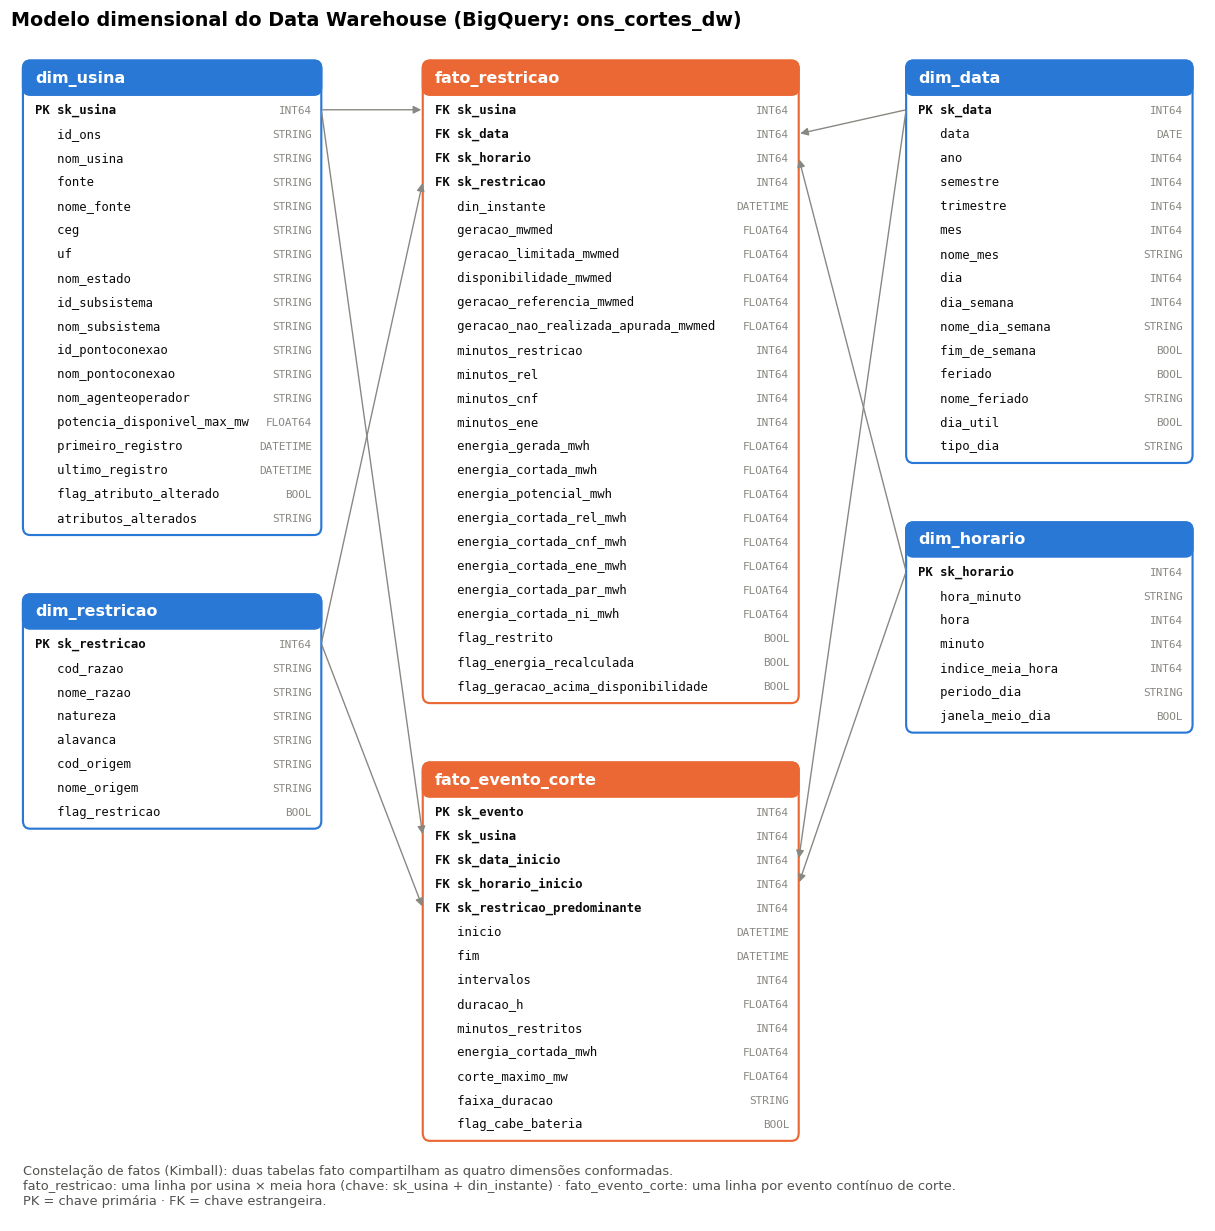

In [18]:
#@title Diagrama do modelo dimensional (gerado a partir do Catálogo de Dados)
def desenhar_modelo(catalogo, caminho=None):
    cabecalho, passo, folga = 0.026, 0.0182, 0.006
    n_attrs = catalogo.groupby("tabela").size()
    altura = lambda t: cabecalho + passo * n_attrs[t] + folga
    topo, vao = 0.965, 0.045
    caixas = {   # (x, y_base, largura, altura)
        "dim_usina":         (0.010, topo - altura("dim_usina"), 0.25, altura("dim_usina")),
        "fato_restricao":    (0.345, topo - altura("fato_restricao"), 0.315, altura("fato_restricao")),
        "dim_data":          (0.75, topo - altura("dim_data"), 0.24, altura("dim_data")),
    }
    caixas["dim_restricao"] = (0.010, caixas["dim_usina"][1] - vao - altura("dim_restricao"), 0.25, altura("dim_restricao"))
    caixas["fato_evento_corte"] = (0.345, caixas["fato_restricao"][1] - vao - altura("fato_evento_corte"), 0.315, altura("fato_evento_corte"))
    caixas["dim_horario"] = (0.75, caixas["dim_data"][1] - vao - altura("dim_horario"), 0.24, altura("dim_horario"))
    ligacoes = [("dim_usina", "sk_usina", "fato_restricao", "sk_usina"),
                ("dim_restricao", "sk_restricao", "fato_restricao", "sk_restricao"),
                ("dim_data", "sk_data", "fato_restricao", "sk_data"),
                ("dim_horario", "sk_horario", "fato_restricao", "sk_horario"),
                ("dim_usina", "sk_usina", "fato_evento_corte", "sk_usina"),
                ("dim_restricao", "sk_restricao", "fato_evento_corte", "sk_restricao_predominante"),
                ("dim_data", "sk_data", "fato_evento_corte", "sk_data_inicio"),
                ("dim_horario", "sk_horario", "fato_evento_corte", "sk_horario_inicio")]
    base_min = min(y for (_, y, _, _) in caixas.values())
    fig, ax = plt.subplots(figsize=(14, 14))
    ax.set_xlim(0, 1); ax.set_ylim(base_min - 0.06, 0.985); ax.axis("off")
    pos = {}
    for tabela, (x, y, w, h) in caixas.items():
        fato = tabela.startswith("fato")
        cor = LARANJA if fato else AZUL
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.006",
                                    facecolor="white", edgecolor=cor, linewidth=1.4))
        ax.add_patch(FancyBboxPatch((x, y + h - cabecalho), w, cabecalho, boxstyle="round,pad=0,rounding_size=0.006",
                                    facecolor=cor, edgecolor=cor, linewidth=1.4))
        ax.text(x + 0.01, y + h - cabecalho / 2, tabela, va="center", ha="left", color="white", fontsize=10.5, fontweight="bold")
        attrs = catalogo[catalogo["tabela"] == tabela].reset_index(drop=True)
        for k, a in attrs.iterrows():
            yy = y + h - cabecalho - passo * (k + 0.62)
            pk = (k == 0) and (tabela.startswith("dim") or a["atributo"] == "sk_evento")
            fk = (not pk) and a["atributo"].startswith("sk_")
            marca = "PK " if pk else ("FK " if fk else "   ")
            ax.text(x + 0.01, yy, f"{marca}{a['atributo']}", fontsize=8, family="monospace", va="center",
                    color=TINTA, fontweight="bold" if (pk or fk) else "normal")
            ax.text(x + w - 0.008, yy, a["tipo_bigquery"], fontsize=7.2, family="monospace", va="center", ha="right", color=CINZA)
            pos[(tabela, a["atributo"])] = yy
    for dim, pk, fato, fk in ligacoes:
        xd, _, wd, _ = caixas[dim]
        xf, _, wf, _ = caixas[fato]
        y1, y2 = pos[(dim, pk)], pos[(fato, fk)]
        x1, x2 = (xd + wd, xf) if xd < xf else (xd, xf + wf)
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="-|>", color=CINZA, lw=0.9, shrinkA=1, shrinkB=1))
    ax.text(0.01, base_min - 0.05, "Constelação de fatos (Kimball): duas tabelas fato compartilham as quatro dimensões conformadas.\n"
            "fato_restricao: uma linha por usina × meia hora (chave: sk_usina + din_instante) · "
            "fato_evento_corte: uma linha por evento contínuo de corte.\nPK = chave primária · FK = chave estrangeira.",
            fontsize=8.5, color=TINTA_2, va="bottom")
    ax.set_title(f"Modelo dimensional do Data Warehouse (BigQuery: {DATASET_BQ})", loc="left")
    if caminho:
        fig.savefig(caminho, bbox_inches="tight", facecolor="white")
    return fig

fig = desenhar_modelo(CATALOGO, os.path.join(DIR["catalogo"], "modelo_dimensional.png"))
salvar_figura(fig, "m1_modelo_dimensional")
plt.show()

### 7.3 Conformação de tipos e validação contra o catálogo

Antes da carga, cada tabela *gold* recebe exatamente as colunas e os tipos do catálogo, e cada atributo é conferido contra o domínio declarado. **ATENÇÃO** indica valores fora do domínio (acurácia) ou nulos em campo obrigatório (completude). Esses casos são mostrados e discutidos, não escondidos.

In [19]:
def conformar_tipos(df, tabela):
    saida = {}
    for a in CATALOGO[CATALOGO["tabela"] == tabela].itertuples():
        s = df[a.atributo]
        if a.tipo_bigquery == "INT64":
            s = pd.to_numeric(s).astype("Int64")
        elif a.tipo_bigquery == "FLOAT64":
            s = pd.to_numeric(s).astype("float64")
        elif a.tipo_bigquery == "BOOL":
            s = s.astype("boolean")
        elif a.tipo_bigquery == "STRING":
            s = s.astype("string")
        elif a.tipo_bigquery == "DATETIME":
            s = pd.to_datetime(s)
        elif a.tipo_bigquery == "DATE":
            s = pd.to_datetime(s).dt.date
        saida[a.atributo] = s.reset_index(drop=True)
    return pd.DataFrame(saida)

gold = {
    "dim_usina": conformar_tipos(dim_usina, "dim_usina"),
    "dim_data": conformar_tipos(dim_data, "dim_data"),
    "dim_horario": conformar_tipos(dim_horario, "dim_horario"),
    "dim_restricao": conformar_tipos(dim_restricao, "dim_restricao"),
    "fato_evento_corte": conformar_tipos(fato_evento_corte, "fato_evento_corte"),
    "fato_restricao": conformar_tipos(restricoes, "fato_restricao"),
}
del restricoes, fato_evento_corte, ev
gc.collect()

def validar_catalogo(tabelas):
    linhas = []
    for a in CATALOGO.itertuples():
        s = tabelas[a.tabela][a.atributo]
        nn, dom = s.dropna(), a.dominio
        fora, minimo, maximo = 0, "", ""
        if len(nn) and dom is not None:
            if dom[0] == "faixa" and a.tipo_bigquery in ("DATE", "DATETIME"):
                v = pd.to_datetime(pd.Series(nn.to_numpy()))
                fora = int((~v.dt.normalize().between(pd.Timestamp(dom[1]), pd.Timestamp(dom[2]))).sum())
                minimo, maximo = str(v.min()), str(v.max())
            elif dom[0] == "faixa":
                v = pd.to_numeric(nn).astype(float)
                fora = int((~v.between(dom[1], dom[2])).sum())
                minimo, maximo = num(v.min(), 2), num(v.max(), 2)
            elif dom[0] == "valores":
                fora = int((~nn.isin(dom[1])).sum())
                minimo = f"{nn.nunique()} valores distintos"
            elif dom[0] == "padrao":
                fora = int((~nn.astype(str).str.match(dom[1])).sum())
                minimo = f"{nn.nunique()} valores distintos"
        nulos = int(s.isna().sum())
        ok = fora == 0 and (nulos == 0 or not a.obrigatorio)
        linhas.append({"tabela": a.tabela, "atributo": a.atributo, "dominio": a.dominio_texto,
                       "nulos": nulos, "pct_nulos": round(100 * nulos / max(len(s), 1), 2),
                       "minimo_observado": minimo, "maximo_observado": maximo,
                       "fora_do_dominio": fora, "status": "OK" if ok else "ATENÇÃO"})
    return pd.DataFrame(linhas)

validacao = validar_catalogo(gold)
salvar_tabela(validacao, "m2_validacao_catalogo")
alertas = validacao[validacao["status"] != "OK"]
mostrar(f"**Validação contra o catálogo:** {len(validacao) - len(alertas)} de {len(validacao)} atributos OK · "
        f"{len(alertas)} com ATENÇÃO" + (" (listados abaixo)." if len(alertas) else "."))
display(alertas if len(alertas) else validacao.head(12))
if len(alertas):
    mostrar("**Tratamento dos alertas:** valores fora do domínio foram **mantidos** e ficam registrados como achados de acurácia. "
            "Os domínios de potência e energia foram definidos com folga (até 2.500 MW por usina ou conjunto); um valor acima disso "
            f"indica erro de registro na origem. Ocorrências: {num(int(alertas['fora_do_dominio'].sum()))}.")

# Persistência da gold no Drive + documentação do catálogo
for nome, df in gold.items():
    df.to_parquet(os.path.join(DIR["gold"], f"{nome}.parquet"), index=False)
cat_doc = catalogo_legivel()
cat_doc.to_csv(os.path.join(DIR["catalogo"], "catalogo_dados.csv"), index=False)
with open(os.path.join(DIR["catalogo"], "catalogo_dados.md"), "w", encoding="utf-8") as arq:
    arq.write(f"# Catálogo de Dados — Data Warehouse `{DATASET_BQ}`\n\n"
              "Gerado automaticamente pelo notebook a partir da definição única do catálogo (Seção 7.2). "
              "As mesmas descrições estão gravadas nas colunas das tabelas do BigQuery.\n\n"
              "Colunas: **Tipo (BigQuery)**, **Tipo lógico** (numérico, categórico, texto, data, booleano), **Domínio** "
              "(faixa mínima e máxima esperada, lista de valores válidos ou padrão), **Obrigatório**, **Significado do nulo** e "
              "**Linhagem** (coluna de origem no ONS e regras de transformação, ver [regras_transformacao.md](regras_transformacao.md)).\n\n"
              "Modelo: [modelo_dados.md](modelo_dados.md) · Diagrama: [modelo_dimensional.png](modelo_dimensional.png)\n\n")
    for tabela in cat_doc["Tabela"].unique():
        arq.write(f"## {tabela}\n\n" + tabela_markdown(cat_doc[cat_doc["Tabela"] == tabela].drop(columns="Tabela")) + "\n\n")
log_transformacoes = pd.DataFrame(LOG)
log_transformacoes.to_csv(os.path.join(DIR["metadados"], "log_transformacoes.csv"), index=False)
salvar_tabela(log_transformacoes, "m3_log_transformacoes")
mostrar("**Camada gold gravada no Drive** (Parquet) e catálogo exportado. Log de transformações (linhagem):")
display(log_transformacoes)

**Validação contra o catálogo:** 85 de 87 atributos OK · 2 com ATENÇÃO (listados abaixo).

,tabela,atributo,dominio,nulos,pct_nulos,minimo_observado,maximo_observado,fora_do_dominio,status
13,dim_usina,potencia_disponivel_max_mw,0 a 2500,0,0.0,"0,00","7.778,69",1,ATENÇÃO
55,fato_restricao,disponibilidade_mwmed,0 a 2500,0,0.0,"0,00","7.778,69",5,ATENÇÃO


**Tratamento dos alertas:** valores fora do domínio foram **mantidos** e ficam registrados como achados de acurácia. Os domínios de potência e energia foram definidos com folga (até 2.500 MW por usina ou conjunto); um valor acima disso indica erro de registro na origem. Ocorrências: 6.

**Camada gold gravada no Drive** (Parquet) e catálogo exportado. Log de transformações (linhagem):

,regra,camada,tabela,descricao,linhas_afetadas,linhas_total,executado_em
0,R01,silver,restricoes,Tipagem explícita das 24 colunas (contagem = valores não conversíveis → nulo),0,3874032,2026-10-21 09:45:40
1,R02,silver,restricoes,Código em maiúsculas e sem espaços: cod_razaorestricao,0,3874032,2026-10-21 09:45:40
2,R02,silver,restricoes,Código em maiúsculas e sem espaços: cod_origemrestricao,0,3874032,2026-10-21 09:45:40
3,R02,silver,restricoes,Código em maiúsculas e sem espaços: id_subsistema,0,3874032,2026-10-21 09:45:40
4,R02,silver,restricoes,Código em maiúsculas e sem espaços: id_estado,0,3874032,2026-10-21 09:45:40
5,R02,silver,restricoes,Espaços extras removidos: id_ons,0,3874032,2026-10-21 09:45:40
6,R02,silver,restricoes,Espaços extras removidos: ceg,0,3874032,2026-10-21 09:45:40
7,R02,silver,restricoes,Espaços extras removidos: id_pontoconexao,0,3874032,2026-10-21 09:45:40
8,R02,silver,restricoes,Espaços extras removidos: nom_usina,0,3874032,2026-10-21 09:45:40
9,R02,silver,restricoes,Espaços extras removidos: nom_estado,0,3874032,2026-10-21 09:45:40


## 8. Carga no Data Warehouse (BigQuery), verificação da persistência e evidências

### 8.1 Processo de carga (ETL)

A carga fecha o ETL: **extração** (Seção 4) → **transformação** (Seções 6 e 7) → **carga**. Cada tabela *gold* vai para o BigQuery num *load job* com:

* **esquema explícito, gerado do catálogo:** tipos, `REQUIRED`/`NULLABLE` e descrição de cada coluna. Uma coluna obrigatória com nulo **faz a carga falhar**, o que funciona como trava de integridade;
* **`WRITE_TRUNCATE`:** a carga é idempotente. Reexecutar o notebook substitui as tabelas em vez de duplicar linhas, o que também contorna a ausência de DML no *sandbox*;
* **descrição da tabela** gravada nos metadados do BigQuery.

Depois, o notebook **relê do BigQuery** a lista de tabelas, o esquema gravado, as contagens e as somas, e compara tudo com a *gold* do Drive (reconciliação). Também confere unicidade de chaves e integridade referencial com SQL.

In [20]:
ds = bigquery.Dataset(f"{PROJECT_ID}.{DATASET_BQ}")
ds.location = LOCAL_BQ
ds.description = ("MVP UnB/PSP8 — Data Warehouse (modelo dimensional) de cortes de geração eólica e solar no SIN. "
                  "Fonte: ONS Dados Abertos, Restrição de Operação por Constrained-off (licença CC BY).")
client.create_dataset(ds, exists_ok=True)

DESCRICOES = {
    "dim_usina": "Dimensão de usinas eólicas e solares (UF, subsistema, ponto de conexão, agente).",
    "dim_data": "Dimensão calendário, com dia útil, sábado, domingo e feriados nacionais.",
    "dim_horario": "Dimensão das 48 meias horas do dia, com período e janela do meio-dia.",
    "dim_restricao": "Dimensão dos motivos (REL, CNF, ENE, PAR) e origens (LOC, SIS) de restrição.",
    "fato_restricao": "Fato de restrições. Grão: usina × meia hora. Energia gerada, cortada e potencial (MWh), rateada por motivo.",
    "fato_evento_corte": "Fato de eventos de corte. Grão: sequência contínua de meias horas restritas de uma usina.",
    "meta_catalogo_dados": "Catálogo de Dados do modelo (descrição, domínio, obrigatoriedade e linhagem).",
    "meta_log_transformacoes": "Log de linhagem: regras de transformação aplicadas e linhas afetadas.",
    "meta_coleta": "Metadados da coleta: arquivos, linhas, tamanho, ETag, Last-Modified, SHA-256 e data.",
    "meta_perfil_qualidade": "Perfil de qualidade de cada atributo da camada bronze, por fonte.",
    "meta_verificacoes_qualidade": "Verificações de qualidade por dimensão (unicidade, completude etc.) na camada bronze.",
}

def esquema_catalogo(tabela):
    return [bigquery.SchemaField(a.atributo, a.tipo_bigquery,
                                 mode="REQUIRED" if a.obrigatorio else "NULLABLE",
                                 description=f"{a.descricao} Domínio: {a.dominio_texto}."[:1024])
            for a in CATALOGO[CATALOGO["tabela"] == tabela].itertuples()]

def preparar_metadados(df):
    df, esquema = df.copy(), []
    for c in df.columns:
        if pd.api.types.is_bool_dtype(df[c]):
            df[c], tipo = df[c].astype("boolean"), "BOOL"
        elif pd.api.types.is_integer_dtype(df[c]):
            df[c], tipo = df[c].astype("Int64"), "INT64"
        elif pd.api.types.is_float_dtype(df[c]):
            df[c], tipo = df[c].astype("float64"), "FLOAT64"
        else:
            df[c], tipo = df[c].astype("string"), "STRING"
        esquema.append(bigquery.SchemaField(c, tipo))
    return df, esquema

def carregar(df, tabela, esquema):
    destino = f"{PROJECT_ID}.{DATASET_BQ}.{tabela}"
    inicio = time.time()
    config = bigquery.LoadJobConfig(schema=esquema, write_disposition="WRITE_TRUNCATE")
    client.load_table_from_dataframe(df, destino, job_config=config).result()
    tab = client.get_table(destino)
    tab.description = DESCRICOES[tabela]
    campos = ["description"]
    if any(f.description for f in esquema) and not all(c.description for c in tab.schema):
        tab.schema, campos = esquema, ["description", "schema"]   # garante as descrições das colunas
    tab = client.update_table(tab, campos)
    return {"tabela": tabela, "linhas_drive": len(df), "linhas_bigquery": tab.num_rows,
            "tamanho_mb": round(tab.num_bytes / 2**20, 3), "segundos": round(time.time() - inicio, 1),
            "status": "OK" if tab.num_rows == len(df) else "DIVERGENTE"}

cargas = []
for nome, df in gold.items():
    cargas.append(carregar(df, nome, esquema_catalogo(nome)))
    print(f"{nome:<22} {cargas[-1]['linhas_bigquery']:>12,} linhas  {cargas[-1]['segundos']:>6} s  {cargas[-1]['status']}")
metas = {
    "meta_catalogo_dados": CATALOGO.drop(columns=["dominio"]),
    "meta_log_transformacoes": log_transformacoes,
    "meta_coleta": meta_coleta,
    "meta_perfil_qualidade": perfil,
    "meta_verificacoes_qualidade": verificacoes,
}
for nome, df in metas.items():
    df_meta, esquema_meta = preparar_metadados(df)
    cargas.append(carregar(df_meta, nome, esquema_meta))

log_carga = pd.DataFrame(cargas)
salvar_tabela(log_carga, "c1_log_carga")
mostrar(f"**Carga concluída:** {len(log_carga)} tabelas no dataset `{PROJECT_ID}.{DATASET_BQ}` "
        f"({num(log_carga['linhas_bigquery'].sum())} linhas, {num(log_carga['tamanho_mb'].sum(), 1)} MB). "
        f"Tabelas com contagem divergente: {int((log_carga['status'] != 'OK').sum())}.")
display(log_carga)

dim_usina                       235 linhas     4.4 s  OK
dim_data                        365 linhas     3.3 s  OK
dim_horario                      48 linhas     3.3 s  OK
dim_restricao                    16 linhas     4.2 s  OK
fato_evento_corte            67,782 linhas     3.4 s  OK
fato_restricao            3,874,032 linhas    19.7 s  OK


**Carga concluída:** 11 tabelas no dataset `mvp-olist-entregas.ons_cortes_dw` (3.942.719 linhas, 556,6 MB). Tabelas com contagem divergente: 0.

,tabela,linhas_drive,linhas_bigquery,tamanho_mb,segundos,status
0,dim_usina,235,235,0.038,4.4,OK
1,dim_data,365,365,0.035,3.3,OK
2,dim_horario,48,48,0.002,3.3,OK
3,dim_restricao,16,16,0.002,4.2,OK
4,fato_evento_corte,67782,67782,6.932,3.4,OK
5,fato_restricao,3874032,3874032,549.550,19.7,OK
6,meta_catalogo_dados,87,87,0.017,3.0,OK
7,meta_log_transformacoes,46,46,0.005,3.3,OK
8,meta_coleta,24,24,0.025,3.4,OK
9,meta_perfil_qualidade,48,48,0.005,3.8,OK


In [21]:
LOG_CONSULTAS = []

def consultar(sql, rotulo):
    """Executa SQL no BigQuery, registra o job e os bytes processados e salva o SQL executado no Drive."""
    sql = sql.replace("{DW}", DW).strip()
    job = client.query(sql)
    df = job.to_dataframe(create_bqstorage_client=False)
    for c in df.columns:   # tipos anuláveis do BigQuery (Int64/boolean) → tipos NumPy, quando não há nulos
        s = df[c]
        if pd.api.types.is_bool_dtype(s) and not s.isna().any():
            df[c] = s.astype(bool)
        elif pd.api.types.is_integer_dtype(s):
            df[c] = s.astype("int64") if not s.isna().any() else s.astype("float64")
        elif pd.api.types.is_float_dtype(s):
            df[c] = s.astype("float64")
    LOG_CONSULTAS.append({"consulta": rotulo, "job_id": getattr(job, "job_id", ""),
                          "bytes_processados": int(job.total_bytes_processed or 0), "linhas_retornadas": len(df),
                          "executada_em": dt.datetime.now(dt.timezone(dt.timedelta(hours=-3))).strftime("%d/%m/%Y %H:%M:%S")})
    with open(os.path.join(DIR["sql"], f"{rotulo}.sql"), "w", encoding="utf-8") as arq:
        arq.write(sql + "\n")
    return df

# 1) Persistência: as tabelas existem no BigQuery, com linhas, tamanho, data de criação e expiração
tabelas_bq = [client.get_table(t.reference) for t in client.list_tables(f"{PROJECT_ID}.{DATASET_BQ}")]
persistidas = pd.DataFrame([{"tabela": t.table_id, "linhas": t.num_rows, "tamanho_mb": round(t.num_bytes / 2**20, 2),
                             "colunas": len(t.schema),
                             "criada_em": t.created.astimezone(dt.timezone(dt.timedelta(hours=-3))).strftime("%d/%m/%Y %H:%M") if t.created else "",
                             "expira_em": t.expires.strftime("%d/%m/%Y") if t.expires else "não expira",
                             "descricao": t.description} for t in tabelas_bq]).sort_values("tabela").reset_index(drop=True)
salvar_tabela(persistidas, "c2_tabelas_persistidas")
mostrar(f"**Tabelas persistidas no BigQuery** — console: "
        f"https://console.cloud.google.com/bigquery?project={PROJECT_ID}&p={PROJECT_ID}&d={DATASET_BQ}&page=dataset")
display(persistidas)

# 2) Integridade: unicidade das chaves, chaves estrangeiras sem correspondência e consistência do rateio
SQL_INTEGRIDADE = """
SELECT 'Chave duplicada na fato_restricao (sk_usina, din_instante)' AS verificacao, COUNT(*) AS ocorrencias
FROM (SELECT sk_usina, din_instante FROM {DW}.fato_restricao GROUP BY sk_usina, din_instante HAVING COUNT(*) > 1) AS d
UNION ALL SELECT 'Chave duplicada na fato_evento_corte', COUNT(*) - COUNT(DISTINCT sk_evento) FROM {DW}.fato_evento_corte
UNION ALL SELECT 'Chave duplicada em dim_usina', COUNT(*) - COUNT(DISTINCT sk_usina) FROM {DW}.dim_usina
UNION ALL SELECT 'Chave natural duplicada em dim_usina (fonte, id_ons)', COUNT(*)
FROM (SELECT fonte, id_ons FROM {DW}.dim_usina GROUP BY fonte, id_ons HAVING COUNT(*) > 1) AS d
UNION ALL SELECT 'Chave duplicada em dim_data', COUNT(*) - COUNT(DISTINCT sk_data) FROM {DW}.dim_data
UNION ALL SELECT 'Chave duplicada em dim_horario', COUNT(*) - COUNT(DISTINCT sk_horario) FROM {DW}.dim_horario
UNION ALL SELECT 'Chave duplicada em dim_restricao', COUNT(*) - COUNT(DISTINCT sk_restricao) FROM {DW}.dim_restricao
UNION ALL SELECT 'FK sem correspondência: fato_restricao.sk_usina', COUNT(*)
FROM {DW}.fato_restricao AS f LEFT JOIN {DW}.dim_usina AS u ON f.sk_usina = u.sk_usina WHERE u.sk_usina IS NULL
UNION ALL SELECT 'FK sem correspondência: fato_restricao.sk_data', COUNT(*)
FROM {DW}.fato_restricao AS f LEFT JOIN {DW}.dim_data AS d ON f.sk_data = d.sk_data WHERE d.sk_data IS NULL
UNION ALL SELECT 'FK sem correspondência: fato_restricao.sk_horario', COUNT(*)
FROM {DW}.fato_restricao AS f LEFT JOIN {DW}.dim_horario AS h ON f.sk_horario = h.sk_horario WHERE h.sk_horario IS NULL
UNION ALL SELECT 'FK sem correspondência: fato_restricao.sk_restricao', COUNT(*)
FROM {DW}.fato_restricao AS f LEFT JOIN {DW}.dim_restricao AS r ON f.sk_restricao = r.sk_restricao WHERE r.sk_restricao IS NULL
UNION ALL SELECT 'FK sem correspondência: fato_evento_corte.sk_usina', COUNT(*)
FROM {DW}.fato_evento_corte AS e LEFT JOIN {DW}.dim_usina AS u ON e.sk_usina = u.sk_usina WHERE u.sk_usina IS NULL
UNION ALL SELECT 'FK sem correspondência: fato_evento_corte.sk_data_inicio', COUNT(*)
FROM {DW}.fato_evento_corte AS e LEFT JOIN {DW}.dim_data AS d ON e.sk_data_inicio = d.sk_data WHERE d.sk_data IS NULL
UNION ALL SELECT 'FK sem correspondência: fato_evento_corte.sk_horario_inicio', COUNT(*)
FROM {DW}.fato_evento_corte AS e LEFT JOIN {DW}.dim_horario AS h ON e.sk_horario_inicio = h.sk_horario WHERE h.sk_horario IS NULL
UNION ALL SELECT 'FK sem correspondência: fato_evento_corte.sk_restricao_predominante', COUNT(*)
FROM {DW}.fato_evento_corte AS e LEFT JOIN {DW}.dim_restricao AS r ON e.sk_restricao_predominante = r.sk_restricao WHERE r.sk_restricao IS NULL
UNION ALL SELECT 'Rateio por motivo diferente do total cortado (> 0,001 MWh)', COUNT(*)
FROM {DW}.fato_restricao
WHERE ABS(energia_cortada_rel_mwh + energia_cortada_cnf_mwh + energia_cortada_ene_mwh + energia_cortada_par_mwh
          + energia_cortada_ni_mwh - energia_cortada_mwh) > 0.001
UNION ALL SELECT 'Energia cortada em intervalo não restrito', COUNTIF(NOT flag_restrito AND energia_cortada_mwh > 0)
FROM {DW}.fato_restricao
"""
integridade = consultar(SQL_INTEGRIDADE, "c3_integridade_referencial")
integridade["status"] = np.where(integridade["ocorrencias"] == 0, "OK", "FALHA")
salvar_tabela(integridade, "c3_integridade_referencial")
display(integridade)

# 3) Reconciliação: o que está no BigQuery bate com a gold do Drive?
SQL_RECONCILIACAO = """
SELECT
  (SELECT COUNT(*) FROM {DW}.fato_restricao) AS linhas_fato_restricao,
  (SELECT COUNT(DISTINCT sk_usina) FROM {DW}.fato_restricao) AS usinas_com_registro,
  (SELECT COUNTIF(flag_restrito) FROM {DW}.fato_restricao) AS intervalos_restritos,
  (SELECT ROUND(SUM(energia_gerada_mwh), 3) FROM {DW}.fato_restricao) AS energia_gerada_mwh,
  (SELECT ROUND(SUM(energia_cortada_mwh), 3) FROM {DW}.fato_restricao) AS energia_cortada_mwh,
  (SELECT COUNT(*) FROM {DW}.fato_evento_corte) AS eventos,
  (SELECT ROUND(SUM(energia_cortada_mwh), 3) FROM {DW}.fato_evento_corte) AS energia_cortada_eventos_mwh
"""
bq = consultar(SQL_RECONCILIACAO, "c4_reconciliacao").iloc[0]
fr, fe = gold["fato_restricao"], gold["fato_evento_corte"]
local = {"linhas_fato_restricao": len(fr), "usinas_com_registro": fr["sk_usina"].nunique(),
         "intervalos_restritos": int(fr["flag_restrito"].sum()),
         "energia_gerada_mwh": round(float(fr["energia_gerada_mwh"].sum()), 3),
         "energia_cortada_mwh": round(float(fr["energia_cortada_mwh"].sum()), 3),
         "eventos": len(fe), "energia_cortada_eventos_mwh": round(float(fe["energia_cortada_mwh"].sum()), 3)}
reconciliacao = pd.DataFrame({"metrica": list(local), "gold_no_drive": list(local.values()),
                              "bigquery": [bq[k] for k in local]})
reconciliacao["status"] = np.where(np.isclose(reconciliacao["gold_no_drive"].astype(float), reconciliacao["bigquery"].astype(float),
                                              rtol=1e-7, atol=0.01), "OK", "DIVERGENTE")
salvar_tabela(reconciliacao, "c4_reconciliacao")
display(reconciliacao)
eventos_fecham = np.isclose(local["energia_cortada_mwh"], local["energia_cortada_eventos_mwh"], rtol=1e-7, atol=0.01)
mostrar(f"**Persistência e integridade:** {int((integridade['status'] == 'OK').sum())}/{len(integridade)} verificações de integridade OK · "
        f"{int((reconciliacao['status'] == 'OK').sum())}/{len(reconciliacao)} métricas reconciliadas entre Drive e BigQuery · "
        f"a energia somada nos eventos {'é igual' if eventos_fecham else 'NÃO é igual'} à energia cortada da fato semi-horária.")

**Tabelas persistidas no BigQuery** — console: https://console.cloud.google.com/bigquery?project=mvp-olist-entregas&p=mvp-olist-entregas&d=ons_cortes_dw&page=dataset

,tabela,linhas,tamanho_mb,colunas,criada_em,expira_em,descricao
0,dim_data,365,0.04,15,21/10/2026 09:48,20/12/2026,"Dimensão calendário, com dia útil, sábado, domingo e feriados nacionais."
1,dim_horario,48,0.00,7,21/10/2026 09:48,20/12/2026,"Dimensão das 48 meias horas do dia, com período e janela do meio-dia."
2,dim_restricao,16,0.00,8,21/10/2026 09:48,20/12/2026,"Dimensão dos motivos (REL, CNF, ENE, PAR) e origens (LOC, SIS) de restrição."
3,dim_usina,235,0.04,18,21/10/2026 09:48,20/12/2026,"Dimensão de usinas eólicas e solares (UF, subsistema, ponto de conexão, agente)."
4,fato_evento_corte,67782,6.93,14,21/10/2026 09:48,20/12/2026,Fato de eventos de corte. Grão: sequência contínua de meias horas restritas de uma usina.
5,fato_restricao,3874032,549.55,25,21/10/2026 09:49,20/12/2026,"Fato de restrições. Grão: usina × meia hora. Energia gerada, cortada e potencial (MWh), rateada ..."
6,meta_catalogo_dados,87,0.02,9,21/10/2026 09:49,20/12/2026,"Catálogo de Dados do modelo (descrição, domínio, obrigatoriedade e linhagem)."
7,meta_coleta,24,0.02,15,21/10/2026 09:49,20/12/2026,"Metadados da coleta: arquivos, linhas, tamanho, ETag, Last-Modified, SHA-256 e data."
8,meta_log_transformacoes,46,0.01,7,21/10/2026 09:49,20/12/2026,Log de linhagem: regras de transformação aplicadas e linhas afetadas.
9,meta_perfil_qualidade,48,0.00,11,21/10/2026 09:49,20/12/2026,"Perfil de qualidade de cada atributo da camada bronze, por fonte."


,verificacao,ocorrencias,status
0,FK sem correspondência: fato_evento_corte.sk_restricao_predominante,0,OK
1,Energia cortada em intervalo não restrito,0,OK
2,Chave duplicada em dim_horario,0,OK
3,FK sem correspondência: fato_evento_corte.sk_usina,0,OK
4,FK sem correspondência: fato_restricao.sk_data,0,OK
5,"Rateio por motivo diferente do total cortado (> 0,001 MWh)",0,OK
6,FK sem correspondência: fato_restricao.sk_horario,0,OK
7,Chave duplicada em dim_restricao,0,OK
8,Chave duplicada em dim_data,0,OK
9,FK sem correspondência: fato_restricao.sk_restricao,0,OK


,metrica,gold_no_drive,bigquery,status
0,linhas_fato_restricao,3.874032e+06,3.874032e+06,OK
1,usinas_com_registro,2.350000e+02,2.350000e+02,OK
2,intervalos_restritos,1.432229e+06,1.432229e+06,OK
3,energia_gerada_mwh,1.427966e+08,1.427966e+08,OK
4,energia_cortada_mwh,3.721728e+07,3.721728e+07,OK
5,eventos,6.778200e+04,6.778200e+04,OK
6,energia_cortada_eventos_mwh,3.721728e+07,3.721728e+07,OK


**Persistência e integridade:** 17/17 verificações de integridade OK · 7/7 métricas reconciliadas entre Drive e BigQuery · a energia somada nos eventos é igual à energia cortada da fato semi-horária.

### 8.2 Evidências visuais geradas a partir das plataformas

As quatro imagens abaixo substituem capturas de tela manuais. Cada uma é desenhada **a partir de dados lidos na hora** do Google Drive (sistema de arquivos montado no Colab) ou da API do BigQuery. Elas ficam em `evidencias/imagens/` no repositório.

Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/imagens/e1_data_lake_drive.png


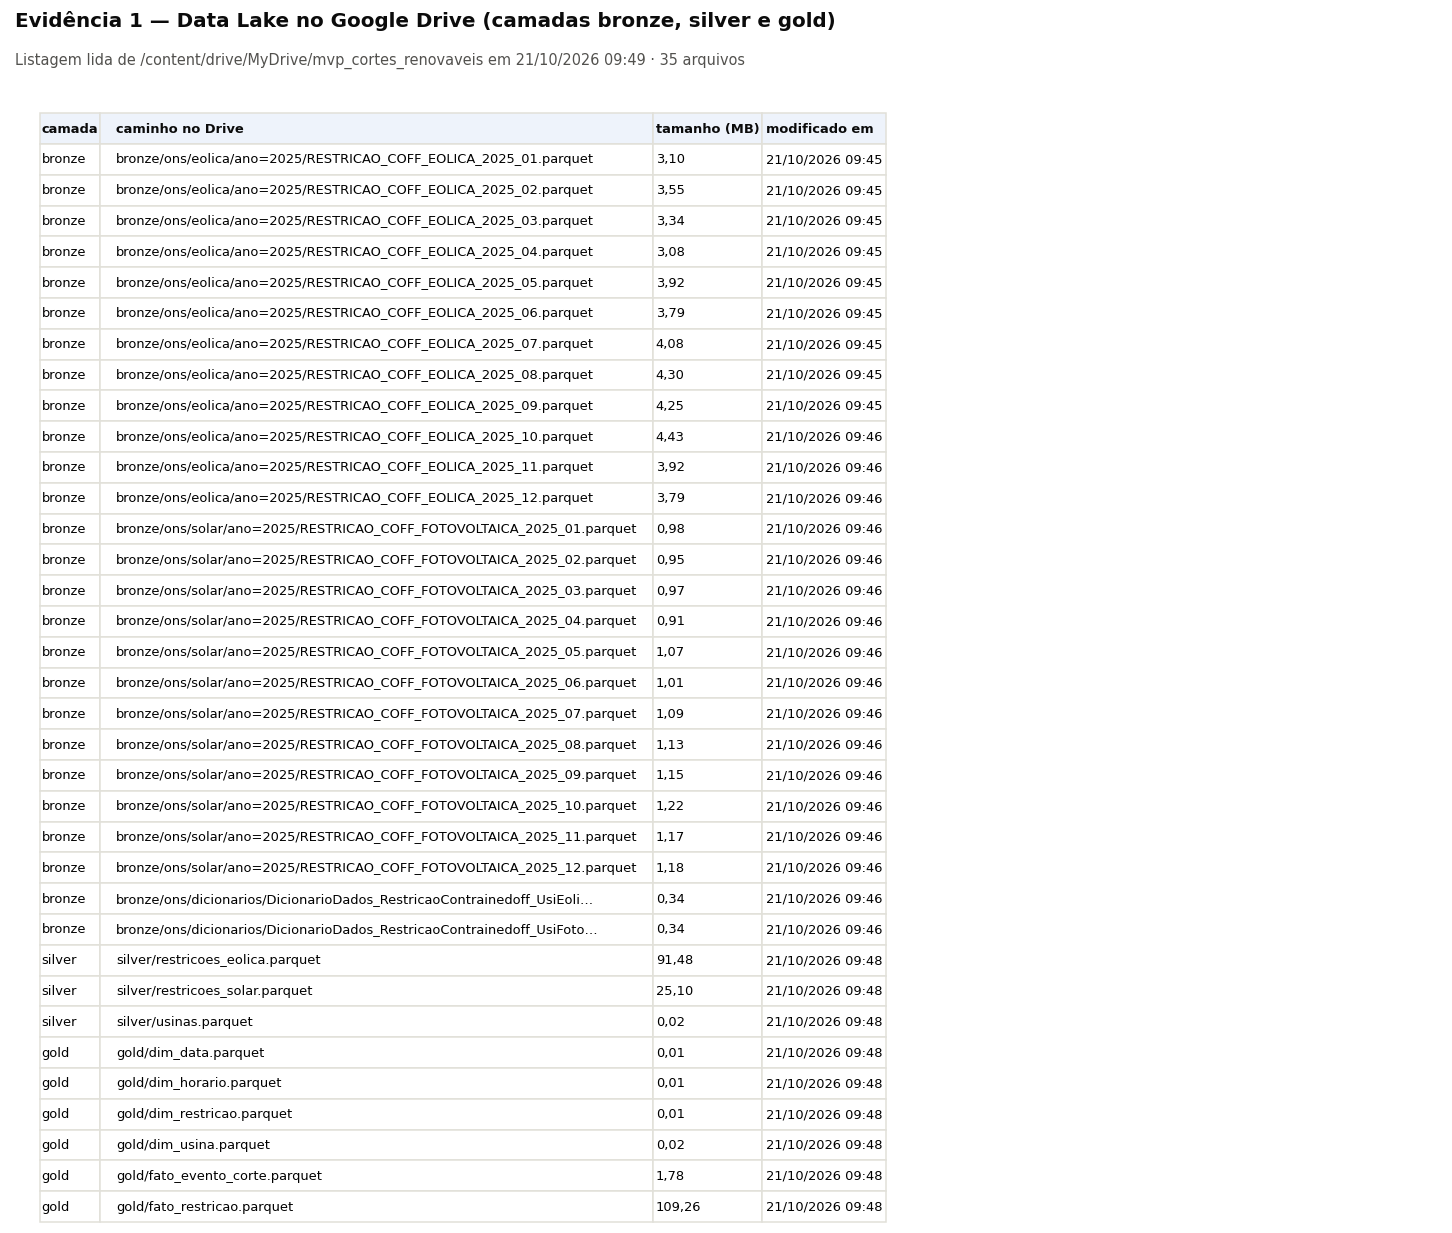

Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/imagens/e2_tabelas_bigquery.png


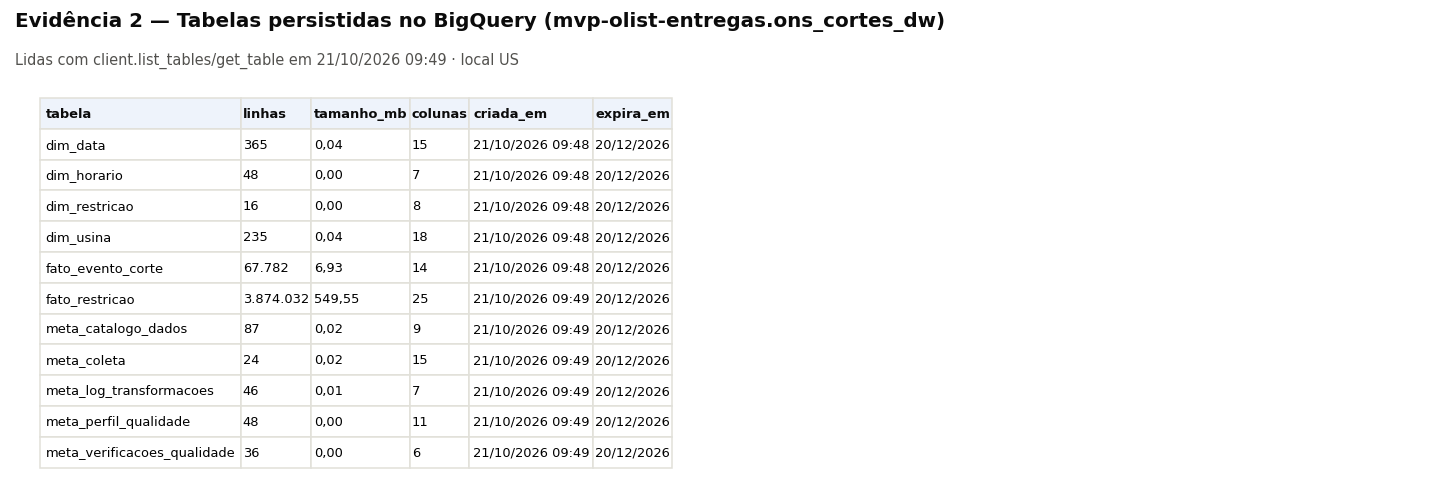

Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/imagens/e3_esquema_bigquery.png


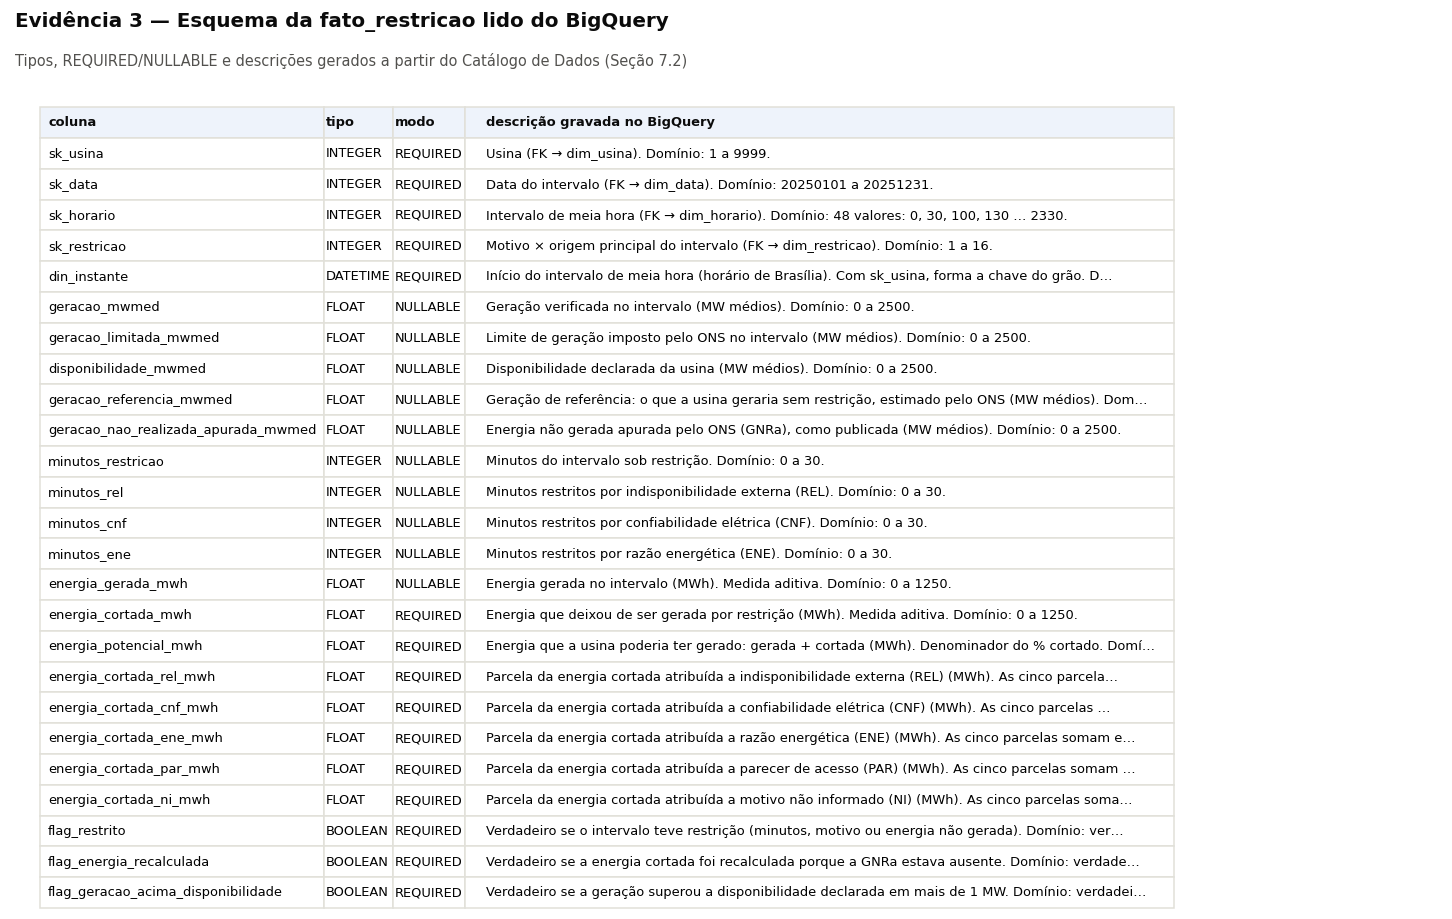

Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/imagens/e4_integridade_reconciliacao.png


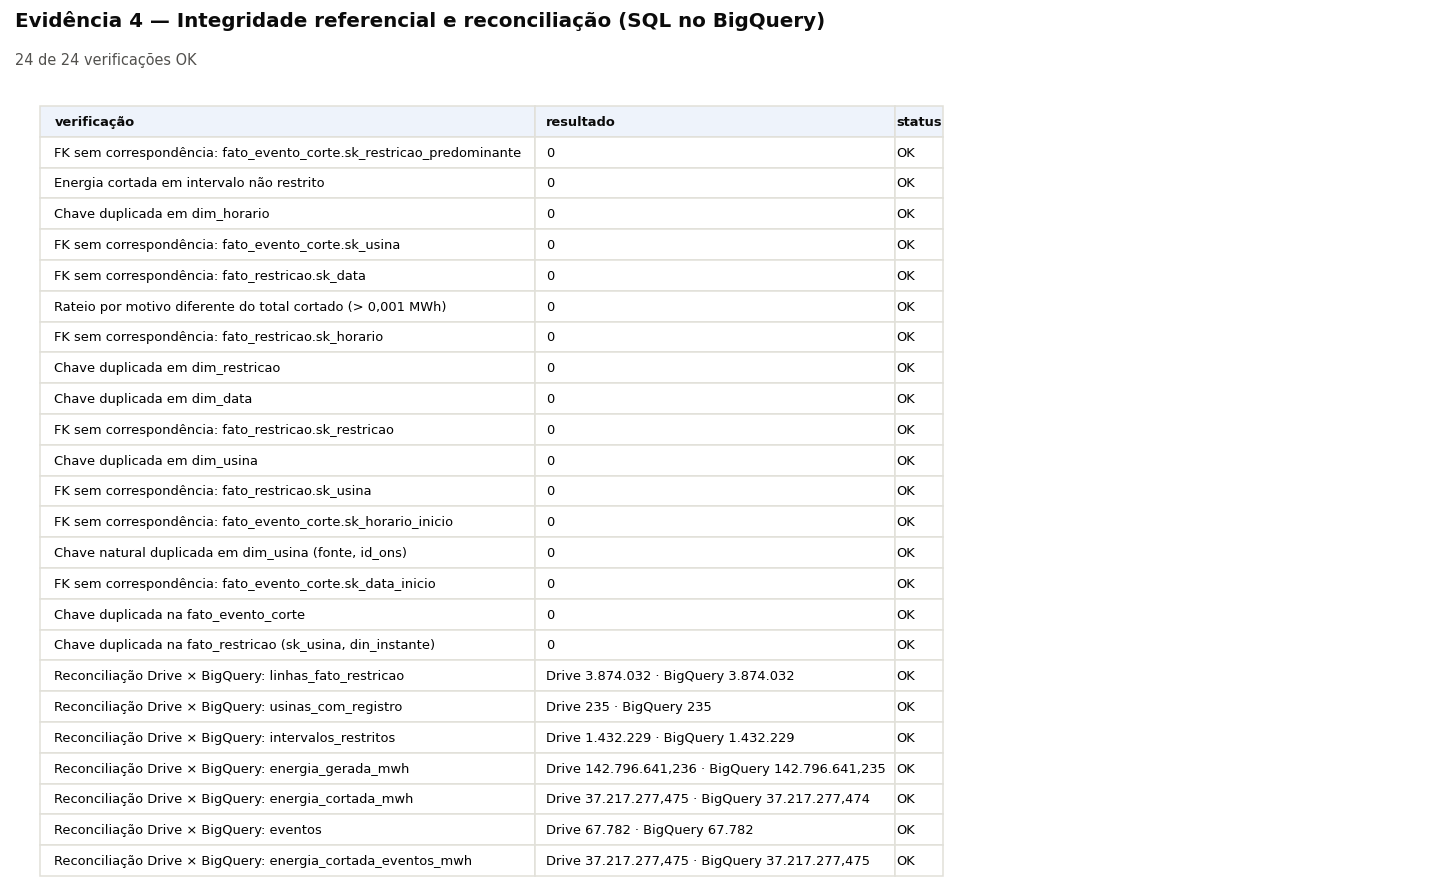

In [22]:
FUSO = dt.timezone(dt.timedelta(hours=-3))

# Evidência 1 — Data Lake no Google Drive (arquivos lidos do Drive montado)
arquivos_lago = []
for camada in ["bronze", "silver", "gold"]:
    for raiz, _, nomes in os.walk(DIR[camada]):
        for nome_arq in sorted(nomes):
            caminho = os.path.join(raiz, nome_arq)
            arquivos_lago.append({"camada": camada, "caminho no Drive": os.path.relpath(caminho, PASTA_DRIVE),
                                  "tamanho (MB)": num(os.path.getsize(caminho) / 2**20, 2),
                                  "modificado em": dt.datetime.fromtimestamp(os.path.getmtime(caminho), FUSO).strftime("%d/%m/%Y %H:%M")})
lago = pd.DataFrame(arquivos_lago)
salvar_tabela(lago, "e1_data_lake_drive")
imagem_evidencia(lago, "Evidência 1 — Data Lake no Google Drive (camadas bronze, silver e gold)",
                 f"Listagem lida de {PASTA_DRIVE} em {dt.datetime.now(FUSO):%d/%m/%Y %H:%M} · {len(lago)} arquivos",
                 "e1_data_lake_drive")

# Evidência 2 — tabelas do dataset no BigQuery (lidas da API)
imagem_evidencia(persistidas.drop(columns="descricao").assign(linhas=persistidas["linhas"].map(num),
                                                              tamanho_mb=persistidas["tamanho_mb"].map(lambda v: num(v, 2))),
                 f"Evidência 2 — Tabelas persistidas no BigQuery ({PROJECT_ID}.{DATASET_BQ})",
                 f"Lidas com client.list_tables/get_table em {dt.datetime.now(FUSO):%d/%m/%Y %H:%M} · local {LOCAL_BQ}",
                 "e2_tabelas_bigquery")

# Evidência 3 — esquema gravado no BigQuery (tipos, obrigatoriedade e descrições vindas do catálogo)
esquema_lido = pd.DataFrame([{"coluna": c.name, "tipo": c.field_type, "modo": c.mode, "descrição gravada no BigQuery": c.description}
                             for c in client.get_table(f"{PROJECT_ID}.{DATASET_BQ}.fato_restricao").schema])
salvar_tabela(esquema_lido, "e3_esquema_fato_restricao")
imagem_evidencia(esquema_lido, "Evidência 3 — Esquema da fato_restricao lido do BigQuery",
                 "Tipos, REQUIRED/NULLABLE e descrições gerados a partir do Catálogo de Dados (Seção 7.2)",
                 "e3_esquema_bigquery", largura_max=95)

# Evidência 4 — integridade e reconciliação (resultados de SQL executado no BigQuery)
quadro = pd.concat([
    integridade.rename(columns={"verificacao": "verificação", "ocorrencias": "resultado"})[["verificação", "resultado", "status"]],
    reconciliacao.assign(**{"verificação": "Reconciliação Drive × BigQuery: " + reconciliacao["metrica"],
                            "resultado": [f"Drive {num(float(g), 3 if m.endswith('_mwh') else 0)} · BigQuery {num(float(b), 3 if m.endswith('_mwh') else 0)}"
                                          for m, g, b in zip(reconciliacao["metrica"], reconciliacao["gold_no_drive"], reconciliacao["bigquery"])]})
                 [["verificação", "resultado", "status"]],
], ignore_index=True)
imagem_evidencia(quadro, "Evidência 4 — Integridade referencial e reconciliação (SQL no BigQuery)",
                 f"{int((quadro['status'] == 'OK').sum())} de {len(quadro)} verificações OK", "e4_integridade_reconciliacao",
                 largura_max=90)

## 9. Análise — parte (b): solução do problema

Todas as respostas partem de **consultas SQL executadas no BigQuery** sobre o modelo dimensional. O Python entra depois, para os testes estatísticos e os gráficos. Critérios comuns:

* **Energia cortada:** soma de `energia_cortada_mwh` (regras R07 e R08). **Percentual cortado** = energia cortada ÷ energia potencial (gerada + cortada), sempre calculado sobre somas e nunca como média de percentuais.
* **Unidades:** MWh na fato; os resultados aparecem em GWh (mil MWh) ou TWh (milhão de MWh).
* **Testes:** correlação de Spearman para tendências e Mann-Whitney para comparar durações. "Significativo" quer dizer p < 0,05.

Depois de cada gráfico, uma **leitura automática** gerada a partir dos números resume o resultado; em seguida vem a discussão.

In [23]:
MESES_CURTOS = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
ORDEM_MOTIVOS = ["ENE", "CNF", "REL", "PAR", "NI"]

def fp(p):
    return "p < 0,001" if p < 0.001 else f"p = {num(p, 3)}"

def energia(mwh):
    """Formata energia em GWh ou TWh."""
    return f"{num(mwh / 1e6, 2)} TWh" if abs(mwh) >= 1e6 else f"{num(mwh / 1e3, 1)} GWh"

def rotulo_fim(eixo, x, y, texto, cor):
    eixo.annotate(texto, (x, y), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=cor)
print("Funções de análise carregadas.")

Funções de análise carregadas.


### P1 — Quanta energia foi cortada, quanto isso representa do potencial e como evoluiu?

**Método:** energia gerada, cortada e potencial por fonte e mês (SQL); percentual cortado mensal e anual; tendência ao longo do ano (Spearman entre mês e percentual cortado) e comparação entre semestres. Para validar a ordem de grandeza, o percentual de janeiro a agosto é comparado com a estimativa de mercado citada na Seção 1.1.

In [24]:
SQL_P1 = """
SELECT
  u.fonte,
  d.mes,
  COUNT(DISTINCT f.sk_usina) AS usinas,
  COUNT(*) AS intervalos,
  COUNTIF(f.flag_restrito) AS intervalos_restritos,
  ROUND(SUM(f.energia_gerada_mwh), 3) AS gerada_mwh,
  ROUND(SUM(f.energia_cortada_mwh), 3) AS cortada_mwh,
  ROUND(SUM(f.energia_potencial_mwh), 3) AS potencial_mwh,
  ROUND(100 * SAFE_DIVIDE(SUM(f.energia_cortada_mwh), SUM(f.energia_potencial_mwh)), 2) AS pct_cortado
FROM {DW}.fato_restricao AS f
JOIN {DW}.dim_usina AS u ON f.sk_usina = u.sk_usina
JOIN {DW}.dim_data AS d ON f.sk_data = d.sk_data
GROUP BY u.fonte, d.mes
ORDER BY u.fonte, d.mes
"""
p1 = consultar(SQL_P1, "p1_corte_mensal_por_fonte")
salvar_tabela(p1, "p1_corte_mensal_por_fonte")

anual = p1.groupby("fonte")[["gerada_mwh", "cortada_mwh", "potencial_mwh", "intervalos", "intervalos_restritos"]].sum()
anual.loc["total"] = anual.sum()
anual["pct_cortado"] = 100 * anual["cortada_mwh"] / anual["potencial_mwh"]
anual["pct_intervalos_restritos"] = 100 * anual["intervalos_restritos"] / anual["intervalos"]
anual["cortada_mw_medios"] = anual["cortada_mwh"] / (366 * 24 if pd.Timestamp(f"{ANO}-12-31").dayofyear == 366 else 365 * 24)
salvar_tabela(anual.reset_index(), "p1_corte_anual_por_fonte")
display(p1)
display(anual.round(2))

,fonte,mes,usinas,intervalos,intervalos_restritos,gerada_mwh,cortada_mwh,potencial_mwh,pct_cortado
0,eolica,1,156,232128,41483,5.571263e+06,549296.129,6.120559e+06,8.97
1,eolica,2,156,209664,79887,7.153648e+06,2515261.734,9.668910e+06,26.01
2,eolica,3,157,231840,50396,8.165639e+06,898496.386,9.064136e+06,9.91
3,eolica,4,155,223200,43656,7.189087e+06,622832.205,7.811919e+06,7.97
4,eolica,5,155,230640,101521,1.027013e+07,1733290.502,1.200342e+07,14.44
5,eolica,6,156,223536,87929,1.037714e+07,1675661.937,1.205281e+07,13.90
6,eolica,7,158,230592,107776,1.088467e+07,2368025.707,1.325269e+07,17.87
7,eolica,8,154,229152,129328,1.127425e+07,3138948.915,1.441319e+07,21.78
8,eolica,9,156,222096,131043,1.188539e+07,3721276.686,1.560667e+07,23.84
9,eolica,10,154,229152,141957,1.137609e+07,4838496.637,1.621458e+07,29.84


,gerada_mwh,cortada_mwh,potencial_mwh,intervalos,intervalos_restritos,pct_cortado,pct_intervalos_restritos,cortada_mw_medios
fonte,,,,,,,,
eolica,1.110746e+08,26216925.44,1.372915e+08,2712912.0,1121670.0,19.10,41.35,2992.80
solar,3.172202e+07,11000352.03,4.272237e+07,1161120.0,310559.0,25.75,26.75,1255.75
total,1.427966e+08,37217277.47,1.800139e+08,3874032.0,1432229.0,20.67,36.97,4248.55


Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/graficos/p1_corte_mensal_por_fonte.png


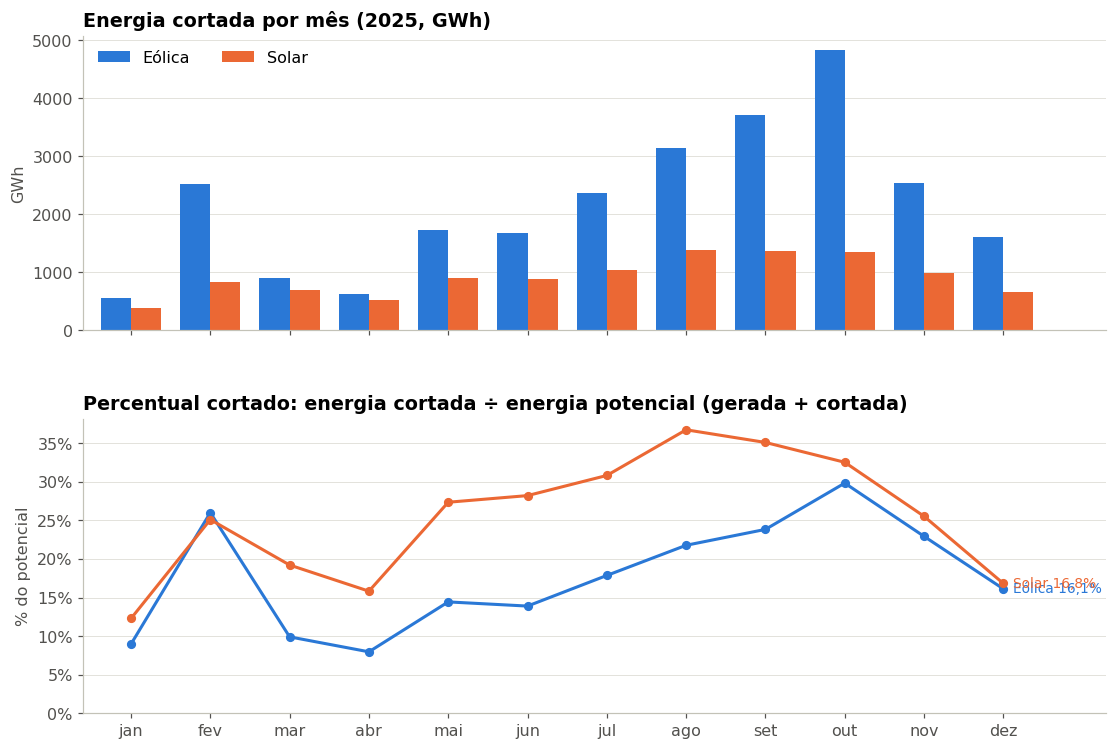

In [25]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"hspace": 0.3})
largura = 0.38
for k, fonte in enumerate(FONTES):
    serie = p1[p1["fonte"] == fonte]
    ax1.bar(serie["mes"] + (k - 0.5) * largura, serie["cortada_mwh"] / 1000, width=largura, color=COR_FONTE[fonte],
            label=NOME_FONTE[fonte])
    ax2.plot(serie["mes"], serie["pct_cortado"], color=COR_FONTE[fonte], lw=2, marker="o", ms=5)
    rotulo_fim(ax2, serie["mes"].iloc[-1], serie["pct_cortado"].iloc[-1], f"{NOME_FONTE[fonte]} {pct(serie['pct_cortado'].iloc[-1])}",
               COR_FONTE[fonte])
ax1.set_title(f"Energia cortada por mês ({ANO}, GWh)")
ax1.set_ylabel("GWh")
ax1.legend(loc="upper left", ncol=2)
ax1.grid(axis="x", visible=False)
ax2.set_title("Percentual cortado: energia cortada ÷ energia potencial (gerada + cortada)")
ax2.set_ylabel("% do potencial")
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: pct(v, 0)))
ax2.set_ylim(0, None)
ax2.set_xlim(0.4, 13.3)
ax2.set_xticks(range(1, 13), MESES_CURTOS)
ax2.grid(axis="x", visible=False)
salvar_figura(fig, "p1_corte_mensal_por_fonte")
plt.show()

In [26]:
res1 = {}
partes = []
for fonte in FONTES:
    serie = p1[p1["fonte"] == fonte].sort_values("mes")
    rho, p_rho = stats.spearmanr(serie["mes"], serie["pct_cortado"]) if len(serie) >= 4 else (np.nan, np.nan)
    s1 = serie[serie["mes"] <= 6][["cortada_mwh", "potencial_mwh"]].sum()
    s2 = serie[serie["mes"] > 6][["cortada_mwh", "potencial_mwh"]].sum()
    pico = serie.loc[serie["pct_cortado"].idxmax()]
    res1[fonte] = {"pct": anual.loc[fonte, "pct_cortado"], "cortada": anual.loc[fonte, "cortada_mwh"],
                   "pico_mes": int(pico["mes"]), "pico_pct": pico["pct_cortado"], "rho": rho, "p_rho": p_rho,
                   "s1": 100 * s1["cortada_mwh"] / s1["potencial_mwh"] if s1["potencial_mwh"] else np.nan,
                   "s2": 100 * s2["cortada_mwh"] / s2["potencial_mwh"] if s2["potencial_mwh"] else np.nan}
    tendencia = ("tendência de **alta** ao longo do ano" if (rho > 0 and p_rho < 0.05) else
                 "tendência de **queda** ao longo do ano" if (rho < 0 and p_rho < 0.05) else "sem tendência significativa")
    partes.append(f"**{NOME_FONTE[fonte]}:** {energia(res1[fonte]['cortada'])} cortados, **{pct(res1[fonte]['pct'])} do potencial**; "
                  f"pico em {NOMES_MESES[res1[fonte]['pico_mes'] - 1]} ({pct(res1[fonte]['pico_pct'])}); "
                  f"{pct(res1[fonte]['s1'])} no 1º semestre e {pct(res1[fonte]['s2'])} no 2º; {tendencia} (ρ = {num(rho, 2)}, {fp(p_rho)}).")
jan_ago = p1[p1["mes"] <= 8][["cortada_mwh", "potencial_mwh"]].sum()
pct_jan_ago = 100 * jan_ago["cortada_mwh"] / jan_ago["potencial_mwh"]
fonte_max = max(FONTES, key=lambda f: res1[f]["pct"])
total = anual.loc["total"]
texto = (f"Em {ANO}, as usinas eólicas e solares do conjunto analisado deixaram de gerar **{energia(total['cortada_mwh'])}** por cortes, "
         f"**{pct(total['pct_cortado'])} da energia que poderiam ter produzido**. Isso equivale a uma usina de "
         f"**{num(total['cortada_mw_medios'])} MW médios** parada o ano inteiro. "
         f"{pct(total['pct_intervalos_restritos'])} dos intervalos usina × meia hora tiveram alguma restrição. "
         + " ".join(partes)
         + f" De janeiro a agosto, o percentual cortado das duas fontes juntas foi {pct(pct_jan_ago)}; a estimativa de mercado citada "
         f"na Seção 1.1 era de 17,6% para o mesmo período"
         + (", o que confirma a ordem de grandeza." if abs(pct_jan_ago - 17.6) <= 5 else
            ". A diferença pode vir de definições distintas de potencial e do conjunto de usinas considerado (ver discussão)."))
if cob_media < 90:
    texto += (f" **Ressalva:** a cobertura média da base foi de {pct(cob_media)} dos intervalos esperados (Seção 5); "
              "os percentuais valem para os intervalos registrados.")
RESUMO["P1"] = texto
RES["P1"] = {"pct_total": total["pct_cortado"], "pct_eolica": res1.get("eolica", {}).get("pct", np.nan),
             "pct_solar": res1.get("solar", {}).get("pct", np.nan), "pct_max": res1[fonte_max]["pct"], "fonte_max": fonte_max,
             "cortada_mwh": total["cortada_mwh"], "pct_jan_ago": pct_jan_ago}
mostrar("**Leitura automática — P1.** " + texto)

**Leitura automática — P1.** Em 2025, as usinas eólicas e solares do conjunto analisado deixaram de gerar **37,22 TWh** por cortes, **20,7% da energia que poderiam ter produzido**. Isso equivale a uma usina de **4.249 MW médios** parada o ano inteiro. 37,0% dos intervalos usina × meia hora tiveram alguma restrição. **Eólica:** 26,22 TWh cortados, **19,1% do potencial**; pico em outubro (29,8%); 14,1% no 1º semestre e 22,6% no 2º; sem tendência significativa (ρ = 0,51, p = 0,090). **Solar:** 11,00 TWh cortados, **25,7% do potencial**; pico em agosto (36,8%); 21,3% no 1º semestre e 29,5% no 2º; sem tendência significativa (ρ = 0,47, p = 0,124). De janeiro a agosto, o percentual cortado das duas fontes juntas foi 18,1%; a estimativa de mercado citada na Seção 1.1 era de 17,6% para o mesmo período, o que confirma a ordem de grandeza.

**Discussão (P1).** O percentual cortado é a medida que permite comparar fontes e meses de tamanhos diferentes. A energia em GWh mostra o tamanho do problema; o percentual mostra a intensidade. Uma fonte pode ter menos GWh cortados e, ainda assim, perder uma parcela maior do que poderia gerar. As duas medidas juntas dizem onde está o maior volume e onde está o maior risco para o investidor. A variação ao longo do ano acompanha a sazonalidade dos ventos (mais fortes no 2º semestre no Nordeste), a da irradiação e a da carga. Um corte que cresce no 2º semestre, quando venta mais, sugere que a rede e a demanda não acompanham a oferta nos meses de maior produção. A comparação com a estimativa de mercado é um teste de sanidade: as duas contas usam definições de potencial diferentes, mas devem ter a mesma ordem de grandeza. **Decisão apoiada:** dimensionar o problema por fonte e priorizar a fonte com maior percentual cortado nas próximas perguntas.

### P2 — Em quais estados e em quais usinas os cortes se concentram?

**Método:** energia cortada e percentual cortado por UF e fonte; curva de concentração das usinas (participação acumulada da energia cortada, das usinas mais afetadas para as menos afetadas) e quantas usinas respondem por 80% do corte.

In [27]:
SQL_P2_UF = """
SELECT
  COALESCE(u.uf, 'NI') AS uf,
  u.fonte,
  COUNT(DISTINCT u.sk_usina) AS usinas,
  ROUND(SUM(f.energia_cortada_mwh), 3) AS cortada_mwh,
  ROUND(SUM(f.energia_potencial_mwh), 3) AS potencial_mwh
FROM {DW}.fato_restricao AS f
JOIN {DW}.dim_usina AS u ON f.sk_usina = u.sk_usina
GROUP BY COALESCE(u.uf, 'NI'), u.fonte
"""
SQL_P2_USINA = """
SELECT
  u.sk_usina,
  u.id_ons,
  u.nom_usina,
  u.fonte,
  COALESCE(u.uf, 'NI') AS uf,
  COALESCE(u.id_subsistema, 'NI') AS subsistema,
  u.nom_agenteoperador,
  u.potencia_disponivel_max_mw,
  ROUND(SUM(f.energia_cortada_mwh), 3) AS cortada_mwh,
  ROUND(SUM(f.energia_potencial_mwh), 3) AS potencial_mwh,
  ROUND(100 * SAFE_DIVIDE(SUM(f.energia_cortada_mwh), SUM(f.energia_potencial_mwh)), 2) AS pct_cortado,
  COUNTIF(f.flag_restrito) AS intervalos_restritos
FROM {DW}.fato_restricao AS f
JOIN {DW}.dim_usina AS u ON f.sk_usina = u.sk_usina
GROUP BY u.sk_usina, u.id_ons, u.nom_usina, u.fonte, u.uf, u.id_subsistema, u.nom_agenteoperador, u.potencia_disponivel_max_mw
ORDER BY cortada_mwh DESC
"""
p2_uf = consultar(SQL_P2_UF, "p2_corte_por_uf")
p2_uf["pct_cortado"] = 100 * p2_uf["cortada_mwh"] / p2_uf["potencial_mwh"].where(p2_uf["potencial_mwh"] > 0)
salvar_tabela(p2_uf, "p2_corte_por_uf")
p2_us = consultar(SQL_P2_USINA, "p2_corte_por_usina").sort_values("cortada_mwh", ascending=False).reset_index(drop=True)
total_corte = p2_us["cortada_mwh"].sum()
p2_us["participacao_pct"] = 100 * p2_us["cortada_mwh"] / total_corte
p2_us["participacao_acumulada_pct"] = p2_us["participacao_pct"].cumsum()
salvar_tabela(p2_us, "p2_corte_por_usina")
mostrar("**As 10 usinas com mais energia cortada:**")
display(p2_us.head(10)[["nom_usina", "fonte", "uf", "subsistema", "nom_agenteoperador", "cortada_mwh", "pct_cortado",
                        "participacao_pct", "participacao_acumulada_pct"]].round(2))

**As 10 usinas com mais energia cortada:**

,nom_usina,fonte,uf,subsistema,nom_agenteoperador,cortada_mwh,pct_cortado,participacao_pct,participacao_acumulada_pct
0,Conj. Janaúba,solar,MG,SE,ELERA RENOVAVEIS,1126074.90,33.51,3.03,3.03
1,Conj. Arinos 2 500 kV,solar,MG,SE,VOLTALIA,711026.96,22.69,1.91,4.94
2,Conj. Vista Alegre - Janaúba,solar,MG,SE,IQONY,676946.37,34.03,1.82,6.76
3,Conj. Rio do Vento,eolica,RN,NE,CVER,642922.75,26.12,1.73,8.48
4,Conj. Caju,eolica,RN,NE,AUREN OPERAÇÕES,621587.08,20.79,1.67,10.15
5,Conj. Serra do Mel A,eolica,RN,NE,VOLTALIA,599804.53,41.62,1.61,11.76
6,Conj. Laranjeiras,eolica,BA,NE,IQONY,565362.60,23.32,1.52,13.28
7,Conj. Lagoa dos Ventos,eolica,PI,NE,ENEL,551604.78,16.02,1.48,14.77
8,Conj. Rio do Vento Expansão,eolica,RN,NE,CVER,533052.25,19.80,1.43,16.20
9,Conj. Serra do Mel B,eolica,RN,NE,ECHOENERGIA,517631.59,38.49,1.39,17.59


Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/graficos/p2_corte_por_uf_e_concentracao.png


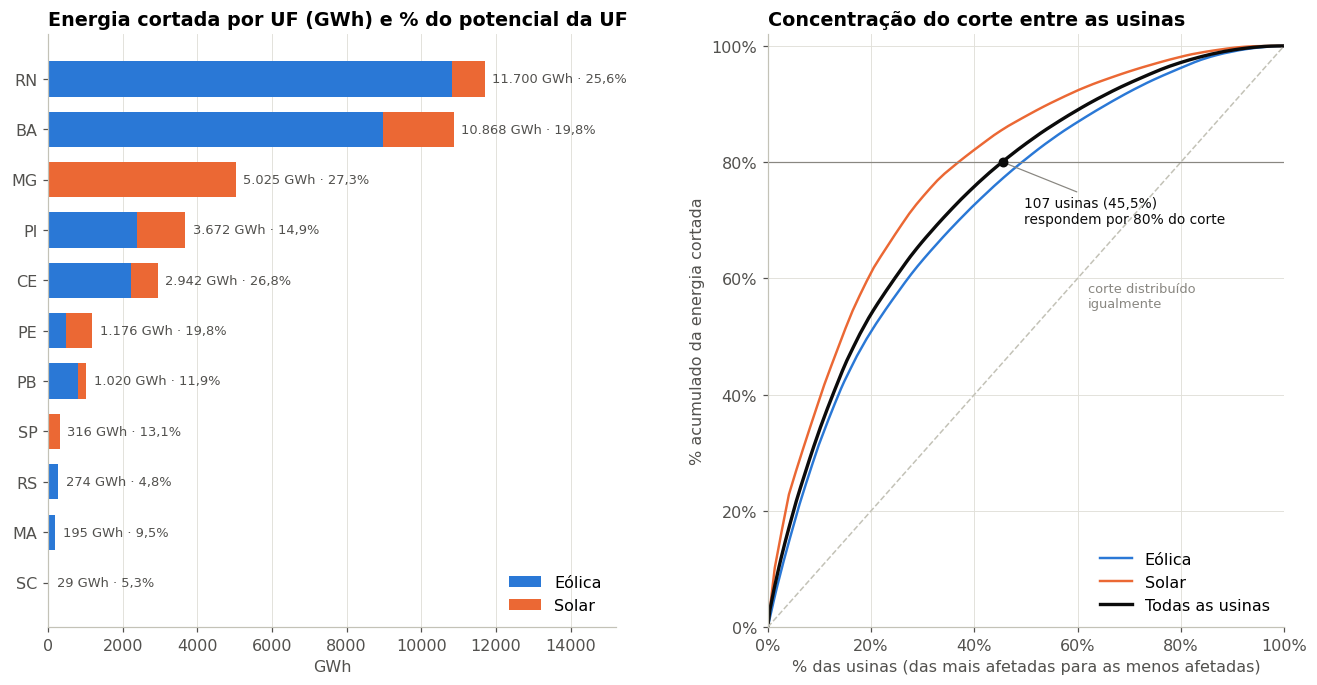

In [28]:
def concentracao(df):
    ordenado = df.sort_values("cortada_mwh", ascending=False)
    acumulado = 100 * ordenado["cortada_mwh"].cumsum() / ordenado["cortada_mwh"].sum()
    n80 = int((acumulado < 80).sum()) + 1
    x = np.r_[0, 100 * np.arange(1, len(ordenado) + 1) / len(ordenado)]
    return x, np.r_[0, acumulado.to_numpy()], n80, 100 * n80 / len(ordenado)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 7), gridspec_kw={"wspace": 0.28, "width_ratios": [1.1, 1]})
tab_uf = p2_uf.pivot_table(index="uf", columns="fonte", values="cortada_mwh", aggfunc="sum", fill_value=0)
for fonte in FONTES:
    if fonte not in tab_uf:
        tab_uf[fonte] = 0.0
tab_uf["total"] = tab_uf[list(FONTES)].sum(axis=1)
pot_uf = p2_uf.groupby("uf")["potencial_mwh"].sum()
tab_uf["pct"] = 100 * tab_uf["total"] / pot_uf.reindex(tab_uf.index)
tab_uf = tab_uf[tab_uf["total"] > 0].sort_values("total")
y = np.arange(len(tab_uf))
esquerda = np.zeros(len(tab_uf))
for fonte in FONTES:
    ax1.barh(y, tab_uf[fonte] / 1000, left=esquerda / 1000, color=COR_FONTE[fonte], height=0.7, label=NOME_FONTE[fonte])
    esquerda += tab_uf[fonte].to_numpy()
for i, (tot, p) in enumerate(zip(tab_uf["total"], tab_uf["pct"])):
    ax1.annotate(f"{num(tot / 1000, 0)} GWh · {pct(p)}", (tot / 1000, i), xytext=(5, 0), textcoords="offset points",
                 va="center", fontsize=8.5, color=TINTA_2)
ax1.set_xlim(0, 1.3 * tab_uf["total"].max() / 1000)
ax1.set_yticks(y, tab_uf.index)
ax1.set_title("Energia cortada por UF (GWh) e % do potencial da UF")
ax1.set_xlabel("GWh")
ax1.legend(loc="lower right")
ax1.grid(axis="y", visible=False)

x_tot, y_tot, n80, pct_usinas_80 = concentracao(p2_us)
for fonte in FONTES:
    sub = p2_us[p2_us["fonte"] == fonte]
    if len(sub) and sub["cortada_mwh"].sum() > 0:
        xf, yf, _, _ = concentracao(sub)
        ax2.plot(xf, yf, color=COR_FONTE[fonte], lw=1.6, label=NOME_FONTE[fonte])
ax2.plot(x_tot, y_tot, color=TINTA, lw=2.2, label="Todas as usinas")
ax2.plot([0, 100], [0, 100], color=CINZA_CLARO, lw=1, ls="--")
ax2.text(62, 55, "corte distribuído\nigualmente", color=CINZA, fontsize=8.5, rotation=0)
ax2.axhline(80, color=CINZA, lw=0.8)
ax2.scatter([pct_usinas_80], [80], color=TINTA, zorder=4, s=30)
a_esquerda = pct_usinas_80 > 50
ax2.annotate(f"{num(n80)} usinas ({pct(pct_usinas_80)})\nrespondem por 80% do corte", (pct_usinas_80, 80),
             xytext=(-14, 22) if a_esquerda else (14, -40), textcoords="offset points", fontsize=9, color=TINTA,
             ha="right" if a_esquerda else "left", arrowprops=dict(arrowstyle="-", color=CINZA, lw=0.8))
ax2.set_xlim(0, 100); ax2.set_ylim(0, 102)
ax2.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: pct(v, 0)))
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: pct(v, 0)))
ax2.set_xlabel("% das usinas (das mais afetadas para as menos afetadas)")
ax2.set_ylabel("% acumulado da energia cortada")
ax2.set_title("Concentração do corte entre as usinas")
ax2.legend(loc="lower right")
salvar_figura(fig, "p2_corte_por_uf_e_concentracao")
plt.show()

In [29]:
uf_top = tab_uf.sort_values("total", ascending=False)
share_uf = 100 * uf_top["total"] / uf_top["total"].sum()
uf_pct_max = tab_uf[pot_uf.reindex(tab_uf.index) > 0.01 * pot_uf.sum()].sort_values("pct", ascending=False)
por_sub = p2_us.groupby("subsistema")["cortada_mwh"].sum().sort_values(ascending=False)
share_ne = 100 * por_sub.get("NE", 0) / por_sub.sum()
top10 = p2_us.head(10)
por_agente = p2_us.groupby("nom_agenteoperador", dropna=False)["cortada_mwh"].sum().sort_values(ascending=False)
n_usinas_corte = int((p2_us["cortada_mwh"] > 0).sum())
texto = (f"**{uf_top.index[0]}** concentra **{pct(share_uf.iloc[0])}** da energia cortada"
         + (f", seguida de {uf_top.index[1]} ({pct(share_uf.iloc[1])})" if len(uf_top) > 1 else "")
         + (f" e {uf_top.index[2]} ({pct(share_uf.iloc[2])})" if len(uf_top) > 2 else "")
         + f"; as três primeiras somam {pct(share_uf.head(3).sum())}. O subsistema Nordeste responde por **{pct(share_ne)}** do corte. "
         + (f"Entre as UFs com pelo menos 1% do potencial, a de maior percentual cortado é {uf_pct_max.index[0]} "
            f"({pct(uf_pct_max['pct'].iloc[0])} do seu potencial). " if len(uf_pct_max) else "")
         + f"Das {num(len(p2_us))} usinas (ou conjuntos) com registros, {num(n_usinas_corte)} tiveram algum corte. "
         f"**{num(n80)} usinas ({pct(pct_usinas_80)} do total) respondem por 80% da energia cortada**, e as 10 mais afetadas por "
         f"{pct(top10['participacao_pct'].sum())}. A mais afetada é {top10['nom_usina'].iloc[0]} ({NOME_FONTE[top10['fonte'].iloc[0]]}, "
         f"{top10['uf'].iloc[0]}), com {energia(top10['cortada_mwh'].iloc[0])} cortados ({pct(top10['pct_cortado'].iloc[0])} do seu potencial). "
         f"O agente operador com mais energia cortada responde por {pct(100 * por_agente.iloc[0] / por_agente.sum())} do total.")
RESUMO["P2"] = texto
RES["P2"] = {"pct_usinas_80": pct_usinas_80, "n80": n80, "n_usinas": len(p2_us), "uf_top": uf_top.index[0],
             "share_uf_top": share_uf.iloc[0], "share_top3": share_uf.head(3).sum(), "share_ne": share_ne,
             "share_top10": top10["participacao_pct"].sum()}
mostrar("**Leitura automática — P2.** " + texto)

**Leitura automática — P2.** **RN** concentra **31,4%** da energia cortada, seguida de BA (29,2%) e MG (13,5%); as três primeiras somam 74,1%. O subsistema Nordeste responde por **84,3%** do corte. Entre as UFs com pelo menos 1% do potencial, a de maior percentual cortado é MG (27,3% do seu potencial). Das 235 usinas (ou conjuntos) com registros, 235 tiveram algum corte. **107 usinas (45,5% do total) respondem por 80% da energia cortada**, e as 10 mais afetadas por 17,6%. A mais afetada é Conj. Janaúba (Solar, MG), com 1,13 TWh cortados (33,5% do seu potencial). O agente operador com mais energia cortada responde por 10,0% do total.

**Discussão (P2).** O corte não se espalha pelo país: ele segue a geografia da expansão eólica e solar, concentrada no Nordeste e no norte de Minas Gerais, regiões que exportam energia para os centros de carga do Sudeste por poucas linhas de transmissão. A curva de concentração diz se a solução pode ser **localizada**. Se poucas usinas respondem pela maior parte do corte, obras de transmissão e reforços de conexão bem escolhidos resolvem muito com pouco investimento. Se o corte for difuso, a causa tende a ser sistêmica, e a solução passa por gestão de oferta e demanda (P3). O percentual cortado por usina também é informação de risco para quem financia ou compra energia dessas usinas. **Decisão apoiada:** priorizar reforços de transmissão e de conexão nas UFs e nos pontos de conexão das usinas do topo da curva.

### P3 — Por que se corta: qual o peso de cada motivo e da origem, e isso mudou ao longo do ano?

**Método:** soma das parcelas de energia cortada por motivo (rateio da regra R09) por fonte e mês; participação da origem (local ou sistêmica) a partir do motivo e da origem principais de cada intervalo (`dim_restricao`). Os motivos são agrupados por **natureza**: elétrica (REL e CNF, problemas de rede) e energética (ENE, excesso de oferta diante da carga).

In [30]:
SQL_P3_MOTIVO = """
SELECT
  u.fonte,
  d.mes,
  ROUND(SUM(f.energia_cortada_ene_mwh), 3) AS ene_mwh,
  ROUND(SUM(f.energia_cortada_cnf_mwh), 3) AS cnf_mwh,
  ROUND(SUM(f.energia_cortada_rel_mwh), 3) AS rel_mwh,
  ROUND(SUM(f.energia_cortada_par_mwh), 3) AS par_mwh,
  ROUND(SUM(f.energia_cortada_ni_mwh), 3) AS ni_mwh,
  ROUND(SUM(f.energia_cortada_mwh), 3) AS total_mwh
FROM {DW}.fato_restricao AS f
JOIN {DW}.dim_usina AS u ON f.sk_usina = u.sk_usina
JOIN {DW}.dim_data AS d ON f.sk_data = d.sk_data
WHERE f.flag_restrito
GROUP BY u.fonte, d.mes
ORDER BY u.fonte, d.mes
"""
SQL_P3_ORIGEM = """
SELECT
  u.fonte,
  r.cod_razao,
  r.natureza,
  r.cod_origem,
  r.nome_origem,
  COUNT(*) AS intervalos,
  ROUND(SUM(f.energia_cortada_mwh), 3) AS cortada_mwh
FROM {DW}.fato_restricao AS f
JOIN {DW}.dim_usina AS u ON f.sk_usina = u.sk_usina
JOIN {DW}.dim_restricao AS r ON f.sk_restricao = r.sk_restricao
WHERE f.flag_restrito
GROUP BY u.fonte, r.cod_razao, r.natureza, r.cod_origem, r.nome_origem
"""
p3 = consultar(SQL_P3_MOTIVO, "p3_motivo_por_fonte_e_mes")
p3_origem = consultar(SQL_P3_ORIGEM, "p3_motivo_e_origem")
salvar_tabela(p3, "p3_motivo_por_fonte_e_mes")
salvar_tabela(p3_origem, "p3_motivo_e_origem")
COLS = {m: f"{m.lower()}_mwh" for m in ORDEM_MOTIVOS}
por_fonte = p3.groupby("fonte")[list(COLS.values()) + ["total_mwh"]].sum()
por_fonte.loc["total"] = por_fonte.sum()
participacao = 100 * por_fonte[list(COLS.values())].div(por_fonte["total_mwh"], axis=0)
participacao.columns = ORDEM_MOTIVOS
matriz = p3_origem.pivot_table(index="cod_razao", columns="cod_origem", values="cortada_mwh", aggfunc="sum", fill_value=0)
matriz_pct = (100 * matriz / matriz.to_numpy().sum()).round(1)
display(participacao.round(1))
mostrar("**Energia cortada por motivo × origem principal do intervalo (% do total):**")
display(matriz_pct)

,ENE,CNF,REL,PAR,NI
fonte,,,,,
eolica,50.8,36.6,12.5,0.0,0.0
solar,61.3,26.2,12.5,0.0,0.0
total,53.9,33.5,12.5,0.0,0.0


**Energia cortada por motivo × origem principal do intervalo (% do total):**

cod_origem,LOC,NI,SIS
cod_razao,,,
CNF,14.5,0.0,18.8
ENE,0.0,0.0,53.7
REL,1.2,0.0,11.9


Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/graficos/p3_motivos_do_corte.png


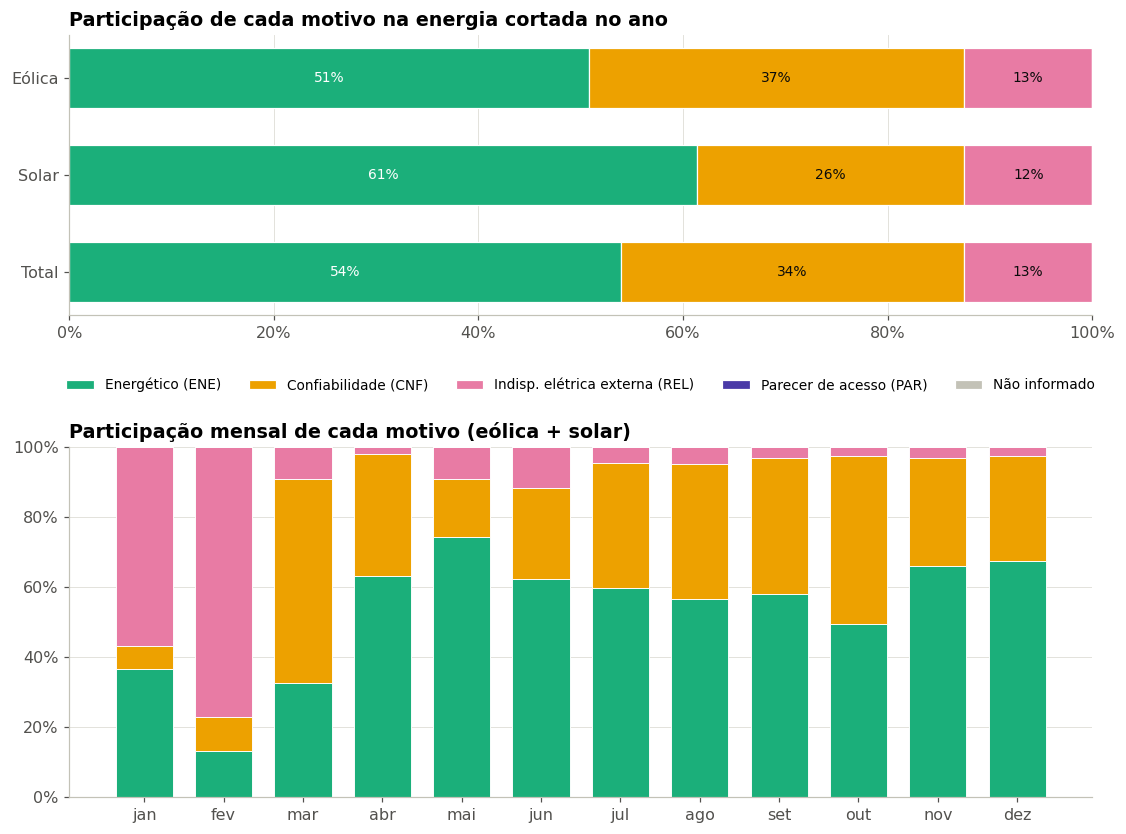

In [31]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), gridspec_kw={"hspace": 0.42, "height_ratios": [0.8, 1]})
linhas = [f for f in FONTES if f in participacao.index] + ["total"]
rotulos = [NOME_FONTE.get(f, "Total") for f in linhas]
for i, linha in enumerate(linhas):
    esquerda = 0
    for motivo in ORDEM_MOTIVOS:
        v = participacao.loc[linha, motivo]
        ax1.barh(i, v, left=esquerda, color=COR_MOTIVO[motivo], height=0.62, edgecolor="white", linewidth=0.8,
                 label=NOME_MOTIVO[motivo] if i == 0 else None)
        if v >= 5:
            ax1.text(esquerda + v / 2, i, pct(v, 0), ha="center", va="center", fontsize=9,
                     color="white" if motivo in ("ENE", "PAR") else TINTA)
        esquerda += v
ax1.set_yticks(range(len(linhas)), rotulos)
ax1.invert_yaxis()
ax1.set_xlim(0, 100)
ax1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: pct(v, 0)))
ax1.set_title("Participação de cada motivo na energia cortada no ano")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=5, fontsize=9)
ax1.grid(axis="y", visible=False)

mensal = p3.groupby("mes")[list(COLS.values()) + ["total_mwh"]].sum()
base = np.zeros(len(mensal))
for motivo in ORDEM_MOTIVOS:
    v = (100 * mensal[COLS[motivo]] / mensal["total_mwh"].where(mensal["total_mwh"] > 0)).fillna(0).to_numpy()
    ax2.bar(mensal.index, v, bottom=base, color=COR_MOTIVO[motivo], width=0.72, edgecolor="white", linewidth=0.6)
    base += v
ax2.set_xticks(range(1, 13), MESES_CURTOS)
ax2.set_ylim(0, 100)
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: pct(v, 0)))
ax2.set_title("Participação mensal de cada motivo (eólica + solar)")
ax2.grid(axis="x", visible=False)
salvar_figura(fig, "p3_motivos_do_corte")
plt.show()

In [32]:
tot = participacao.loc["total"]
pct_eletrico = tot["REL"] + tot["CNF"]
origem_total = p3_origem.groupby("cod_origem")["cortada_mwh"].sum()
pct_sis = 100 * origem_total.get("SIS", 0) / origem_total.sum()
pct_loc = 100 * origem_total.get("LOC", 0) / origem_total.sum()
sem = p3.assign(semestre=np.where(p3["mes"] <= 6, 1, 2)).groupby("semestre")[["ene_mwh", "total_mwh"]].sum()
ene_s = {s: 100 * sem.loc[s, "ene_mwh"] / sem.loc[s, "total_mwh"] if s in sem.index and sem.loc[s, "total_mwh"] else np.nan for s in (1, 2)}
ene_mes = 100 * mensal[COLS["ENE"]] / mensal["total_mwh"].where(mensal["total_mwh"] > 0)
motivo_lider = tot[["ENE", "CNF", "REL", "PAR"]].idxmax()
texto = (f"No ano, o motivo **{NOME_MOTIVO[motivo_lider]}** lidera, com **{pct(tot[motivo_lider])}** da energia cortada. "
         f"O motivo energético (ENE, excesso de oferta) responde por **{pct(tot['ENE'])}**, e os motivos elétricos "
         f"(confiabilidade CNF + indisponibilidade externa REL) por **{pct(pct_eletrico)}**; parecer de acesso (PAR) por {pct(tot['PAR'])} "
         f"e intervalos sem motivo informado por {pct(tot['NI'])}. "
         + " ".join(f"{NOME_FONTE[f]}: ENE {pct(participacao.loc[f, 'ENE'])}, elétricos {pct(participacao.loc[f, 'REL'] + participacao.loc[f, 'CNF'])}."
                    for f in FONTES if f in participacao.index)
         + f" Quanto à origem, {pct(pct_sis)} da energia foi cortada em restrições **sistêmicas** e {pct(pct_loc)} em restrições **locais**. "
         f"A participação do motivo energético foi de {pct(ene_s[1])} no 1º semestre e {pct(ene_s[2])} no 2º, variando de "
         f"{pct(ene_mes.min())} ({NOMES_MESES[int(ene_mes.idxmin()) - 1]}) a {pct(ene_mes.max())} ({NOMES_MESES[int(ene_mes.idxmax()) - 1]}).")
RESUMO["P3"] = texto
RES["P3"] = {"pct_ene": tot["ENE"], "pct_eletrico": pct_eletrico, "pct_sis": pct_sis, "motivo_lider": motivo_lider,
             "ene_s1": ene_s[1], "ene_s2": ene_s[2], "pct_ni": tot["NI"]}
mostrar("**Leitura automática — P3.** " + texto)

**Leitura automática — P3.** No ano, o motivo **Energético (ENE)** lidera, com **53,9%** da energia cortada. O motivo energético (ENE, excesso de oferta) responde por **53,9%**, e os motivos elétricos (confiabilidade CNF + indisponibilidade externa REL) por **46,1%**; parecer de acesso (PAR) por 0,0% e intervalos sem motivo informado por 0,0%. Eólica: ENE 50,8%, elétricos 49,2%. Solar: ENE 61,3%, elétricos 38,7%. Quanto à origem, 84,4% da energia foi cortada em restrições **sistêmicas** e 15,6% em restrições **locais**. A participação do motivo energético foi de 45,7% no 1º semestre e 58,0% no 2º, variando de 13,1% (fevereiro) a 74,5% (maio).

**Discussão (P3).** É a pergunta que mais orienta a política. Cortes **elétricos e locais** (REL e CNF) indicam gargalos de rede em pontos específicos e se resolvem com **transmissão**, com prazos de anos e custo concentrado. Cortes **energéticos e sistêmicos** (ENE) indicam que o sistema como um todo tem mais oferta do que consumo naquele momento. Nesse caso, mais linhas não resolvem: a solução é **deslocar consumo ou armazenar** energia (sinais de preço por horário, resposta da demanda, baterias, hidrelétricas reversíveis) e **coordenar a expansão** da geração, inclusive a distribuída, que o ONS não corta e que reduz a carga líquida no meio do dia. A matriz motivo × origem confere a coerência dos dados: espera-se ENE majoritariamente sistêmico e CNF/REL majoritariamente local. A parcela "não informado" mede uma limitação da base. **Decisão apoiada:** dividir o esforço entre transmissão e gestão de oferta e demanda na proporção do peso de cada natureza de motivo.

### P4 — Em que horários e dias os cortes acontecem?

**Método:** energia cortada por meia hora do dia e fonte; mapa de calor mês × hora; média diária de corte em dias úteis, sábados e domingos ou feriados (`dim_data.tipo_dia`). A janela do meio-dia (09h00 a 15h59) vem do diagnóstico do ONS.

In [33]:
SQL_P4_HORA = """
SELECT
  u.fonte,
  h.sk_horario,
  h.indice_meia_hora,
  h.hora_minuto,
  h.janela_meio_dia,
  COUNTIF(f.flag_restrito) AS intervalos_restritos,
  ROUND(SUM(f.energia_cortada_mwh), 3) AS cortada_mwh
FROM {DW}.fato_restricao AS f
JOIN {DW}.dim_usina AS u ON f.sk_usina = u.sk_usina
JOIN {DW}.dim_horario AS h ON f.sk_horario = h.sk_horario
GROUP BY u.fonte, h.sk_horario, h.indice_meia_hora, h.hora_minuto, h.janela_meio_dia
ORDER BY u.fonte, h.indice_meia_hora
"""
SQL_P4_MES_HORA = """
SELECT
  u.fonte,
  d.mes,
  h.hora,
  ROUND(SUM(f.energia_cortada_mwh), 3) AS cortada_mwh
FROM {DW}.fato_restricao AS f
JOIN {DW}.dim_usina AS u ON f.sk_usina = u.sk_usina
JOIN {DW}.dim_data AS d ON f.sk_data = d.sk_data
JOIN {DW}.dim_horario AS h ON f.sk_horario = h.sk_horario
GROUP BY u.fonte, d.mes, h.hora
"""
SQL_P4_TIPO_DIA = """
SELECT
  fonte,
  tipo_dia,
  COUNT(*) AS dias,
  ROUND(AVG(cortada_mwh), 3) AS media_diaria_mwh
FROM (
  SELECT u.fonte, d.sk_data, d.tipo_dia, SUM(f.energia_cortada_mwh) AS cortada_mwh
  FROM {DW}.fato_restricao AS f
  JOIN {DW}.dim_usina AS u ON f.sk_usina = u.sk_usina
  JOIN {DW}.dim_data AS d ON f.sk_data = d.sk_data
  GROUP BY u.fonte, d.sk_data, d.tipo_dia
) AS diario
GROUP BY fonte, tipo_dia
"""
p4_hora = consultar(SQL_P4_HORA, "p4_corte_por_meia_hora")
p4_mes_hora = consultar(SQL_P4_MES_HORA, "p4_corte_mes_x_hora")
p4_dia = consultar(SQL_P4_TIPO_DIA, "p4_corte_por_tipo_de_dia")
p4_hora["janela_meio_dia"] = p4_hora["janela_meio_dia"].astype(bool)
for nome_tab, tab in [("p4_corte_por_meia_hora", p4_hora), ("p4_corte_mes_x_hora", p4_mes_hora), ("p4_corte_por_tipo_de_dia", p4_dia)]:
    salvar_tabela(tab, nome_tab)
display(p4_dia)

,fonte,tipo_dia,dias,media_diaria_mwh
0,eolica,domingo ou feriado,62,95856.594
1,eolica,dia útil,252,65342.145
2,eolica,sábado,51,74658.747
3,solar,dia útil,252,24049.055
4,solar,domingo ou feriado,62,50321.530
5,solar,sábado,51,35687.362


Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/graficos/p4_corte_por_horario_e_tipo_de_dia.png


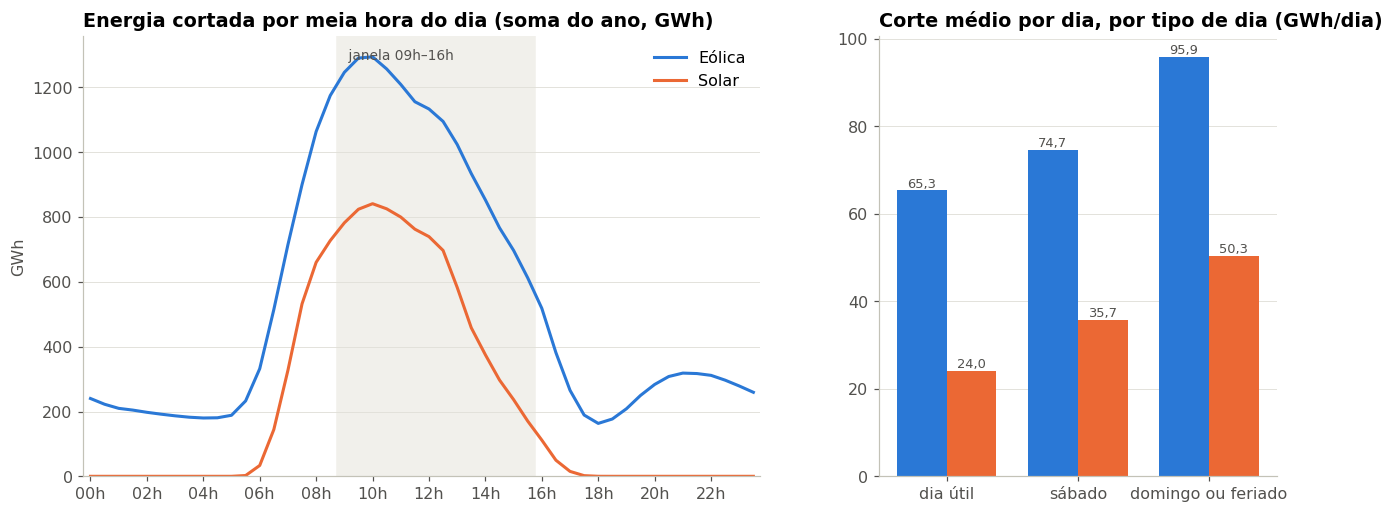

Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/graficos/p4_mapa_de_calor_mes_hora.png


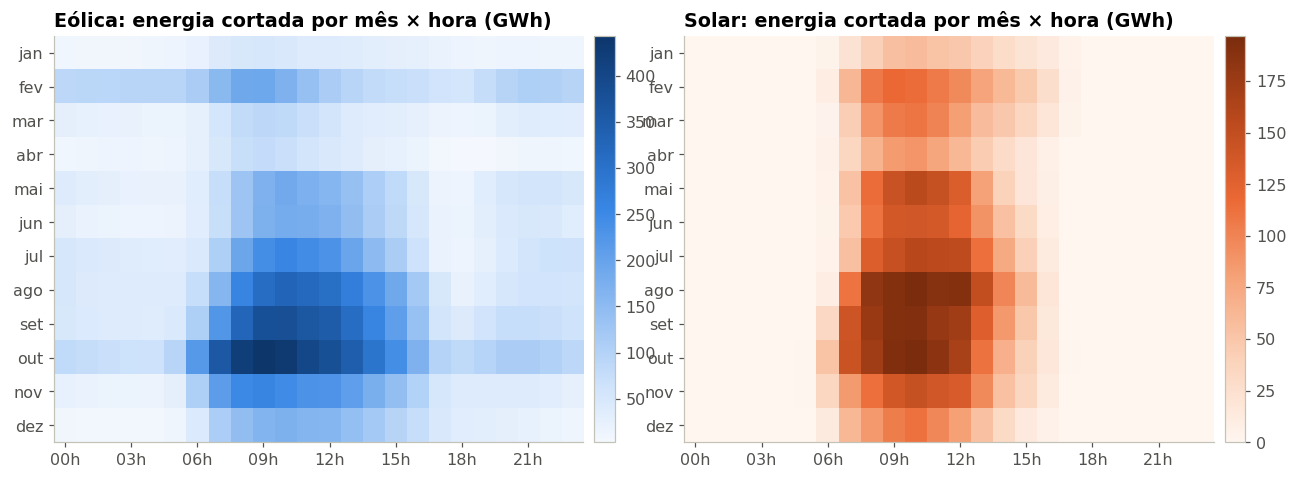

In [34]:
from matplotlib.colors import LinearSegmentedColormap
RAMPA = {"eolica": LinearSegmentedColormap.from_list("azuis", ["#f4f8fe"] + AZUIS),
         "solar": LinearSegmentedColormap.from_list("laranjas", ["#fff6f0", "#fbd3bb", "#f6a47a", "#eb6834", "#b8481c", "#7a2c0d"])}
inicio_janela, fim_janela = 2 * HORA_INICIO_MEIO_DIA, 2 * HORA_FIM_MEIO_DIA

fig = plt.figure(figsize=(14, 5.2))
grade = fig.add_gridspec(1, 2, width_ratios=[1.7, 1], wspace=0.22)
ax1, ax2 = fig.add_subplot(grade[0]), fig.add_subplot(grade[1])
ax1.axvspan(inicio_janela - 0.5, fim_janela - 0.5, color="#f1f0eb", zorder=0)
for fonte in FONTES:
    serie = p4_hora[p4_hora["fonte"] == fonte].sort_values("indice_meia_hora")
    ax1.plot(serie["indice_meia_hora"], serie["cortada_mwh"] / 1000, color=COR_FONTE[fonte], lw=2, label=NOME_FONTE[fonte])
ax1.text(inicio_janela, ax1.get_ylim()[1] * 0.97, f" janela {HORA_INICIO_MEIO_DIA:02d}h–{HORA_FIM_MEIO_DIA:02d}h", va="top",
         fontsize=9, color=TINTA_2)
ax1.set_xticks(range(0, 48, 4), [f"{h:02d}h" for h in range(0, 24, 2)])
ax1.set_xlim(-0.5, 47.5)
ax1.set_ylim(0, None)
ax1.set_title("Energia cortada por meia hora do dia (soma do ano, GWh)")
ax1.set_ylabel("GWh")
ax1.legend(loc="upper right")
ax1.grid(axis="x", visible=False)

tipos = ["dia útil", "sábado", "domingo ou feriado"]
largura = 0.38
for k, fonte in enumerate(FONTES):
    serie = p4_dia[p4_dia["fonte"] == fonte].set_index("tipo_dia").reindex(tipos)
    xs = np.arange(len(tipos)) + (k - 0.5) * largura
    ax2.bar(xs, serie["media_diaria_mwh"] / 1000, width=largura, color=COR_FONTE[fonte], label=NOME_FONTE[fonte])
    for xx, v in zip(xs, serie["media_diaria_mwh"] / 1000):
        if pd.notna(v):
            ax2.text(xx, v, num(v, 1), ha="center", va="bottom", fontsize=8.5, color=TINTA_2)
ax2.set_xticks(range(len(tipos)), tipos)
ax2.set_title("Corte médio por dia, por tipo de dia (GWh/dia)")
ax2.grid(axis="x", visible=False)
salvar_figura(fig, "p4_corte_por_horario_e_tipo_de_dia")
plt.show()

fig, eixos = plt.subplots(1, len(FONTES), figsize=(14, 4.8), gridspec_kw={"wspace": 0.12})
for eixo, fonte in zip(np.atleast_1d(eixos), FONTES):
    mapa = (p4_mes_hora[p4_mes_hora["fonte"] == fonte].pivot_table(index="mes", columns="hora", values="cortada_mwh", aggfunc="sum")
            .reindex(index=range(1, 13), columns=range(24)).fillna(0) / 1000)
    img = eixo.imshow(mapa.to_numpy(), aspect="auto", cmap=RAMPA[fonte], origin="upper")
    eixo.set_yticks(range(12), MESES_CURTOS)
    eixo.set_xticks(range(0, 24, 3), [f"{h:02d}h" for h in range(0, 24, 3)])
    eixo.grid(False)
    eixo.set_title(f"{NOME_FONTE[fonte]}: energia cortada por mês × hora (GWh)")
    fig.colorbar(img, ax=eixo, fraction=0.04, pad=0.02)
salvar_figura(fig, "p4_mapa_de_calor_mes_hora")
plt.show()

In [35]:
total_hora = p4_hora.groupby(["indice_meia_hora", "hora_minuto", "janela_meio_dia"])["cortada_mwh"].sum().reset_index()
pct_meio_dia = 100 * total_hora.loc[total_hora["janela_meio_dia"], "cortada_mwh"].sum() / total_hora["cortada_mwh"].sum()
res4 = {}
for fonte in FONTES:
    serie = p4_hora[p4_hora["fonte"] == fonte]
    if serie["cortada_mwh"].sum() == 0:
        continue
    pico = serie.loc[serie["cortada_mwh"].idxmax()]
    medias = p4_dia[p4_dia["fonte"] == fonte].set_index("tipo_dia")["media_diaria_mwh"]
    noite = serie[serie["indice_meia_hora"].isin(list(range(0, 12)) + list(range(36, 48)))]["cortada_mwh"].sum()
    res4[fonte] = {"meio_dia": 100 * serie.loc[serie["janela_meio_dia"], "cortada_mwh"].sum() / serie["cortada_mwh"].sum(),
                   "pico": pico["hora_minuto"], "noite": 100 * noite / serie["cortada_mwh"].sum(),
                   "razao_dom": medias.get("domingo ou feriado", np.nan) / medias.get("dia útil", np.nan)}
medias_total = p4_dia.groupby("tipo_dia")["media_diaria_mwh"].sum()
razao_domingo = medias_total.get("domingo ou feriado", np.nan) / medias_total.get("dia útil", np.nan)
razao_sabado = medias_total.get("sábado", np.nan) / medias_total.get("dia útil", np.nan)
texto = (f"**{pct(pct_meio_dia)} da energia cortada** nas duas fontes aconteceu entre {HORA_INICIO_MEIO_DIA:02d}h00 e "
         f"{HORA_FIM_MEIO_DIA - 1:02d}h59, janela que tem {pct(100 * (HORA_FIM_MEIO_DIA - HORA_INICIO_MEIO_DIA) / 24, 0)} das horas do dia. "
         + " ".join(f"{NOME_FONTE[f]}: {pct(r['meio_dia'])} no meio-dia, pico às {r['pico']}, {pct(r['noite'])} entre 18h e 6h."
                    for f, r in res4.items())
         + f" Em média, um domingo ou feriado tem **{num(razao_domingo, 2)} vez(es)** o corte de um dia útil, e um sábado "
         f"{num(razao_sabado, 2)} vez(es)"
         + (" — o corte cresce quando a carga cai." if razao_domingo > 1.1 else
            " — a diferença entre tipos de dia é pequena." if razao_domingo >= 0.9 else
            " — o corte é menor nos fins de semana."))
RESUMO["P4"] = texto
RES["P4"] = {"pct_meio_dia": pct_meio_dia, "razao_domingo": razao_domingo, "razao_sabado": razao_sabado,
             **{f"meio_dia_{f}": r["meio_dia"] for f, r in res4.items()}, **{f"pico_{f}": r["pico"] for f, r in res4.items()}}
mostrar("**Leitura automática — P4.** " + texto)

**Leitura automática — P4.** **61,7% da energia cortada** nas duas fontes aconteceu entre 09h00 e 15h59, janela que tem 29% das horas do dia. Eólica: 55,6% no meio-dia, pico às 10:00, 21,3% entre 18h e 6h. Solar: 76,3% no meio-dia, pico às 10:00, 0,0% entre 18h e 6h. Em média, um domingo ou feriado tem **1,64 vez(es)** o corte de um dia útil, e um sábado 1,23 vez(es) — o corte cresce quando a carga cai.

**Discussão (P4).** O padrão horário separa as duas fontes. A solar só gera de dia, então todo o seu corte cai no meio-dia por definição; o que importa é **quanto** do seu potencial se perde nessas horas. A eólica gera dia e noite: se o corte eólico também se concentra no meio-dia, a causa é a **sobreposição com o pico solar** numa hora de carga baixa, e não a falta de vento ou de rede à noite. Os fins de semana e feriados reforçam o diagnóstico: com a mesma oferta e menos consumo, o corte deveria crescer, e a razão domingo/dia útil mede isso. Um corte concentrado em poucas horas previsíveis é o caso mais favorável para **deslocar consumo** (tarifas por horário, recarga de veículos, bombeamento, produção industrial flexível) e para **armazenamento de curta duração**. **Decisão apoiada:** desenhar sinais de preço e programas de resposta da demanda para a janela do meio-dia, com atenção especial a domingos e feriados.

### P5 — Quanto duram os eventos de corte, e que parcela da energia uma bateria de 4 horas absorveria?

**Método:** a `fato_evento_corte` agrupa meias horas restritas consecutivas da mesma usina (R12). Para cada fonte: distribuição dos eventos e da energia por faixa de duração, curva acumulada da energia cortada pela duração do evento, medianas e percentil 90 da duração, e teste de Mann-Whitney entre as durações das duas fontes. Só entram eventos com energia cortada.

**Hipótese simplificadora:** um evento de até 4 horas "cabe" numa bateria de 4 horas com potência igual ao maior corte do evento (`corte_maximo_mw`), carregada durante o corte e descarregada depois. Na prática, a bateria também precisa estar vazia no início do evento.

In [36]:
SQL_P5_FAIXA = """
SELECT
  u.fonte,
  e.faixa_duracao,
  COUNT(*) AS eventos,
  ROUND(SUM(e.energia_cortada_mwh), 3) AS cortada_mwh,
  ROUND(AVG(e.duracao_h), 2) AS duracao_media_h,
  ROUND(AVG(e.corte_maximo_mw), 2) AS corte_maximo_medio_mw
FROM {DW}.fato_evento_corte AS e
JOIN {DW}.dim_usina AS u ON e.sk_usina = u.sk_usina
WHERE e.energia_cortada_mwh > 0
GROUP BY u.fonte, e.faixa_duracao
"""
SQL_P5_RESUMO = """
SELECT
  u.fonte,
  COUNT(*) AS eventos,
  COUNTIF(e.flag_cabe_bateria) AS eventos_cabem_bateria,
  APPROX_QUANTILES(e.duracao_h, 100)[OFFSET(50)] AS duracao_mediana_h,
  APPROX_QUANTILES(e.duracao_h, 100)[OFFSET(90)] AS duracao_p90_h,
  MAX(e.duracao_h) AS duracao_maxima_h,
  ROUND(SUM(e.energia_cortada_mwh), 3) AS cortada_mwh,
  ROUND(SUM(CASE WHEN e.flag_cabe_bateria THEN e.energia_cortada_mwh ELSE 0 END), 3) AS cortada_cabe_bateria_mwh,
  APPROX_QUANTILES(e.corte_maximo_mw, 100)[OFFSET(50)] AS corte_maximo_mediano_mw
FROM {DW}.fato_evento_corte AS e
JOIN {DW}.dim_usina AS u ON e.sk_usina = u.sk_usina
WHERE e.energia_cortada_mwh > 0
GROUP BY u.fonte
"""
SQL_P5_DISTRIBUICAO = """
SELECT
  u.fonte,
  e.intervalos,
  COUNT(*) AS eventos,
  ROUND(SUM(e.energia_cortada_mwh), 3) AS cortada_mwh
FROM {DW}.fato_evento_corte AS e
JOIN {DW}.dim_usina AS u ON e.sk_usina = u.sk_usina
WHERE e.energia_cortada_mwh > 0
GROUP BY u.fonte, e.intervalos
ORDER BY u.fonte, e.intervalos
"""
p5_faixa = consultar(SQL_P5_FAIXA, "p5_eventos_por_faixa")
p5 = consultar(SQL_P5_RESUMO, "p5_resumo_eventos")
p5_dist = consultar(SQL_P5_DISTRIBUICAO, "p5_distribuicao_duracao")
p5_faixa["faixa_duracao"] = pd.Categorical(p5_faixa["faixa_duracao"], categories=FAIXAS_DURACAO, ordered=True)
p5_faixa = p5_faixa.sort_values(["fonte", "faixa_duracao"])
p5_faixa["pct_energia"] = 100 * p5_faixa["cortada_mwh"] / p5_faixa.groupby("fonte")["cortada_mwh"].transform("sum")
p5_faixa["pct_eventos"] = 100 * p5_faixa["eventos"] / p5_faixa.groupby("fonte")["eventos"].transform("sum")
p5["pct_energia_cabe_bateria"] = 100 * p5["cortada_cabe_bateria_mwh"] / p5["cortada_mwh"]
p5["pct_eventos_cabem_bateria"] = 100 * p5["eventos_cabem_bateria"] / p5["eventos"]
for nome_tab, tab in [("p5_eventos_por_faixa", p5_faixa), ("p5_resumo_eventos", p5), ("p5_distribuicao_duracao", p5_dist)]:
    salvar_tabela(tab, nome_tab)
display(p5.round(2))
display(p5_faixa.round(2))

,fonte,eventos,eventos_cabem_bateria,duracao_mediana_h,duracao_p90_h,duracao_maxima_h,cortada_mwh,cortada_cabe_bateria_mwh,corte_maximo_mediano_mw,pct_energia_cabe_bateria,pct_eventos_cabem_bateria
0,solar,18594,1749,8.5,10.5,43.0,11000352.03,163179.8,66.14,1.48,9.41
1,eolica,45845,5131,10.0,17.5,477.0,26216925.44,361486.9,49.87,1.38,11.19


,fonte,faixa_duracao,eventos,cortada_mwh,duracao_media_h,corte_maximo_medio_mw,pct_energia,pct_eventos
1,eolica,até 1 h,435,8609.06,0.88,28.39,0.03,0.95
3,eolica,1 a 2 h,1214,54899.52,1.82,37.17,0.21,2.65
5,eolica,2 a 4 h,3482,297978.32,3.36,44.16,1.14,7.60
7,eolica,4 a 8 h,10367,1669794.92,6.36,49.28,6.37,22.61
8,eolica,8 a 12 h,20116,8973339.15,10.42,83.87,34.23,43.88
11,eolica,mais de 12 h,10231,15212304.48,25.32,117.99,58.02,22.32
0,solar,até 1 h,215,4426.14,0.93,29.75,0.04,1.16
2,solar,1 a 2 h,341,22528.44,1.83,59.66,0.20,1.83
4,solar,2 a 4 h,1193,136225.22,3.30,61.66,1.24,6.42
6,solar,4 a 8 h,7023,2517911.83,6.69,96.36,22.89,37.77


Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/graficos/p5_duracao_dos_eventos.png


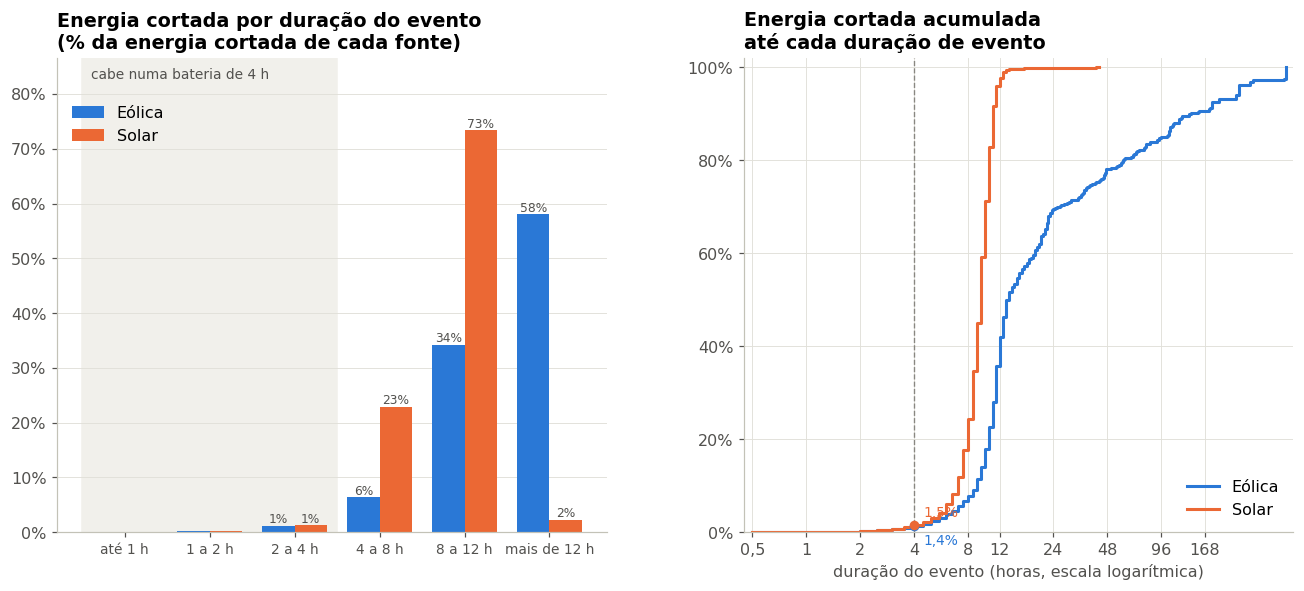

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.6), gridspec_kw={"wspace": 0.25})
largura = 0.38
xs_base = np.arange(len(FAIXAS_DURACAO))
n_bateria = sum(1 for i, f in enumerate(FAIXAS_DURACAO) if FAIXAS_LIMITES[i + 1] <= DURACAO_BATERIA_H)
ax1.axvspan(-0.5, n_bateria - 0.5, color="#f1f0eb", zorder=0)
ax1.text(-0.4, 0.98, f"cabe numa bateria de {DURACAO_BATERIA_H} h", transform=ax1.get_xaxis_transform(), va="top",
         fontsize=9, color=TINTA_2)
for k, fonte in enumerate(FONTES):
    serie = p5_faixa[p5_faixa["fonte"] == fonte].set_index("faixa_duracao").reindex(FAIXAS_DURACAO)
    xs = xs_base + (k - 0.5) * largura
    ax1.bar(xs, serie["pct_energia"].fillna(0), width=largura, color=COR_FONTE[fonte], label=NOME_FONTE[fonte])
    for xx, v in zip(xs, serie["pct_energia"].fillna(0)):
        if v >= 1:
            ax1.text(xx, v, pct(v, 0), ha="center", va="bottom", fontsize=8, color=TINTA_2)
ax1.set_xticks(xs_base, FAIXAS_DURACAO, fontsize=9)
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: pct(v, 0)))
ax1.set_title("Energia cortada por duração do evento\n(% da energia cortada de cada fonte)")
ax1.set_ylim(0, 1.18 * p5_faixa["pct_energia"].max())
ax1.legend(loc="upper left", bbox_to_anchor=(0.0, 0.93))
ax1.grid(axis="x", visible=False)

for fonte in FONTES:
    serie = p5_dist[p5_dist["fonte"] == fonte].sort_values("intervalos")
    if serie.empty:
        continue
    horas = np.r_[0.5, 0.5 * serie["intervalos"].to_numpy()]
    acumulado = np.r_[0.0, 100 * serie["cortada_mwh"].cumsum().to_numpy() / serie["cortada_mwh"].sum()]
    ax2.step(horas, acumulado, where="post", color=COR_FONTE[fonte], lw=2, label=NOME_FONTE[fonte])
    ate = acumulado[horas <= DURACAO_BATERIA_H]
    if len(ate):
        ax2.scatter([DURACAO_BATERIA_H], [ate[-1]], color=COR_FONTE[fonte], zorder=4, s=28)
        ax2.annotate(pct(ate[-1]), (DURACAO_BATERIA_H, ate[-1]), xytext=(6, -12 if fonte == "eolica" else 6),
                     textcoords="offset points", fontsize=9, color=COR_FONTE[fonte])
ax2.axvline(DURACAO_BATERIA_H, color=CINZA, lw=0.9, ls="--")
ax2.set_xscale("log")
marcas = [0.5, 1, 2, 4, 8, 12, 24, 48, 96, 168]
ax2.set_xticks(marcas, [num(m, 1 if m < 1 else 0) for m in marcas])
ax2.xaxis.set_minor_locator(mtick.NullLocator())
ax2.set_xlim(0.45, max(200, 0.5 * p5_dist["intervalos"].max() * 1.1))
ax2.set_ylim(0, 102)
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: pct(v, 0)))
ax2.set_xlabel("duração do evento (horas, escala logarítmica)")
ax2.set_title("Energia cortada acumulada\naté cada duração de evento")
ax2.legend(loc="lower right")
salvar_figura(fig, "p5_duracao_dos_eventos")
plt.show()

In [38]:
duracoes = {f: np.repeat(0.5 * p5_dist.loc[p5_dist["fonte"] == f, "intervalos"].to_numpy(),
                         p5_dist.loc[p5_dist["fonte"] == f, "eventos"].to_numpy()) for f in FONTES}
if all(len(d) > 0 for d in duracoes.values()) and len(FONTES) == 2:
    _, p_mw = stats.mannwhitneyu(*duracoes.values(), alternative="two-sided")
else:
    p_mw = np.nan
tot5 = p5[["eventos", "eventos_cabem_bateria", "cortada_mwh", "cortada_cabe_bateria_mwh"]].sum()
pct_energia_bateria = 100 * tot5["cortada_cabe_bateria_mwh"] / tot5["cortada_mwh"]
pct_eventos_bateria = 100 * tot5["eventos_cabem_bateria"] / tot5["eventos"]
r5 = p5.set_index("fonte")
texto = (f"Foram identificados **{num(tot5['eventos'])} eventos de corte** com perda de energia. "
         f"**{pct(pct_eventos_bateria)} dos eventos duram até {DURACAO_BATERIA_H} h**, mas eles concentram só "
         f"**{pct(pct_energia_bateria)} da energia cortada**: os eventos longos são poucos e pesam muito. "
         + " ".join(f"{NOME_FONTE[f]}: duração mediana de {num(r5.loc[f, 'duracao_mediana_h'], 1)} h, P90 de "
                    f"{num(r5.loc[f, 'duracao_p90_h'], 1)} h e máximo de {num(r5.loc[f, 'duracao_maxima_h'], 0)} h; "
                    f"{pct(r5.loc[f, 'pct_energia_cabe_bateria'])} da energia em eventos de até {DURACAO_BATERIA_H} h."
                    for f in FONTES if f in r5.index)
         + (f" As durações das duas fontes {'diferem significativamente' if p_mw < 0.05 else 'não diferem significativamente'} "
            f"(Mann-Whitney, {fp(p_mw)})." if pd.notna(p_mw) else "")
         + f" Uma bateria de {DURACAO_BATERIA_H} h junto a cada usina recuperaria, no limite teórico, "
         f"**{energia(tot5['cortada_cabe_bateria_mwh'])}** por ano.")
RESUMO["P5"] = texto
RES["P5"] = {"pct_energia_bateria": pct_energia_bateria, "pct_eventos_bateria": pct_eventos_bateria, "p_mw": p_mw,
             **{f"mediana_{f}": r5.loc[f, "duracao_mediana_h"] for f in FONTES if f in r5.index}}
mostrar("**Leitura automática — P5.** " + texto)

**Leitura automática — P5.** Foram identificados **64.439 eventos de corte** com perda de energia. **10,7% dos eventos duram até 4 h**, mas eles concentram só **1,4% da energia cortada**: os eventos longos são poucos e pesam muito. Eólica: duração mediana de 10,0 h, P90 de 17,5 h e máximo de 477 h; 1,4% da energia em eventos de até 4 h. Solar: duração mediana de 8,5 h, P90 de 10,5 h e máximo de 43 h; 1,5% da energia em eventos de até 4 h. As durações das duas fontes diferem significativamente (Mann-Whitney, p < 0,001). Uma bateria de 4 h junto a cada usina recuperaria, no limite teórico, **524,7 GWh** por ano.

**Discussão (P5).** A duração separa dois problemas que pedem soluções diferentes. Eventos **curtos e frequentes** (algumas horas por dia, típicos do meio-dia) são o terreno das **baterias de curta duração**, que carregam durante o corte e devolvem a energia no fim da tarde, quando a carga sobe e o sol se põe. Eventos **longos** (vários dias seguidos, típicos de restrições elétricas por indisponibilidade de equipamentos ou de períodos de vento forte com carga baixa) não cabem numa bateria de 4 horas. Para eles, a resposta é **transmissão**, **armazenamento de longa duração** (como hidrelétricas reversíveis) ou **coordenação da expansão**. A diferença entre a parcela de **eventos** e a parcela de **energia** de até 4 horas é o resultado mais importante desta pergunta: olhar só a contagem de eventos superestimaria o potencial das baterias. **Decisão apoiada:** avaliar baterias onde o corte é curto e recorrente, e não usá-las como resposta geral ao problema.

## 10. Discussão geral e avaliação das hipóteses

Os critérios definidos na Seção 1.4, antes da análise, são avaliados agora contra os resultados.

In [39]:
r1, r2, r3, r4, r5 = (RES[k] for k in ["P1", "P2", "P3", "P4", "P5"])
veredito = lambda ok: "Confirmada" if ok else "Não confirmada"
hipoteses = pd.DataFrame([
    {"hipotese": "H1 — o corte é relevante", "criterio": "energia cortada ≥ 10% do potencial em pelo menos uma fonte",
     "resultado": f"eólica {pct(r1['pct_eolica'])} · solar {pct(r1['pct_solar'])}", "veredito": veredito(r1["pct_max"] >= 10)},
    {"hipotese": "H2 — o corte é concentrado em poucas usinas", "criterio": "≤ 20% das usinas respondem por 80% da energia cortada",
     "resultado": f"{num(r2['n80'])} de {num(r2['n_usinas'])} usinas ({pct(r2['pct_usinas_80'])})",
     "veredito": veredito(r2["pct_usinas_80"] <= 20)},
    {"hipotese": "H3 — predomina o motivo energético", "criterio": "motivo ENE ≥ 50% da energia cortada",
     "resultado": f"ENE {pct(r3['pct_ene'])} · elétricos (REL + CNF) {pct(r3['pct_eletrico'])}",
     "veredito": veredito(r3["pct_ene"] >= 50)},
    {"hipotese": "H4 — o corte se concentra no meio do dia",
     "criterio": f"≥ 70% da energia cortada entre {HORA_INICIO_MEIO_DIA:02d}h00 e {HORA_FIM_MEIO_DIA - 1:02d}h59",
     "resultado": f"{pct(r4['pct_meio_dia'])} da energia cortada", "veredito": veredito(r4["pct_meio_dia"] >= 70)},
    {"hipotese": f"H5 — baterias de {DURACAO_BATERIA_H} h absorveriam a maior parte",
     "criterio": f"≥ 50% da energia cortada em eventos de até {DURACAO_BATERIA_H} h",
     "resultado": f"{pct(r5['pct_energia_bateria'])} da energia ({pct(r5['pct_eventos_bateria'])} dos eventos)",
     "veredito": veredito(r5["pct_energia_bateria"] >= 50)},
])
salvar_tabela(hipoteses, "d1_avaliacao_hipoteses")
display(hipoteses)

# Peso relativo de cada alavanca, a partir dos próprios resultados
peso_transmissao = r3["pct_eletrico"]
peso_gestao = r3["pct_ene"]
alavanca_principal = ("gestão de oferta e demanda e armazenamento" if peso_gestao >= peso_transmissao else "transmissão")
sintese = (f"**Síntese.** Em {ANO}, {energia(r1['cortada_mwh'])} de energia eólica e solar deixaram de ser gerados "
           f"({pct(r1['pct_total'])} do potencial; eólica {pct(r1['pct_eolica'])}, solar {pct(r1['pct_solar'])}). "
           f"O corte é geograficamente concentrado ({r2['uf_top']} responde por {pct(r2['share_uf_top'])}, o Nordeste por "
           f"{pct(r2['share_ne'])}) e {'concentrado' if r2['pct_usinas_80'] <= 20 else 'pouco concentrado'} entre usinas "
           f"({pct(r2['pct_usinas_80'])} das usinas somam 80% do corte). "
           f"O motivo energético responde por {pct(r3['pct_ene'])} e os elétricos por {pct(r3['pct_eletrico'])}: a alavanca de maior peso é "
           f"**{alavanca_principal}**. {pct(r4['pct_meio_dia'])} do corte acontece entre {HORA_INICIO_MEIO_DIA:02d}h e "
           f"{HORA_FIM_MEIO_DIA:02d}h, e domingos e feriados têm {num(r4['razao_domingo'], 2)} vez(es) o corte de um dia útil. "
           f"Eventos de até {DURACAO_BATERIA_H} h são {pct(r5['pct_eventos_bateria'])} dos eventos, mas só {pct(r5['pct_energia_bateria'])} da energia: "
           + ("baterias de curta duração resolvem a maior parte do problema." if r5["pct_energia_bateria"] >= 50 else
              "baterias de curta duração ajudam, mas não resolvem sozinhas; os eventos longos pedem rede ou armazenamento de longa duração."))
RESUMO["sintese"] = sintese
mostrar(sintese)

,hipotese,criterio,resultado,veredito
0,H1 — o corte é relevante,energia cortada ≥ 10% do potencial em pelo menos uma fonte,"eólica 19,1% · solar 25,7%",Confirmada
1,H2 — o corte é concentrado em poucas usinas,≤ 20% das usinas respondem por 80% da energia cortada,"107 de 235 usinas (45,5%)",Não confirmada
2,H3 — predomina o motivo energético,motivo ENE ≥ 50% da energia cortada,"ENE 53,9% · elétricos (REL + CNF) 46,1%",Confirmada
3,H4 — o corte se concentra no meio do dia,≥ 70% da energia cortada entre 09h00 e 15h59,"61,7% da energia cortada",Não confirmada
4,H5 — baterias de 4 h absorveriam a maior parte,≥ 50% da energia cortada em eventos de até 4 h,"1,4% da energia (10,7% dos eventos)",Não confirmada


**Síntese.** Em 2025, 37,22 TWh de energia eólica e solar deixaram de ser gerados (20,7% do potencial; eólica 19,1%, solar 25,7%). O corte é geograficamente concentrado (RN responde por 31,4%, o Nordeste por 84,3%) e pouco concentrado entre usinas (45,5% das usinas somam 80% do corte). O motivo energético responde por 53,9% e os elétricos por 46,1%: a alavanca de maior peso é **gestão de oferta e demanda e armazenamento**. 61,7% do corte acontece entre 09h e 16h, e domingos e feriados têm 1,64 vez(es) o corte de um dia útil. Eventos de até 4 h são 10,7% dos eventos, mas só 1,4% da energia: baterias de curta duração ajudam, mas não resolvem sozinhas; os eventos longos pedem rede ou armazenamento de longa duração.

**Como as respostas se encadeiam.** P1 dimensiona o problema. P2 mostra **onde** ele está e se dá para atacá-lo de forma localizada. P3 mostra **por que** acontece e, com isso, qual alavanca tem mais peso. P4 e P5 mostram **quando** e **por quanto tempo**, que é o que define se deslocar consumo ou armazenar energia funciona. Juntas, as respostas permitem dividir o esforço entre as três alavancas da Seção 1.2 com base em evidência.

| Alavanca | Quando é a resposta certa | Evidência neste MVP |
|---|---|---|
| **Transmissão** (obras de rede, reforços de conexão) | Corte elétrico (REL, CNF), local e concentrado em poucas usinas ou pontos de conexão | P2 (concentração), P3 (natureza e origem), P5 (eventos longos) |
| **Armazenamento** (baterias de 4 h, junto às usinas ou na rede) | Corte recorrente, de poucas horas, previsível | P4 (horário), P5 (energia em eventos curtos) |
| **Gestão de oferta e demanda** (preço por horário, resposta da demanda, coordenação da expansão e da geração distribuída) | Corte energético e sistêmico, concentrado em horas de carga baixa | P3 (ENE, SIS), P4 (meio-dia, domingos e feriados) |

A leitura automática acima indica qual alavanca tem mais peso **nos dados de 2025**. A tabela de hipóteses mostra o que se confirmou; uma hipótese não confirmada rebaixa a alavanca correspondente.

**O que os dados não permitem concluir.** A análise é **descritiva**. A energia cortada depende da **geração de referência**, que o próprio ONS estima com modelos de vento e irradiação, e por isso carrega incerteza de modelo. A base não traz preços, então o prejuízo financeiro não é calculado aqui. A **geração distribuída** não é cortada e não aparece, embora contribua para o excesso de oferta ao meio-dia. Por fim, os motivos são os registrados pelo ONS: a classificação de um corte como "energético" ou "elétrico" é do operador, não deste trabalho.

## 11. Viabilidade financeira — custo de operação

A dimensão financeira do MVP é medida, e não suposta: o notebook registra o job e os bytes processados por **cada** consulta, além do armazenamento ocupado no BigQuery e no Drive.

,recurso,uso_medido,franquia_gratuita,pct_da_franquia,custo_usd_sem_franquia
0,BigQuery — consultas (uma execução completa),"1.395,1 MB em 13 consultas",1 TiB por mês,0.133044,0.008315
1,BigQuery — armazenamento,"556,6 MB",10 GiB,5.435690,0.010871
2,Google Drive — Data Lake e evidências,"289,6 MB",15 GB (conta Google),2.024200,0.000000
3,Google Colab — processamento,1 sessão de CPU,uso gratuito com limites,NaN,0.000000


Figura salva em /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/imagens/e5_consultas_bigquery.png


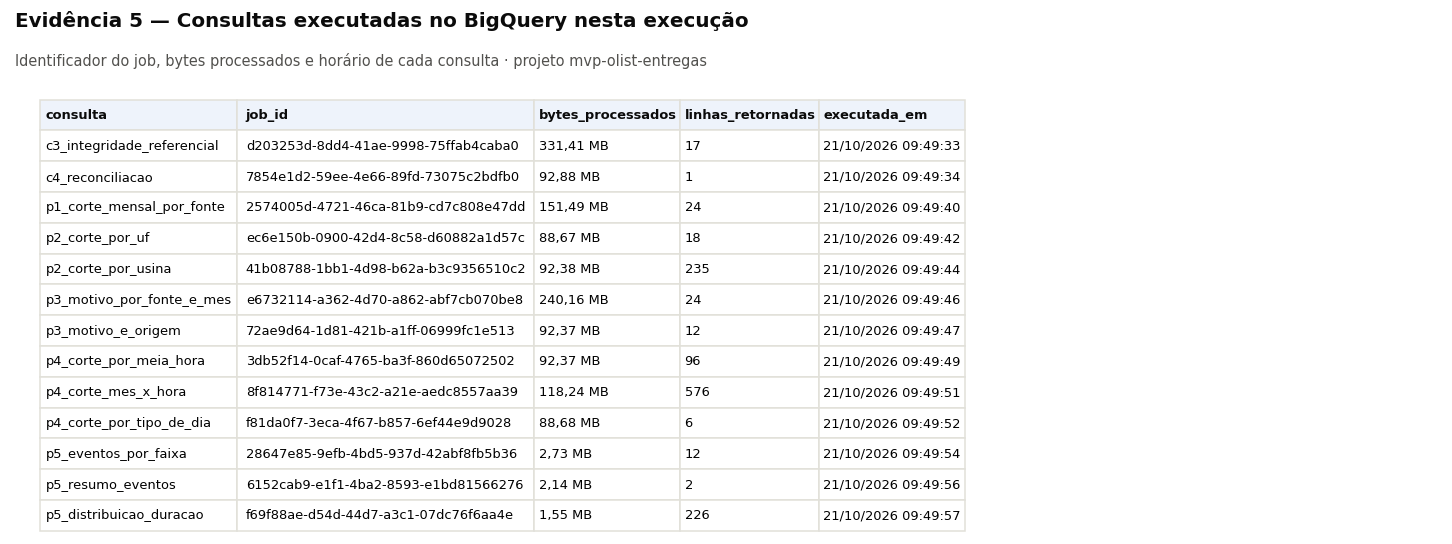

Uma execução completa processa **1.395,1 MB** no BigQuery e ocupa **556,6 MB** de armazenamento: 0,133% e 5,44% das franquias gratuitas. Mesmo com 30 execuções por mês, o consumo seria de 3,99% da franquia de consultas. **Custo operacional: US$ 0,00.** Sem franquia, uma execução custaria cerca de US$ 0,0083 em consultas e o armazenamento, US$ 0,0109 por mês: valores irrelevantes diante de um problema medido em milhões de MWh e bilhões de reais.

In [40]:
consultas = pd.DataFrame(LOG_CONSULTAS)
salvar_tabela(consultas, "f1_consultas_bigquery")
bytes_consultas = int(consultas["bytes_processados"].sum())
armazenamento_bq = int(sum(client.get_table(f"{PROJECT_ID}.{DATASET_BQ}.{n}").num_bytes for n in log_carga["tabela"]))
tamanho_drive = sum(os.path.getsize(os.path.join(raiz, a)) for raiz, _, arqs in os.walk(PASTA_DRIVE) for a in arqs)
TIB, GIB, MB = 2**40, 2**30, 2**20
custos = pd.DataFrame([
    {"recurso": "BigQuery — consultas (uma execução completa)", "uso_medido": f"{num(bytes_consultas / MB, 1)} MB em {len(consultas)} consultas",
     "franquia_gratuita": "1 TiB por mês", "pct_da_franquia": 100 * bytes_consultas / TIB,
     "custo_usd_sem_franquia": bytes_consultas / TIB * PRECO_USD_POR_TIB},
    {"recurso": "BigQuery — armazenamento", "uso_medido": f"{num(armazenamento_bq / MB, 1)} MB",
     "franquia_gratuita": "10 GiB", "pct_da_franquia": 100 * armazenamento_bq / (10 * GIB),
     "custo_usd_sem_franquia": armazenamento_bq / GIB * 0.02},
    {"recurso": "Google Drive — Data Lake e evidências", "uso_medido": f"{num(tamanho_drive / MB, 1)} MB",
     "franquia_gratuita": "15 GB (conta Google)", "pct_da_franquia": 100 * tamanho_drive / 15e9,
     "custo_usd_sem_franquia": 0.0},
    {"recurso": "Google Colab — processamento", "uso_medido": "1 sessão de CPU",
     "franquia_gratuita": "uso gratuito com limites", "pct_da_franquia": np.nan, "custo_usd_sem_franquia": 0.0},
])
salvar_tabela(custos, "f2_custos")
display(custos.round(6))

imagem_evidencia(consultas.assign(bytes_processados=consultas["bytes_processados"].map(lambda b: f"{num(b / MB, 2)} MB"))
                 [["consulta", "job_id", "bytes_processados", "linhas_retornadas", "executada_em"]],
                 "Evidência 5 — Consultas executadas no BigQuery nesta execução",
                 f"Identificador do job, bytes processados e horário de cada consulta · projeto {PROJECT_ID}",
                 "e5_consultas_bigquery", largura_max=60)

execucoes_mes = 30
texto = (f"Uma execução completa processa **{num(bytes_consultas / MB, 1)} MB** no BigQuery e ocupa **{num(armazenamento_bq / MB, 1)} MB** "
         f"de armazenamento: {pct(100 * bytes_consultas / TIB, 3)} e {pct(100 * armazenamento_bq / (10 * GIB), 2)} das franquias gratuitas. "
         f"Mesmo com {execucoes_mes} execuções por mês, o consumo seria de {pct(100 * execucoes_mes * bytes_consultas / TIB, 2)} "
         f"da franquia de consultas. **Custo operacional: US$ 0,00.** Sem franquia, uma execução custaria cerca de "
         f"US$ {num(bytes_consultas / TIB * PRECO_USD_POR_TIB, 4)} em consultas e o armazenamento, US$ {num(armazenamento_bq / GIB * 0.02, 4)} "
         "por mês: valores irrelevantes diante de um problema medido em milhões de MWh e bilhões de reais.")
RESUMO["custos"] = texto
mostrar(texto)

Os preços de referência (US$ 6,25 por TiB processado; US$ 0,02 por GiB armazenado por mês) são os valores públicos do BigQuery sob demanda e devem ser conferidos na página oficial de preços do Google Cloud na data de uso. O **sandbox** dispensa cartão de crédito. Em troca, faz as tabelas expirarem em 60 dias, o que exige recarga periódica a partir da camada *gold* do Drive, e não aceita DML.

## 12. Autoavaliação

**Quais perguntas foram respondidas e quais não foram? Por quê?**

| Pergunta | Situação | Observação |
|---|---|---|
| P1 — quanto se corta e evolução | Respondida | Energia e percentual por fonte e mês, com comparação com estimativa externa. |
| P2 — onde se corta | Respondida | Por UF, subsistema, usina e agente. O ponto de conexão está na `dim_usina`, mas não foi analisado separadamente. |
| P3 — por que se corta | Respondida, com ressalva | Depende da classificação de motivo feita pelo ONS e do rateio por minutos (R09); a parcela sem motivo é medida. |
| P4 — quando se corta | Respondida | Perfil horário, mês × hora e tipo de dia. Não cruza com a carga do SIN, que está em outro conjunto do ONS. |
| P5 — quanto duram os cortes e potencial de baterias | Parcialmente | A duração é medida; o potencial das baterias é um limite teórico (sem simular carga e descarga). |

**Que limitações dos dados condicionaram os resultados?**

* **Geração de referência estimada:** a energia cortada vem da diferença entre o que o ONS estima que a usina geraria e o que ela gerou. É um valor modelado, não medido.
* **Cobertura:** só as usinas despachadas ou programadas pelo ONS (Tipo I, II-B e II-C). A geração distribuída, que cresce muito e pressiona o meio-dia, fica de fora.
* **Revisões:** o ONS revisa meses já publicados. O pipeline registra o `ETag` de cada arquivo para detectar revisões, mas os números podem mudar entre execuções.
* **Motivo e descrição:** a descrição textual da restrição só existe a partir de setembro de 2025 e não foi usada; parte dos intervalos restritos não tem motivo informado.
* **Sem preços:** o prejuízo em reais exigiria o Preço de Liquidação das Diferenças (PLD) e as regras de ressarcimento, fora do escopo.

**Que decisões técnicas eu tomaria de outra forma?**

* Usaria **carga incremental por mês** com `MERGE` (BigQuery com faturamento ou Databricks com Delta Lake), reprocessando só os meses cujo `ETag` mudou.
* **Particionaria** a `fato_restricao` por mês. No *sandbox* isso não é viável: as partições expiram 60 dias depois da **data da partição**, e as de 2025 seriam apagadas na hora.
* Declararia as regras de qualidade como **testes automatizados** (dbt tests ou Great Expectations) executados a cada carga.
* Separaria coleta, transformação, carga e análise em módulos orquestrados por um agendador.

**Que extensões transformariam este MVP em uma solução de uso contínuo?**

1. **Ingestão mensal agendada** (Cloud Scheduler + Cloud Run) com detecção de revisões pelo `ETag`.
2. **Integração com a carga e o PLD** (também em ONS Dados Abertos e na CCEE), para medir a carga líquida no momento do corte e valorar a energia perdida.
3. **Painel no Looker Studio** conectado ao dataset, com alertas quando o percentual cortado de uma usina ou UF passa de um limite.
4. **Simulação de baterias** com a série semi-horária (estado de carga, potência e eficiência), para passar do limite teórico da P5 a uma estimativa de energia recuperável e de receita.

**Dificuldades encontradas.** Entender a semântica das colunas (potência média × energia, geração de referência × referência final, minutos por motivo sem coluna para PAR) a partir dos dicionários do ONS. Escolher o grão e criar a segunda fato para responder à pergunta sobre duração. Lidar com o volume (milhões de linhas semi-horárias) dentro da memória do Colab gratuito, tipando as colunas no próprio DataFrame e liberando a bronze depois da transformação. E aplicar lições de um projeto anterior com a mesma arquitetura: validar o projeto do Google Cloud logo no início, evitar nomes de variáveis que colidem com funções de bibliotecas e gerar as evidências visuais automaticamente, a partir das próprias plataformas.

## 13. Exportação das evidências e referências

A célula abaixo grava a leitura automática dos resultados em `evidencias/resultados_resumo.md`, os números-chave em `evidencias/resultados_numeros.json` e compacta gráficos, imagens de evidência, tabelas, catálogo, SQL executado e metadados num `.zip` que **já segue a estrutura do repositório**. O `.zip` fica na pasta do projeto no Drive (`PASTA_DRIVE`) e é baixado automaticamente.

**Para publicar no GitHub:** (1) depois de executar tudo, use **Arquivo → Salvar uma cópia no GitHub** para versionar este notebook **com as saídas**, na raiz do repositório; (2) descompacte o `.zip` na raiz do repositório.

In [41]:
caminho_resumo = os.path.join(PASTA_DRIVE, "evidencias", "resultados_resumo.md")
with open(caminho_resumo, "w", encoding="utf-8") as arq:
    arq.write(f"# Resultados — leitura automática\n\n_Gerado em {AGORA:%d/%m/%Y %H:%M} (UTC-3) a partir da execução do notebook "
              f"(dados de {ANO}, coletados em {AGORA:%d/%m/%Y})._\n\n")
    for chave in ["P1", "P2", "P3", "P4", "P5"]:
        arq.write(f"## {chave}\n\n{RESUMO[chave]}\n\n")
    arq.write("## Avaliação das hipóteses\n\n" + tabela_markdown(hipoteses) + "\n\n")
    arq.write("## Síntese\n\n" + RESUMO["sintese"].replace("**Síntese.** ", "") + "\n\n")
    arq.write("## Custo de operação\n\n" + RESUMO["custos"] + "\n")

def serializavel(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return None if np.isnan(v) else round(float(v), 4)
    return v
with open(os.path.join(PASTA_DRIVE, "evidencias", "resultados_numeros.json"), "w", encoding="utf-8") as arq:
    json.dump({"gerado_em": AGORA.isoformat(timespec="seconds"), "ano": ANO, "cobertura_pct": serializavel(cob_media),
               **{k: {c: serializavel(v) for c, v in d.items()} for k, d in RES.items()},
               "hipoteses": hipoteses.to_dict(orient="records"),
               "integridade_ok": f"{int((integridade['status'] == 'OK').sum())}/{len(integridade)}",
               "reconciliacao_ok": f"{int((reconciliacao['status'] == 'OK').sum())}/{len(reconciliacao)}",
               "tabelas_bigquery": log_carga[["tabela", "linhas_bigquery", "tamanho_mb"]].to_dict(orient="records")},
              arq, ensure_ascii=False, indent=2, default=str)

# O .zip espelha a estrutura do repositório: basta descompactá-lo na raiz do projeto
arquivo_zip = os.path.join(PASTA_DRIVE, "evidencias_mvp_cortes_ons.zip")
destino_no_repo = {"evidencias": "evidencias", "catalogo": "catalogo", "sql": "scripts/sql", "metadados": "evidencias/metadados"}
with zipfile.ZipFile(arquivo_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for pasta, destino in destino_no_repo.items():
        for raiz, _, arquivos_zip in os.walk(os.path.join(PASTA_DRIVE, pasta)):
            for a in arquivos_zip:
                caminho = os.path.join(raiz, a)
                z.write(caminho, os.path.join(destino, os.path.relpath(caminho, os.path.join(PASTA_DRIVE, pasta))))
shutil.copy(arquivo_zip, "/content/evidencias_mvp_cortes_ons.zip")
print("Resumo:", caminho_resumo)
print("Pacote de evidências:", arquivo_zip, f"({num(os.path.getsize(arquivo_zip) / 2**20, 1)} MB)")
try:
    from google.colab import files
    files.download("/content/evidencias_mvp_cortes_ons.zip")
except Exception as erro:
    print("Download automático indisponível; o .zip está no Drive:", erro)

Resumo: /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias/resultados_resumo.md
Pacote de evidências: /content/drive/MyDrive/mvp_cortes_renovaveis/evidencias_mvp_cortes_ons.zip (2,6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Referências

* OPERADOR NACIONAL DO SISTEMA ELÉTRICO (ONS). *Restrição de Operação por Constrained-off de Usinas Eólicas* e *de Usinas Fotovoltaicas*. Portal ONS Dados Abertos. Disponível em: <https://dados.ons.org.br/dataset/restricao_coff_eolica_usi> e <https://dados.ons.org.br/dataset/restricao_coff_fotovoltaica_usi>. Licença Creative Commons Atribuição (CC BY).
* ONS. *Dicionário de Dados — Restrição de Operação por Constrained-off de Usinas Eólicas e Fotovoltaicas*. Baixados pelo pipeline em `bronze/ons/dicionarios/`.
* ONS. *RT DGL-ONS 0189/2025 — GT Curtailment*. Disponível em: <https://www.ons.org.br/AcervoDigitalDocumentosEPublicacoes/RT%20DGL-ONS%200189-2025%20-%20GT%20Curtailment%20rev1.pdf>.
* CANAL SOLAR. Reportagem sobre o estudo da Volt Robotics a respeito do prejuízo estimado com cortes de geração em 2025. 23 set. 2025. Disponível em: <https://canalsolar.com.br/cortes-geracao-prejuizo-estimado-32-bi-2025/>.
* KIMBALL, R.; ROSS, M. *The Data Warehouse Toolkit: The Definitive Guide to Dimensional Modeling*. 3. ed. Wiley, 2013.
* GOOGLE CLOUD. *BigQuery sandbox* e *BigQuery pricing*. Disponível em: <https://cloud.google.com/bigquery/docs/sandbox> e <https://cloud.google.com/bigquery/pricing>.
* BRASIL. Lei nº 13.709, de 14 de agosto de 2018 — Lei Geral de Proteção de Dados Pessoais (LGPD).
* BRASIL. Lei nº 14.759, de 21 de dezembro de 2023 (Dia Nacional de Zumbi e da Consciência Negra como feriado nacional).